In [15]:


"""
Simulation Log Parser + Pillar-Targeting Distribution Plot
===========================================================
Automatically discovers every versioned run folder (v1, v2, v3, …).

Directory layout
────────────────
INPUT  (one folder per run):
    <PROJECT_ROOT>/SimulationLogs/PROVIDER/ZeroShot/stateful/vision-4/
        AgentsLogging/simulation_log/unstructured/v<N>/step_*.txt

OUTPUT (mirrored, one folder per run):
    <PROJECT_ROOT>/SimulationLogs/PROVIDER/ZeroShot/stateful/vision-4/
        AgentsLogging/simulation_log/structured/activists_logs/v<N>/
            parsed_simulation_log.csv
            pillar_targeting_distribution.png

Usage
─────
    python parse_and_plot_logs.py
"""

import ast
import csv
import glob
import json
import os
import re
from collections import Counter, defaultdict
from pathlib import Path

# ─────────────────────────────────────────────────────────────────────────────
# DIRECTORY CONFIGURATION
# ─────────────────────────────────────────────────────────────────────────────

PROJECT_ROOT = Path.cwd().parent
PROVIDER = "Qwen2.5-32B-Instruct-AWQ_ZeroShot"
PROVIDER = "llama3.1-8B-Instruct_CoT"
PROVIDER = "llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot"
PROVIDER = "qwen3-8B_ZeroShot"
PROMPT_TYPE = "ZeroShot"
_LOGS_BASE = (
    PROJECT_ROOT
    / "SimulationLogs" / PROVIDER / PROMPT_TYPE
    / "stateful"       / "vision-4"
    / "AgentsLogging"  / "simulation_log"
)

# Base directories — NO v* here; version suffix is appended at runtime
DIRS = {
    # Root that contains v1/, v2/, v3/, … sub-directories of raw step logs
    "agent_dir":        _LOGS_BASE / "unstructured",

    # Root where structured output folders v1/, v2/, … will be created
    "agent_output_dir": _LOGS_BASE / "structured",
}

# File name templates — {v} is replaced with the version label at runtime
# All files land directly in DIRS["agent_output_dir"] with no sub-folders.
# Wrap the first string in Path() so the "/" operator works correctly
OUTPUT_CSV_TPL  = "activists_logs/activists_logs_{v}.csv"
OUTPUT_PLOT_TPL = "pillars_interaction/pillar_targeting_distribution_{v}.png"


# ─────────────────────────────────────────────────────────────────────────────
# REGEX PATTERNS
# ─────────────────────────────────────────────────────────────────────────────

FIELD_PATTERN = re.compile(
    r"""
    (?P<key>[a-zA-Z_]+)
    =
    (?P<value>
        "(?:[^"\\]|\\.)*"       # double-quoted string
        |'(?:[^'\\]|\\.)*'      # single-quoted string
        |\([^)]*\)               # tuple  (x, y)
        |[^;{]+                  # plain value
    )
    """,
    re.VERBOSE,
)

# CONTEXT_PATTERN = re.compile(r"context=(\{.*\})$", re.DOTALL)
CONTEXT_PATTERN = re.compile(r"context=\s*(\{.*\})\s*$", re.DOTALL)
MEMORY_PATTERN  = re.compile(r"memory=(\{.*?\}(?:\}|\s*\}))", re.DOTALL)


# ─────────────────────────────────────────────────────────────────────────────
# PARSING HELPERS
# ─────────────────────────────────────────────────────────────────────────────

def _clean(v: str) -> str:
    v = v.strip()
    if (v.startswith('"') and v.endswith('"')) or \
       (v.startswith("'") and v.endswith("'")):
        return v[1:-1]
    return v


def _parse_tuple(v: str):
    try:
        return ast.literal_eval(v.strip())
    except Exception:
        return v.strip()


def parse_line(line: str) -> dict | None:
    line = line.strip()
    if not line:
        return None

    record = {}

    # 1. Peel off context={...} JSON blob
    ctx_match = CONTEXT_PATTERN.search(line)
    if ctx_match:
        json_str = ctx_match.group(1).strip()
        try:
            # Try standard JSON first (Fastest)
            record["context"] = json.loads(json_str)
        except json.JSONDecodeError:
            try:
                # Fallback for Python-style single quotes
                record["context"] = ast.literal_eval(json_str)
            except (ValueError, SyntaxError):
                record["context_raw"] = json_str
                
    # if ctx_match:
    #     try:
    #         record["context"] = json.loads(ctx_match.group(1))
    #     except json.JSONDecodeError:
    #         record["context_raw"] = ctx_match.group(1)
        line = line[: ctx_match.start()]

    # 2. Peel off memory={...} Python-dict blob
    mem_match = MEMORY_PATTERN.search(line)
    if mem_match:
        try:
            record["memory"] = ast.literal_eval(mem_match.group(1))
        except Exception:
            record["memory_raw"] = mem_match.group(1)
        line = line[: mem_match.start()]

    # 3. Parse remaining key=value fields
    for m in FIELD_PATTERN.finditer(line):
        record[m.group("key")] = _clean(m.group("value"))

    if not record:
        return None

    # 4. Type coercions
    for k in ("Step", "agent_id", "response_tokens"):
        if k in record:
            try:
                record[k] = int(record[k])
            except (ValueError, TypeError):
                pass

    if "elapsed" in record:
        try:
            record["elapsed"] = float(str(record["elapsed"]).rstrip("s"))
        except (ValueError, TypeError):
            pass

    for k in ("pos", "from_pos", "to_pos"):
        if k in record:
            record[k] = _parse_tuple(record[k])

    return record


# def parse_step_file(filepath: str, step_number: int) -> list[dict]:
#     records = []
#     with open(filepath, "r", encoding="utf-8", errors="replace") as fh:
#         for line in fh:
#             rec = parse_line(line)
#             if rec:
#                 rec.setdefault("Step", step_number)
#                 records.append(rec)
#     return records


def parse_step_file(filepath: str, step_number: int) -> list[dict]:
    records = []
    pending: dict | None = None  # holds the current incomplete record

    with open(filepath, "r", encoding="utf-8", errors="replace") as fh:
        for line in fh:
            rec = parse_line(line)
            if not rec:
                continue

            rec.setdefault("Step", step_number)

            # ── A "primary" line has agent_id + event ────────────────────────
            is_primary = bool(rec.get("agent_id") and rec.get("event"))

            if is_primary:
                # Flush the previous pending record before starting a new one
                if pending is not None:
                    records.append(pending)
                pending = rec

            else:
                # Continuation line — merge into pending if one exists
                if pending is not None:
                    for k, v in rec.items():
                        # Fill missing fields; never overwrite populated ones
                        if v and not pending.get(k):
                            pending[k] = v
                    # Deep-merge context dicts if both sides have one
                    if isinstance(rec.get("context"), dict) and \
                       isinstance(pending.get("context"), dict):
                        pending["context"] = {
                            **rec["context"],
                            **pending["context"],  # existing keys win
                        }
                else:
                    # Orphan continuation with no parent — emit as-is
                    records.append(rec)

    # Flush the last pending record
    if pending is not None:
        records.append(pending)

    return records

def _step_num(path: str) -> int:
    m = re.search(r"step_(\d+)\.txt$", path, re.IGNORECASE)
    return int(m.group(1)) if m else 0


def parse_all_steps(unstructured_dir: Path) -> list[dict]:
    """Parse every step_*.txt inside *unstructured_dir*."""
    files = sorted(
        glob.glob(str(unstructured_dir / "step_*.txt")),
        key=_step_num,
    )
    if not files:
        raise FileNotFoundError(
            f"No step_*.txt files found in:\n  {unstructured_dir}"
        )
    print(f"  Found {len(files)} step files — parsing …")
    records = []
    for fp in files:
        records.extend(parse_step_file(fp, _step_num(fp)))
    print(f"  Parsed {len(records):,} log records.")
    return records


# ─────────────────────────────────────────────────────────────────────────────
# VALIDATION HELPER
# ─────────────────────────────────────────────────────────────────────────────

def validate_target(rec: dict) -> str:
    """
    Checks if the target_agent or target_pillar exists in the context neighborhood.
    Returns: 'valid', 'invalid', or 'no_target'
    """
    target_agent = rec.get("target_agent", "N/A").strip().lower()
    target_pillar = rec.get("target_pillar_inst", "")

    if not target_pillar or target_pillar == "N/A":
        ctx = rec.get("context", {})
        target_pillar = ctx.get("target_pillar_institution", "N/A")
    
    target_pillar = str(target_pillar).strip().lower()

    if target_agent == "n/a" and target_pillar == "n/a":
        return "no_target"

    context = rec.get("context", {})
    neighborhood = context.get("neighborhood", {})
    
    if not neighborhood:
        return "invalid_no_context"

    available_counts = Counter()
    
    for direction, data in neighborhood.items():
        for entity_type, content in data.items():
            if not isinstance(content, dict):
                continue
                
            for status_or_type, val in content.items():
                # Case 1: Simple count (e.g., "unbothered": 2)
                if isinstance(val, (int, float)):
                    available_counts[entity_type] += val
                # Case 2: Nested dict (e.g., "stable": {"count": 1, ...})
                elif isinstance(val, dict) and "count" in val:
                    available_counts[entity_type] += val["count"]
                # Case 3: List of entities (if applicable)
                elif isinstance(val, list):
                    available_counts[entity_type] += len(val)

    # 1. Check Agent Type
    if target_agent != "n/a":
        if available_counts.get(target_agent, 0) > 0:
            return "VALID"
        else:
            return "INVALID"

    # 2. Check Pillars
    if target_pillar != "n/a":
        if available_counts.get("pillars", 0) > 0:
            return "VALID"
        else:
            return "INVALID_PILLAR"

    return "INVALID"

# ─────────────────────────────────────────────────────────────────────────────
# CSV EXPORT
# ─────────────────────────────────────────────────────────────────────────────

FLAT_COLUMNS = [
    "Step", "agent_type", "agent_id", "event",
    "pos", "from_pos", "to_pos",
    "elapsed", "response_tokens",
    "target_agent", "target_pillar_inst", "target_validity",
    "primary_attribute", "citizen_cta", "coordination_state",
    "derived_strategy", "target_pillar_institution",
]


def _flatten(rec: dict) -> dict:
    flat = {col: rec.get(col, "") for col in FLAT_COLUMNS}

    ctx = rec.get("context", {})
    if isinstance(ctx, dict):
        flat["coordination_state"]       = flat["coordination_state"]       or ctx.get("coordination_state", "")
        flat["derived_strategy"]         = flat["derived_strategy"]         or ctx.get("derived_strategy", "")
        flat["target_pillar_institution"]= flat["target_pillar_institution"] or ctx.get("target_pillar_institution", "")

    # Calculate validity
    flat["target_validity"] = validate_target(rec)

    # Stringify any leftover complex types
    for k in FLAT_COLUMNS:
        if isinstance(flat[k], (list, tuple, dict)):
            flat[k] = str(flat[k])

    return flat


def write_csv(records: list[dict], output_path: Path):
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with open(output_path, "w", newline="", encoding="utf-8") as fh:
        writer = csv.DictWriter(fh, fieldnames=FLAT_COLUMNS, extrasaction="ignore")
        writer.writeheader()
        for rec in records:
            writer.writerow(_flatten(rec))
    print(f"  CSV  → {output_path}")


# ─────────────────────────────────────────────────────────────────────────────
# PLOT
# ─────────────────────────────────────────────────────────────────────────────

def _get_pillar(rec: dict) -> str:
    """
    If target_agent is 'pillars', returns the specific institution name.
    Otherwise, returns the target_agent (citizens, police, etc.).
    """
    agent = str(rec.get("target_agent", "")).strip()
    pillar_inst = str(rec.get("target_pillar_inst", "")).strip()

    # Priority: If categorized as 'pillars', get the specific name
    if agent.lower() == "pillars":
        if pillar_inst and pillar_inst.upper() != "N/A":
            return pillar_inst
        return "Unspecified Pillar" # Fallback if pillar name is missing

    # Otherwise, return 'citizens', 'activists', 'police', etc.
    if agent and agent.upper() != "N/A":
        return agent

    return None


def plot_pillar_targeting(records: list[dict], output_path: Path, version_label: str):
    try:
        import matplotlib.pyplot as plt
        import matplotlib.ticker as ticker
    except ImportError:
        print("  matplotlib not installed — pip install matplotlib")
        return

    step_total     : dict[int, int]             = defaultdict(int)
    step_breakdown : dict[int, dict[str, int]]  = defaultdict(lambda: defaultdict(int))

    for rec in records:
        if rec.get("event") != "movement_decision" or rec.get("target_agent") != "pillars":
            continue
        target = _get_pillar(rec)
        
        if target:
            s = rec.get("Step", 0)
            step_total[s] += 1
            step_breakdown[s][target] += 1
            
    if not step_total:
        print("  No targeting events found — skipping plot.")
        return

    steps   = sorted(step_total)
    totals  = [step_total[s] for s in steps]
    targets = sorted({p for d in step_breakdown.values() for p in d})

    palette = [
        "#4e8ef7", "#f76e6e", "#6ef7b4", "#f7c06e", "#c06ef7",
        "#6ec9f7", "#f76ec0", "#c9f76e", "#f7906e", "#6e90f7",
    ]

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(16, 9),
        gridspec_kw={"height_ratios": [3, 1.2]},
        sharex=True,
    )
    fig.patch.set_facecolor("#0f1117")
    for ax in (ax1, ax2):
        ax.set_facecolor("#1a1d27")
        ax.tick_params(colors="#c9cdd6")
        for spine in ax.spines.values():
            spine.set_edgecolor("#2e3142")

    # Stacked bars
    bottom = [0] * len(steps)
    for i, target in enumerate(targets):
        vals = [step_breakdown[s].get(target, 0) for s in steps]
        ax1.bar(steps, vals, bottom=bottom,
                label=target, color=palette[i % len(palette)],
                alpha=0.85, width=0.85)
        bottom = [b + v for b, v in zip(bottom, vals)]

    ax1.set_ylabel("# Pillar-Targeting Events", color="#c9cdd6", fontsize=11)
    ax1.set_title(
        f"Activist → Pillar Targeting Distribution  [{version_label}]",
        color="#ffffff", fontsize=14, pad=12, fontweight="bold",
    )
    ax1.legend(loc="upper right", framealpha=0.25, facecolor="#1a1d27",
               edgecolor="#2e3142", labelcolor="#c9cdd6", fontsize=8)
    ax1.yaxis.set_major_locator(ticker.MaxNLocator(integer=True))
    ax1.grid(axis="y", color="#2e3142", linewidth=0.6)

    # Total line
    ax2.plot(steps, totals, color="#4e8ef7", linewidth=1.8,
             marker="o", markersize=2.5)
    ax2.fill_between(steps, totals, alpha=0.15, color="#4e8ef7")
    ax2.set_xlabel("Step", color="#c9cdd6", fontsize=11)
    ax2.set_ylabel("Total", color="#c9cdd6", fontsize=10)
    ax2.yaxis.set_major_locator(ticker.MaxNLocator(integer=True))
    ax2.grid(axis="y", color="#2e3142", linewidth=0.6)

    plt.tight_layout(h_pad=0.5)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(output_path, dpi=150, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.close(fig)
    print(f"  Plot → {output_path}")


def plot_pillar_magnitude(records: list[dict], output_path: Path, version_label: str):
    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print("  matplotlib not installed")
        return

    # 1. Aggregate total counts per pillar
    pillar_counts = defaultdict(int)
    for rec in records:
        if (rec.get("event") == "movement_decision" and 
            str(rec.get("target_agent")).lower() == "pillars"):
            
            pillar = _get_pillar(rec) # Using the helper logic we built
            if pillar:
                pillar_counts[pillar] += 1

    if not pillar_counts:
        print("  No data to plot.")
        return

    # 2. Sort data from most targeted to least targeted
    sorted_data = sorted(pillar_counts.items(), key=lambda x: x[1], reverse=False)
    names = [x[0] for x in sorted_data]
    counts = [x[1] for x in sorted_data]

    # 3. Visualization
    fig, ax = plt.subplots(figsize=(10, 8))
    fig.patch.set_facecolor("#0f1117")
    ax.set_facecolor("#1a1d27")

    # Use a nice color gradient or a single professional color
    bars = ax.barh(names, counts, color="#4e8ef7", edgecolor="#2e3142", alpha=0.9)

    # Styling
    ax.set_title(f"Total Pillar Targeting Magnitude [{version_label}]", 
                 color="white", fontsize=16, pad=20, fontweight="bold")
    ax.set_xlabel("Total Targeting Events", color="#c9cdd6", fontsize=12)
    ax.tick_params(colors="#c9cdd6", labelsize=10)
    ax.grid(axis="x", color="#2e3142", linestyle="--", alpha=0.5)

    # Add count labels to the end of each bar for quick reading
    for bar in bars:
        width = bar.get_width()
        ax.text(width + 0.3, bar.get_y() + bar.get_height()/2, 
                f'{int(width)}', va='center', color='white', fontsize=10)

    for spine in ax.spines.values():
        spine.set_edgecolor("#2e3142")

    plt.tight_layout()
    plt.savefig(output_path, dpi=150, facecolor=fig.get_facecolor())
    plt.close()
    print(f"  Magnitude Plot → {output_path}")

# ─────────────────────────────────────────────────────────────────────────────
# SUMMARY STATS
# ─────────────────────────────────────────────────────────────────────────────

def print_summary(records: list[dict]):
    counts: Counter = Counter()
    for rec in records:
        if rec.get("agent_type") == "ActivistAgent":
            pillar = _get_pillar(rec)
            if pillar:
                counts[pillar] += 1
    if not counts:
        print("  (no pillar-targeting events)")
        return
    width = max(len(p) for p in counts)
    for pillar, cnt in counts.most_common():
        print(f"    {pillar:<{width}}  {cnt:>6}")
    print(f"    {'TOTAL':<{width}}  {sum(counts.values()):>6}")


# ─────────────────────────────────────────────────────────────────────────────
# DISCOVER VERSIONED RUNS
# ─────────────────────────────────────────────────────────────────────────────

def _vname_to_num(name: str) -> int:
    """'v1' -> 1, 'v21' -> 21, anything else -> 0."""
    m = re.match(r"^v(\d+)$", name, re.IGNORECASE)
    return int(m.group(1)) if m else 0


def discover_versions() -> list[tuple[Path, Path, str]]:
    """
    Scans DIRS["agent_dir"] for v<N> sub-directories using Path.iterdir()
    (more reliable than glob on Windows) and returns a list of
        (input_dir, output_dir, version_label)
    sorted numerically (v1, v2, v3, …).

    input_dir  — …/unstructured/v<N>   (must exist, contains step_*.txt files)
    output_dir — …/activists_logs/     (shared flat folder; files are named
                                        with a _v<N> suffix, no sub-folders)
    """
    input_base  = DIRS["agent_dir"]         # …/unstructured
    output_base = DIRS["agent_output_dir"]  # …/activists_logs (flat, no v* sub-dirs)

    if not input_base.exists():
        raise FileNotFoundError(
            f"Input directory does not exist:\n  {input_base}\n"
            "Check that PROJECT_ROOT points to the right place."
        )

    # Use iterdir() — works correctly on Windows regardless of path separators
    version_dirs = sorted(
        [p for p in input_base.iterdir() if p.is_dir() and _vname_to_num(p.name) > 0],
        key=lambda p: _vname_to_num(p.name),
    )

    print(f"  Scanning : {input_base}")
    print(f"  Found {len(version_dirs)} version folder(s): "
          f"{[p.name for p in version_dirs]}")

    if not version_dirs:
        raise FileNotFoundError(
            f"No v<N> sub-directories found under:\n  {input_base}\n"
            "Expected folders named v1, v2, v3, …"
        )

    return [
        (vdir, output_base, vdir.name)
        for vdir in version_dirs
    ]


# ─────────────────────────────────────────────────────────────────────────────
# MAIN
# ─────────────────────────────────────────────────────────────────────────────

def process_version(input_dir: Path, output_dir: Path, version_label: str):
    print(f"\n{'─'*60}")
    print(f"  Run: {version_label}")
    print(f"  Input  : {input_dir}")
    print(f"  Output : {output_dir}  (files suffixed _{version_label})")
    print(f"{'─'*60}")

    records = parse_all_steps(input_dir)

    csv_path  = output_dir / OUTPUT_CSV_TPL.format(v=version_label)
    plot_path = output_dir / OUTPUT_PLOT_TPL.format(v=version_label)

    write_csv(records, csv_path)
    plot_pillar_magnitude(records, plot_path, version_label)
# plot_pillar_targeting
    print("  Pillar-targeting summary:")
    print_summary(records)


if __name__ == "__main__":
    runs = discover_versions()
    print(f"Discovered {len(runs)} version(s): "
          f"{', '.join(v for _, _, v in runs)}")

    for input_dir, output_dir, version_label in runs:
        process_version(input_dir, output_dir, version_label)

    print("\n✓ All runs processed.")


  Scanning : c:\Users\fmahnoor1\Documents\Research-FL\ABM-Repos\pyabm-llm\SimulationLogs\qwen3-8B_ZeroShot\ZeroShot\stateful\vision-4\AgentsLogging\simulation_log\unstructured
  Found 100 version folder(s): ['v1', 'v2', 'v3', 'v4', 'v5', 'v6', 'v7', 'v8', 'v9', 'v10', 'v11', 'v12', 'v13', 'v14', 'v15', 'v16', 'v17', 'v18', 'v19', 'v20', 'v21', 'v22', 'v23', 'v24', 'v25', 'v26', 'v27', 'v28', 'v29', 'v30', 'v31', 'v32', 'v33', 'v34', 'v35', 'v36', 'v37', 'v38', 'v39', 'v40', 'v41', 'v42', 'v43', 'v44', 'v45', 'v46', 'v47', 'v48', 'v49', 'v50', 'v51', 'v52', 'v53', 'v54', 'v55', 'v56', 'v57', 'v58', 'v59', 'v60', 'v61', 'v62', 'v63', 'v64', 'v65', 'v66', 'v67', 'v68', 'v69', 'v70', 'v71', 'v72', 'v73', 'v74', 'v75', 'v76', 'v77', 'v78', 'v79', 'v80', 'v81', 'v82', 'v83', 'v84', 'v85', 'v86', 'v87', 'v88', 'v89', 'v90', 'v91', 'v92', 'v93', 'v94', 'v95', 'v96', 'v97', 'v98', 'v99', 'v100']
Discovered 100 version(s): v1, v2, v3, v4, v5, v6, v7, v8, v9, v10, v11, v12, v13, v14, v15, v16, v1

### **Targetting Agents**

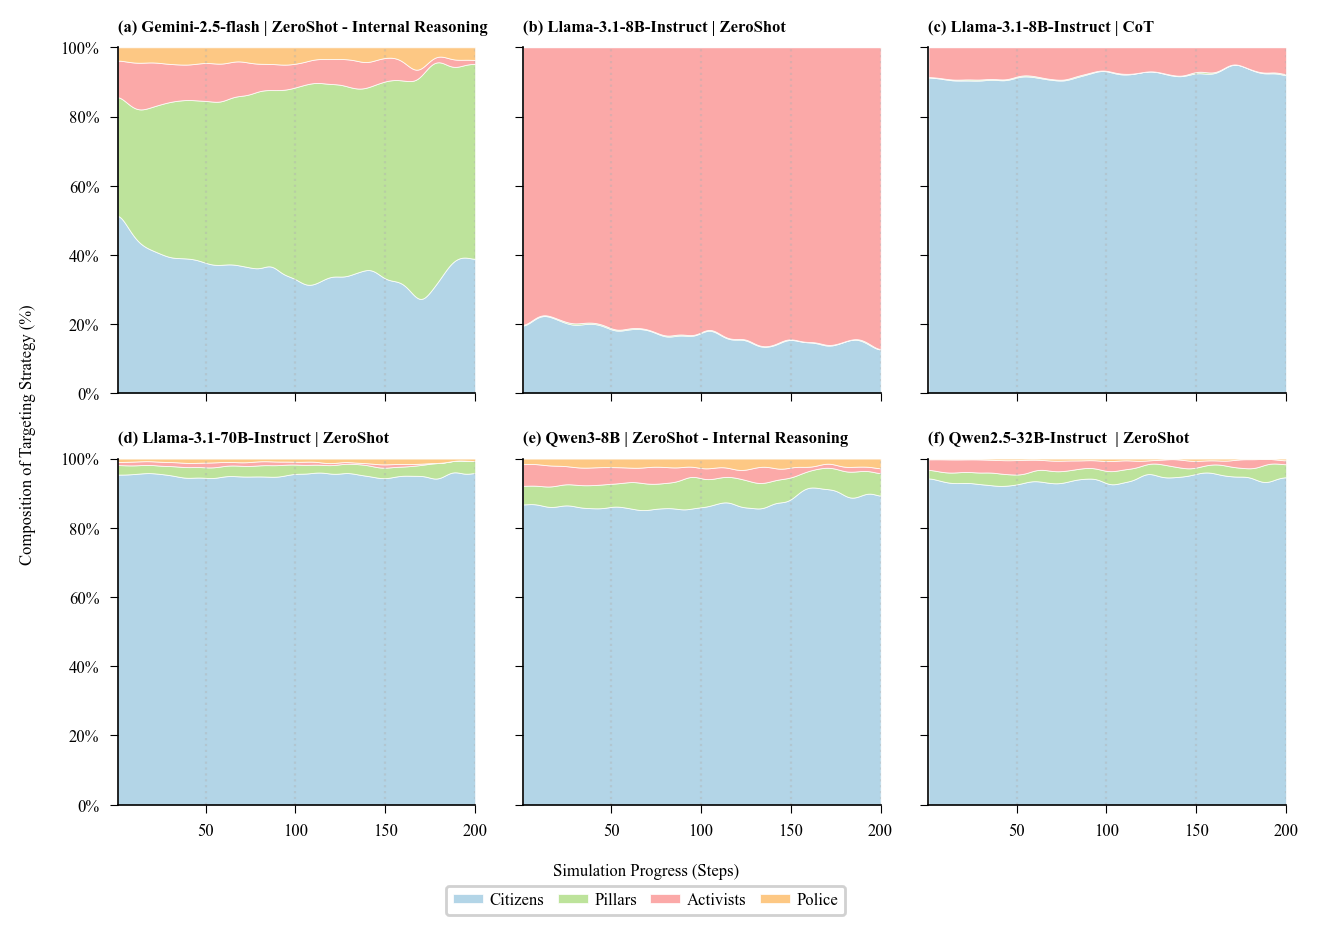

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib import rcParams
import numpy as np
from pathlib import Path
from scipy.ndimage import gaussian_filter1d
import glob

# ── Phase 1: Academic Styling ────────────────────────────────────────────────
rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 9,
    "axes.linewidth": 0.6,
    "lines.linewidth": 0.8,
    "figure.dpi": 200,
    "xtick.labelsize": 6,   # ← add this
    "ytick.labelsize": 6,   # ← add this
    "axes.labelsize": 7,    # ← controls xlabel/ylabel size
})

# ── Setup ────────────────────────────────────────────────────────────────────
PROJECT_ROOT = Path.cwd().parent 

CONFIGS = [
    {"label": "Gemini-2.5-flash | ZeroShot - Internal Reasoning", "log_base": PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot" / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"},
    {"label": "Llama-3.1-8B-Instruct | ZeroShot", "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot" / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"},
    {"label": "Llama-3.1-8B-Instruct | CoT", "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT" / "CoT" / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"},
    {"label": "Llama-3.1-70B-Instruct | ZeroShot", "log_base": PROJECT_ROOT / "SimulationLogs" / "llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot" / "ZeroShot" /"stateful" /"vision-4" /"AgentsLogging" /"simulation_log"},
    {"label": "Qwen3-8B | ZeroShot - Internal Reasoning", "log_base": PROJECT_ROOT /"SimulationLogs" /"Qwen3-8B_ZeroShot" /"ZeroShot" /"stateful" /"vision-4" /"AgentsLogging" /"simulation_log"},
    {"label": "Qwen2.5-32B-Instruct  | ZeroShot", "log_base": PROJECT_ROOT /"SimulationLogs" /"Qwen2.5-32B-Instruct-AWQ_ZeroShot" /"ZeroShot" /"stateful" /"vision-4" /"AgentsLogging" /"simulation_log"},
]
TARGET_AGENTS = ["Citizens", "Pillars", "Activists", "Police"]

# Professional "Light" Palette (Muted Pastels)
# These are distinct but soft, appearing professional in print.
LIGHT_COLORS = ["#A6CEE3", "#B2DF8A", "#FB9A99", "#FDBF6F"] 

MAX_STEPS = 200
SMOOTH_SIGMA = 5 # Higher smoothing for "softer" area transitions

# ── Loader ────────────────────────────────────────────────────────────────────
def load_counts(log_base: Path) -> np.ndarray:
    pattern = str(log_base / "structured" / "activists_logs" / "activists_logs_v*.csv")
    files = sorted(glob.glob(pattern))
    counts = np.zeros((MAX_STEPS, len(TARGET_AGENTS)), dtype=float)
    for path_str in files:
        df = pd.read_csv(path_str)
        if df.empty or "Step" not in df.columns: continue
        df["Step"] = pd.to_numeric(df["Step"], errors='coerce')
        df = df[(df["Step"] <= MAX_STEPS) & (df["event"] == "movement_decision")]
        for j, agent in enumerate([a.lower() for a in TARGET_AGENTS]):
            sub = df[df["target_agent"] == agent]["Step"].value_counts()
            for step, cnt in sub.items():
                if 0 < int(step) <= MAX_STEPS:
                    counts[int(step) - 1, j] += cnt
    return counts

# ── Phase 2: Plotting ────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(6.8, 4.8), sharex=True, sharey=True)
axes = axes.flatten()
steps = np.arange(1, MAX_STEPS + 1)
panel_labels = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)"]

for i, (cfg, ax, panel) in enumerate(zip(CONFIGS, axes, panel_labels)):
    counts = load_counts(cfg["log_base"])
    
    # Smooth and Normalize to 100%
    smoothed = np.stack([gaussian_filter1d(counts[:, j], sigma=SMOOTH_SIGMA) for j in range(len(TARGET_AGENTS))], axis=1)
    row_sums = smoothed.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    proportions = (smoothed / row_sums) * 100

    # Stack the areas
    # We use stackplot for the "filled" look
    ax.stackplot(steps, proportions.T, labels=TARGET_AGENTS, 
                 colors=LIGHT_COLORS, alpha=0.85, edgecolor='white', linewidth=0.3)

    # Subplot Aesthetic cleanup
    ax.set_title(f"{panel} {cfg['label']}", loc="left", fontweight="bold", fontsize=6, pad=6)
    ax.set_xlim(1, MAX_STEPS)
    ax.set_ylim(0, 100)
    
    # Grid: Only vertical lines to emphasize time steps without cluttering the color
    ax.grid(axis='x', linestyle=':', alpha=0.4)
    ax.tick_params(axis='both', which='major', length=3)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))

    # Remove outer spines for a modern "open" look
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# ── Phase 3: Global Labels & Legend ──────────────────────────────────────────
fig.text(0.5, 0.04, 'Simulation Progress (Steps)', ha='center', fontsize=6)
fig.text(0.04, 0.5, 'Composition of Targeting Strategy (%)', va='center', rotation='vertical', fontsize=6)

# Legend at bottom center
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
        handles, labels,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.01),
        ncol=4,
        frameon=True,
        framealpha=0.9,
        edgecolor="0.8",
        columnspacing=0.8,
        handletextpad=0.4,
    )
# fig.legend(handles[::-1], labels[::-1], loc='lower center', ncol=4, 
#            bbox_to_anchor=(0.5, -0.01), frameon=False, fontsize=6)

plt.tight_layout(rect=[0.05, 0.05, 1, 0.96])
plt.savefig("targeting_composition_stacked.pdf", bbox_inches="tight")
plt.show()



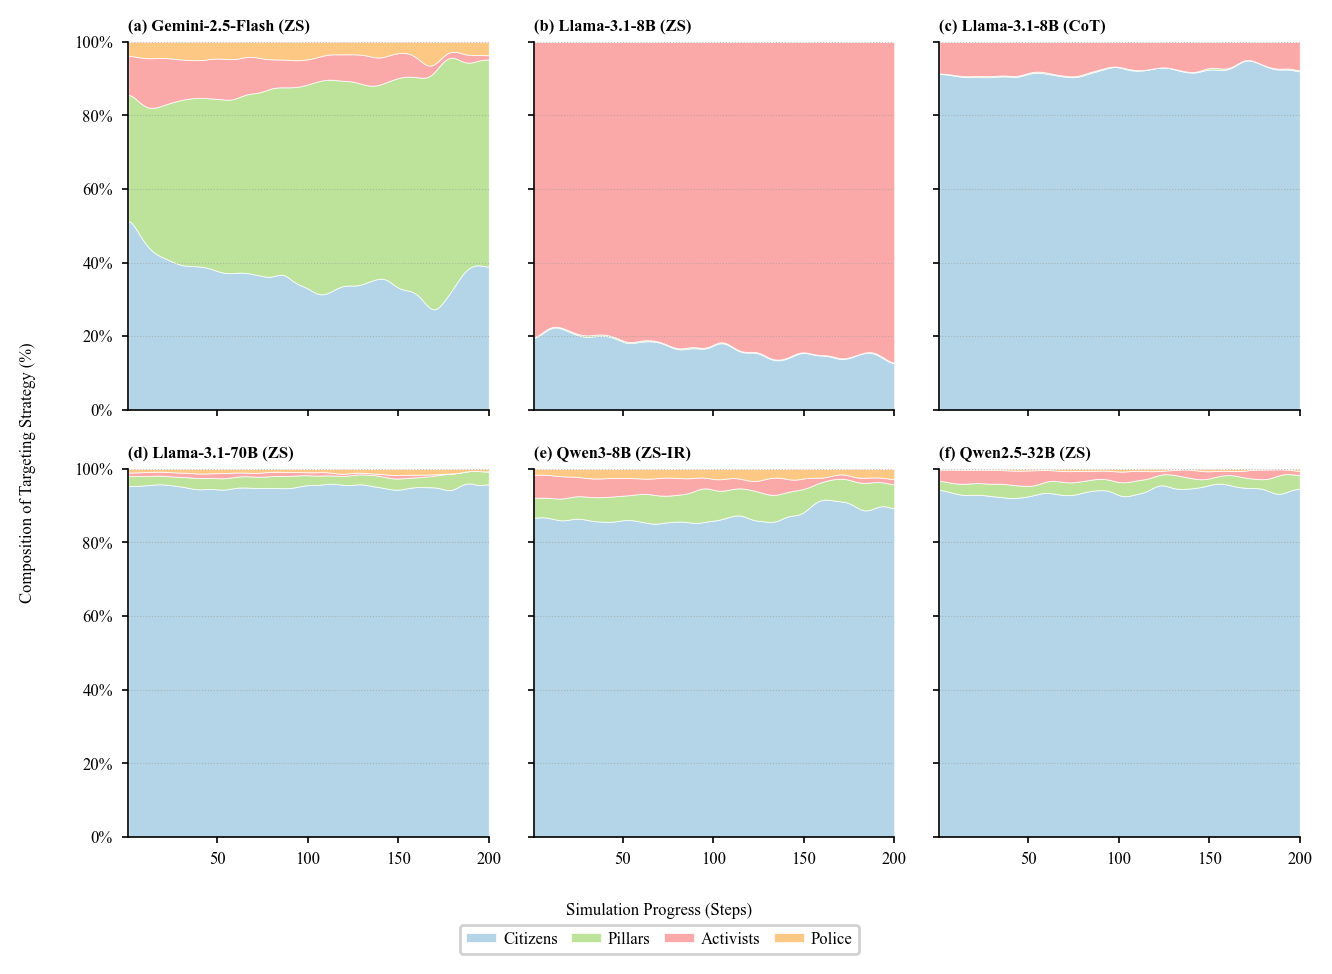

Saved: targeting_composition_stacked.pdf / .png


In [17]:
"""
targeting_composition_stacked.py
Stacked-area composition of activist targeting strategy over simulation time.

Fixes vs. original
------------------
- rcParams / CONFIGS / constants imported from paper_style.py (no duplication)
- style_ax() applied to every subplot for consistent chrome
- Grid unified: y-axis dashed lines (matches invalid-targeting figure)
- Panel labels use consistent (a)–(f) scheme
- Legend repositioned to avoid clipping
- fig.text coordinates corrected to figure fraction
"""

import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path
from scipy.ndimage import gaussian_filter1d

# ── Shared style ───────────────────────────────────────────────────────────
from paper_style import (
    TARGET_COLORS, CONFIGS, MAX_STEPS, SMOOTH_SIGMA, style_ax
)

TARGET_AGENTS = ["Citizens", "Pillars", "Activists", "Police"]
PANEL_LABELS  = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)"]


# ── Data loader ────────────────────────────────────────────────────────────

def load_counts(log_base: Path) -> np.ndarray:
    """
    Return per-step target-agent counts, shape (MAX_STEPS, len(TARGET_AGENTS)).
    Rows = steps (1-indexed mapped to 0-indexed),
    Cols = [Citizens, Pillars, Activists, Police].
    """
    pattern = str(
        log_base / "structured" / "activists_logs" / "activists_logs_v*.csv"
    )
    files = sorted(glob.glob(pattern))

    counts = np.zeros((MAX_STEPS, len(TARGET_AGENTS)), dtype=float)

    for path_str in files:
        try:
            df = pd.read_csv(path_str)
        except Exception:
            continue

        if df.empty or "Step" not in df.columns:
            continue

        df["Step"] = pd.to_numeric(df["Step"], errors="coerce")
        df = df[
            (df["Step"] >= 1) &
            (df["Step"] <= MAX_STEPS) &
            (df["event"] == "movement_decision")
        ]

        if df.empty:
            continue

        for j, agent in enumerate([a.lower() for a in TARGET_AGENTS]):
            step_counts = df[df["target_agent"] == agent]["Step"].value_counts()
            for step, cnt in step_counts.items():
                step = int(step)
                if 1 <= step <= MAX_STEPS:
                    counts[step - 1, j] += cnt

    return counts


# ── Main plot ──────────────────────────────────────────────────────────────

def run_plot():
    fig, axes = plt.subplots(2, 3, figsize=(6.8, 4.8),
                             sharex=True, sharey=True)
    axes = axes.flatten()
    steps = np.arange(1, MAX_STEPS + 1)

    for i, (cfg, ax, panel) in enumerate(zip(CONFIGS, axes, PANEL_LABELS)):
        counts   = load_counts(cfg["log_base"])

        # Smooth each column then normalise rows to 100 %
        smoothed = np.stack(
            [gaussian_filter1d(counts[:, j], sigma=SMOOTH_SIGMA)
             for j in range(len(TARGET_AGENTS))],
            axis=1,
        )
        row_sums = smoothed.sum(axis=1, keepdims=True)
        row_sums[row_sums == 0] = 1
        proportions = (smoothed / row_sums) * 100

        ax.stackplot(
            steps, proportions.T,
            labels=TARGET_AGENTS,
            colors=TARGET_COLORS,
            alpha=0.85,
            edgecolor="white",
            linewidth=0.3,
        )

        # Panel title — model short name + prompting technique
        title = f"{panel} {cfg['short']} ({cfg['technique']})"
        ax.set_title(title, loc="left", fontweight="bold", fontsize=6, pad=4)

        ax.set_xlim(1, MAX_STEPS)
        ax.set_ylim(0, 100)
        ax.xaxis.set_major_locator(mticker.MultipleLocator(50))
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
        ax.yaxis.set_major_locator(mticker.MultipleLocator(20))

        # Unified axis chrome
        style_ax(ax)

    # ── Global axis labels ─────────────────────────────────────────────────
    
# ── Phase 3: Global Labels & Legend ──────────────────────────────────────────
# fig.text(0.5, 0.04, 'Simulation Progress (Steps)', ha='center', fontsize=6)
# fig.text(0.04, 0.5, 'Composition of Targeting Strategy (%)', va='center', rotation='vertical', fontsize=6)

# # Legend at bottom center
# handles, labels = axes[0].get_legend_handles_labels()
# fig.legend(handles[::-1], labels[::-1], loc='lower center', ncol=4, 
#            bbox_to_anchor=(0.5, -0.01), frameon=False, fontsize=6)

    fig.text(0.5,  0.04, "Simulation Progress (Steps)",
             ha="center", fontsize=6)
    fig.text(0.03, 0.5,  "Composition of Targeting Strategy (%)",
             va="center", rotation="vertical", fontsize=6)

    # ── Shared legend — bottom centre ──────────────────────────────────────
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.01),
        ncol=4,
        frameon=True,
        framealpha=0.9,
        edgecolor="0.8",
        columnspacing=0.8,
        handletextpad=0.4,
    )

    plt.tight_layout(rect=[0.05, 0.06, 1.0, 1.0])
    plt.savefig("targeting_composition_stacked.pdf", bbox_inches="tight")
    plt.savefig("targeting_composition_stacked.png", bbox_inches="tight")
    plt.show()
    print("Saved: targeting_composition_stacked.pdf / .png")


run_plot()

### **Line Area Plots For Targetting Agents**

In [18]:
# import pandas as pd
# import matplotlib.pyplot as plt
# import matplotlib.ticker as mticker
# import matplotlib.gridspec as gridspec
# from matplotlib import rcParams
# import glob
# import numpy as np
# from pathlib import Path
# from scipy.ndimage import gaussian_filter1d

# # ── Phase 1: Publication Standards (IEEE/ACM/Nature Style) ───────────────────
# rcParams.update({
#     "font.family": "serif",
#     "font.serif": ["Times New Roman"], # Standard for academic papers
#     "font.size": 9,
#     "axes.titlesize": 9,
#     "axes.labelsize": 9,
#     "xtick.labelsize": 8,
#     "ytick.labelsize": 8,
#     "legend.fontsize": 7.5,
#     "axes.linewidth": 0.7,
#     "grid.linewidth": 0.5,
#     "lines.linewidth": 1.2, # Slightly thicker lines for clarity
#     "figure.dpi": 300,
#     "text.usetex": False, 
# })

# # ── Settings ──────────────────────────────────────────────────────────────────
# # Update PROJECT_ROOT to your local path
# PROJECT_ROOT = Path.cwd().parent 

# # Re-enabling 4 models to fill a 2x2 grid
# CONFIGS = [
#     {"label": "Gemini-2.5-flash", "log_base": PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot" / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"},
#     {"label": "Llama-3.1-8B-Instruct (CoT)", "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT" / "CoT" / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"},
#     {"label": "Llama-3.1-8B-Instruct (ZeroShot)", "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot" / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"},
#     {"label": "Qwen2.5-32B-Instruct", "log_base": PROJECT_ROOT / "SimulationLogs" / "Qwen2.5-32B-Instruct-AWQ_ZeroShot" / "ZeroShot" / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"},
# ]

# TARGET_AGENTS = ["Citizens", "Pillars", "Activists", "Police"]
# TARGET_COLORS = ["#2166AC", "#4DAC26", "#D01C8B", "#E66101"] # Colorblind-safe
# MAX_STEPS = 200
# SMOOTH_SIGMA = 4

# # ── Data Loader (Reuse your logic) ───────────────────────────────────────────
# def load_counts(log_base: Path) -> np.ndarray:
#     pattern = str(log_base / "structured" / "activists_logs" / "activists_logs_v*.csv")
#     files = sorted(glob.glob(pattern))
#     counts = np.zeros((MAX_STEPS, len(TARGET_AGENTS)), dtype=float)

#     for path_str in files:
#         df = pd.read_csv(path_str)
#         if df.empty or "Step" not in df.columns: continue
#         df["Step"] = pd.to_numeric(df["Step"], errors='coerce')
#         df = df[(df["Step"] <= MAX_STEPS) & (df["event"] == "movement_decision")]
#         for j, agent in enumerate([a.lower() for a in TARGET_AGENTS]):
#             sub = df[df["target_agent"] == agent]["Step"].value_counts()
#             for step, cnt in sub.items():
#                 if 0 < int(step) <= MAX_STEPS:
#                     counts[int(step) - 1, j] += cnt
#     return counts

# # ── Phase 2: Plotting ────────────────────────────────────────────────────────
# fig, axes = plt.subplots(2, 2, figsize=(6.5, 4.5), sharex=True, sharey=True)
# axes = axes.flatten()
# steps = np.arange(1, MAX_STEPS + 1)
# panel_labels = ["(a)", "(b)", "(c)", "(d)"]

# for i, (cfg, ax, panel) in enumerate(zip(CONFIGS, axes, panel_labels)):
#     counts = load_counts(cfg["log_base"])
    
#     # Smoothing and Normalizing
#     smoothed = np.stack([gaussian_filter1d(counts[:, j], sigma=SMOOTH_SIGMA) for j in range(len(TARGET_AGENTS))], axis=1)
#     row_sums = smoothed.sum(axis=1, keepdims=True)
#     row_sums[row_sums == 0] = 1
#     proportions = (smoothed / row_sums) * 100

#     # Draw individual lines (Like the reference image)
#     for j, (agent, color) in enumerate(zip(TARGET_AGENTS, TARGET_COLORS)):
#         ax.plot(steps, proportions[:, j], color=color, label=agent, antialiased=True)

#     # Styling each subplot
#     ax.set_title(f"{panel} {cfg['label']}", loc="left", fontweight="bold", pad=5)
#     ax.set_xlim(1, MAX_STEPS)
#     ax.set_ylim(0, 105)
#     ax.grid(True, linestyle="--", alpha=0.3, linewidth=0.5)
    
#     # Clean spines (Top/Right off)
#     ax.spines["top"].set_visible(False)
#     ax.spines["right"].set_visible(False)
    
#     # Tick formatting
#     ax.xaxis.set_major_locator(mticker.MultipleLocator(50))
#     ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))

# # ── Phase 3: Labels and Legend ──────────────────────────────────────────────
# # Global labels for shared axes
# fig.text(0.5, 0.02, 'Simulation Step', ha='center', fontsize=10)
# fig.text(0.02, 0.5, 'Targeting Proportion (%)', va='center', rotation='vertical', fontsize=10)

# # Shared legend at the bottom
# handles, labels = axes[0].get_legend_handles_labels()
# fig.legend(handles, labels, loc='lower center', ncol=4, 
#            bbox_to_anchor=(0.5, -0.08), frameon=False)

# plt.tight_layout(rect=[0.03, 0.03, 1, 0.95]) # Adjust for global labels
# plt.savefig("targeting_trajectory_lines.pdf", bbox_inches="tight")
# plt.show()

In [19]:
# import pandas as pd
# import matplotlib.pyplot as plt
# import matplotlib.ticker as mticker
# import matplotlib.gridspec as gridspec
# from matplotlib import rcParams
# import glob
# import numpy as np
# from pathlib import Path
# from scipy.ndimage import gaussian_filter1d

# # # ── Publication style settings ────────────────────────────────────────────────
# rcParams.update({
#     "font.family":        "serif",
#     "font.serif":         ["Times New Roman", "DejaVu Serif"],
#     "font.size":          9,
#     "axes.titlesize":     9,
#     "axes.labelsize":     9,
#     "xtick.labelsize":    8,
#     "ytick.labelsize":    8,
#     "legend.fontsize":    7.5,
#     "axes.linewidth":     0.8,
#     "grid.linewidth":     0.5,
#     "lines.linewidth":    1.0,
#     "figure.dpi":         300,
#     "savefig.dpi":        300,
#     "savefig.bbox":       "tight",
#     "text.usetex":        False,
# })

# # ── Setup ────────────────────────────────────────────────────────────────────
# PROJECT_ROOT = Path.cwd().parent 

# CONFIGS = [
#     # {"label": "Gemini-2.5-flash | ZeroShot | Internal Reasoning", "log_base": PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot" / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"},
#     {"label": "Llama-3.1-8B-Instruct | ZeroShot", "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot" / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"},
#     {"label": "Llama-3.1-8B-Instruct | CoT", "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT" / "CoT" / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"},
#     # {"label": "Llama-3.1-70B-Instruct | ZeroShot", "log_base": PROJECT_ROOT / "SimulationLogs" / "llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot" / "ZeroShot" /"stateful" /"vision-4" /"AgentsLogging" /"simulation_log"},
#     # {"label": "Qwen3-8B | ZeroShot | Internal Reasoning", "log_base": PROJECT_ROOT /"SimulationLogs" /"Qwen3-8B_ZeroShot_0-85" /"ZeroShot" /"stateful" /"vision-4" /"AgentsLogging" /"simulation_log"},
#     # {"label": "Qwen2.5-32B-Instruct  | ZeroShot", "log_base": PROJECT_ROOT /"SimulationLogs" /"Qwen2.5-32B-Instruct-AWQ_ZeroShot" /"ZeroShot" /"stateful" /"vision-4" /"AgentsLogging" /"simulation_log"},
# ]

# PROVIDER = "llama3.1-70B-Instruct-AWQ_CoT"

# TARGET_AGENTS = ["citizens", "pillars", "activists", "police"]

# # Colorblind-safe palette (works in grayscale print too)
# TARGET_COLORS = ["#2166AC", "#4DAC26", "#D01C8B", "#E66101", "#5AB4AC"]
# MAX_STEPS     = 200
# SMOOTH_SIGMA  = 4

# # ── Loader ────────────────────────────────────────────────────────────────────
# def load_counts(log_base: Path) -> np.ndarray:
#     pattern = str(log_base / "structured" / "activists_logs" / "activists_logs_v*.csv")
#     files   = sorted(glob.glob(pattern))
#     counts  = np.zeros((MAX_STEPS, len(TARGET_AGENTS)), dtype=float)

#     for path_str in files:
#         df = pd.read_csv(path_str)
#         if df.empty or "Step" not in df.columns or "target_agent" not in df.columns:
#             continue
#         df = df[df["Step"] <= MAX_STEPS]
#         df = df[(df["target_agent"].isin(TARGET_AGENTS)) & (df["event"] == "movement_decision")]
#         for j, agent in enumerate(TARGET_AGENTS):
#             sub = df[df["target_agent"] == agent]["Step"].value_counts()
#             for step, cnt in sub.items():
#                 counts[int(step) - 1, j] += cnt
#     return counts

# # ── Figure: 1 row × 3 cols ────────────────────────────────────────────────────
# fig = plt.figure(figsize=(7.0, 2.6))   # fits a two-column paper (inches)

# gs = gridspec.GridSpec(
#     1, len(CONFIGS),
#     figure=fig,
#     wspace=0.08,          # tight horizontal gap — shared y-axis feel
# )

# steps = np.arange(1, MAX_STEPS + 1)
# panel_labels = ["(a)", "(b)", "(c)", "(d)"]   # standard IEEE / ACM panel notation

# axes = []
# for col, (cfg, panel) in enumerate(zip(CONFIGS, panel_labels)):
#     ax = fig.add_subplot(gs[0, col])
#     axes.append(ax)

#     counts = load_counts(cfg["log_base"])

#     smoothed = np.stack([
#         gaussian_filter1d(counts[:, j], sigma=SMOOTH_SIGMA)
#         for j in range(len(TARGET_AGENTS))
#     ], axis=1)

#     row_sums = smoothed.sum(axis=1, keepdims=True)
#     row_sums[row_sums == 0] = 1
#     proportions = smoothed / row_sums * 100

#     bottoms = np.zeros(MAX_STEPS)
#     for j, (agent, color) in enumerate(zip(TARGET_AGENTS, TARGET_COLORS)):
#         ax.fill_between(steps, bottoms, bottoms + proportions[:, j],
#                         color=color, alpha=0.78, linewidth=0)
#         ax.plot(steps, bottoms + proportions[:, j],
#                 color=color, linewidth=0.4, alpha=0.6)
#         bottoms += proportions[:, j]

#     # Panel label + model name as title
#     ax.set_title(f"{panel} {cfg['label']}", fontsize=8.5,
#                  fontweight="bold", loc="left", pad=3)

#     ax.set_xlim(1, MAX_STEPS)
#     ax.set_ylim(0, 100)
#     ax.set_xlabel("Simulation step", fontsize=8)
#     ax.yaxis.set_major_formatter(mticker.PercentFormatter())
#     ax.xaxis.set_major_locator(mticker.MultipleLocator(50))
#     ax.grid(axis='x', linestyle=':', linewidth=0.5, alpha=0.6)
#     ax.tick_params(axis='both', length=2.5)

#     # Only leftmost subplot gets y-axis label and ticks
#     if col == 0:
#         ax.set_ylabel("Targeting proportion (%)", fontsize=8)
#     else:
#         ax.tick_params(labelleft=False)
#         ax.yaxis.set_tick_params(length=0)

#     # Spine cleanup — top & right off
#     ax.spines["top"].set_visible(False)
#     ax.spines["right"].set_visible(False)
#     ax.spines["left"].set_linewidth(0.6)
#     ax.spines["bottom"].set_linewidth(0.6)

# # ── Shared legend below all subplots ─────────────────────────────────────────
# from matplotlib.patches import Patch
# legend_handles = [
#     Patch(facecolor=color, alpha=0.78, label=agent)
#     for agent, color in zip(TARGET_AGENTS, TARGET_COLORS)
# ]
# fig.legend(
#     handles=legend_handles,
#     loc="lower center",
#     ncol=len(TARGET_AGENTS),
#     fontsize=7.5,
#     frameon=True,
#     framealpha=0.9,
#     edgecolor="0.7",
#     bbox_to_anchor=(0.5, -0.18),
#     title="Target agent",
#     title_fontsize=7.5,
# )

# fig.suptitle(
#     "Evolution of Activist Targetting Strategy Across Simulation Steps",
#     fontsize=9, fontweight="bold", y=1.02
# )

# plt.savefig("figure_targeting_strategy.pdf", format="pdf", bbox_inches="tight")
# plt.savefig("figure_targeting_strategy.png", format="png", bbox_inches="tight")
# plt.show()

# print("Saved: figure_targeting_strategy.pdf / .png")

[{'label': 'Gemini-2.5-Flash | ZeroShot', 'short': 'Gemini-2.5-Flash', 'technique': 'ZS', 'log_base': WindowsPath('c:/Users/fmahnoor1/Documents/Research-FL/ABM-Repos/pyabm-llm/SimulationLogs/gemini-2.5-flash/ZeroShot/stateful/vision-4/AgentsLogging/simulation_log')}, {'label': 'Llama-3.1-8B | ZeroShot', 'short': 'Llama-3.1-8B', 'technique': 'ZS', 'log_base': WindowsPath('c:/Users/fmahnoor1/Documents/Research-FL/ABM-Repos/pyabm-llm/SimulationLogs/llama3.1-8B-Instruct_ZeroShot/ZeroShot/stateful/vision-4/AgentsLogging/simulation_log')}, {'label': 'Llama-3.1-8B | CoT', 'short': 'Llama-3.1-8B', 'technique': 'CoT', 'log_base': WindowsPath('c:/Users/fmahnoor1/Documents/Research-FL/ABM-Repos/pyabm-llm/SimulationLogs/llama3.1-8B-Instruct_CoT/CoT/stateful/vision-4/AgentsLogging/simulation_log')}, {'label': 'Llama-3.1-70B | ZeroShot', 'short': 'Llama-3.1-70B', 'technique': 'ZS', 'log_base': WindowsPath('c:/Users/fmahnoor1/Documents/Research-FL/ABM-Repos/pyabm-llm/SimulationLogs/llama-3.1-70B-Inst

KeyError: 'ZS-IR'

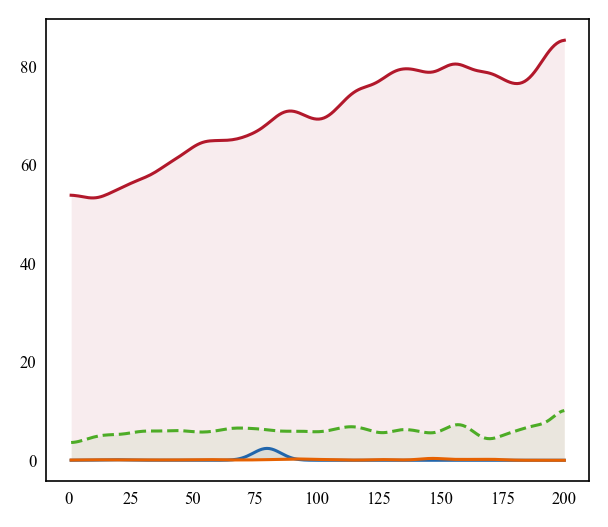

In [20]:
"""
figure_invalid_targeting.py
Invalid target selection rate per simulation step, per model configuration.

Fixes vs. broken version
-------------------------
- load_invalid_rate uses correct column: target_validity (VALID / INVALID)
- Duplicate rcParams / CONFIGS blocks removed — imported from paper_style.py
- All NaN / empty-plot warnings resolved
- Style unified with targeting_composition_stacked.py
  · same rcParams, colors, linestyles, grid, spines, tick params
- fill_between applied uniformly at alpha=0.08 (not selectively)
- fig.text uses figure-level coordinates (not ax.transAxes)
- Legend bbox_to_anchor adjusted so it does not overlap the linestyle note
"""

import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path
from scipy.ndimage import gaussian_filter1d

from paper_style import (
    MODEL_COLORS, LINESTYLES, CONFIGS, MAX_STEPS, SMOOTH_SIGMA, style_ax
)

print(CONFIGS)

# ── Loader ─────────────────────────────────────────────────────────────────

def load_invalid_rate(log_base: Path) -> np.ndarray:
    """
    Return per-step invalid target selection rate (%) averaged across all runs.
    Reads target_validity column (values: VALID / INVALID).
    Returns shape (MAX_STEPS,) with NaN where no decisions were recorded.
    """
    pattern = str(
        log_base / "structured" / "activists_logs" / "activists_logs_v*.csv"
    )
    files = sorted(glob.glob(pattern))

    total_counts   = np.zeros(MAX_STEPS, dtype=float)
    invalid_counts = np.zeros(MAX_STEPS, dtype=float)

    for path_str in files:
        try:
            df = pd.read_csv(path_str)
        except Exception:
            continue

        if df.empty or "Step" not in df.columns or "target_validity" not in df.columns:
            continue

        df["Step"] = pd.to_numeric(df["Step"], errors="coerce")
        df = df[(df["Step"] >= 1) & (df["Step"] <= MAX_STEPS)].copy()

        df["target_validity"] = (
            df["target_validity"].astype(str).str.strip().str.upper()
        )
        df = df[df["target_validity"].isin(["VALID", "INVALID"])]

        if df.empty:
            continue

        for step, grp in df.groupby("Step"):
            idx = int(step) - 1
            if 0 <= idx < MAX_STEPS:
                total_counts[idx]   += len(grp)
                invalid_counts[idx] += (grp["target_validity"] == "INVALID").sum()

    with np.errstate(invalid="ignore", divide="ignore"):
        rate = np.where(
            total_counts > 0,
            invalid_counts / total_counts * 100,
            np.nan,
        )
    return rate


# ── Plot ───────────────────────────────────────────────────────────────────

def run_plot():
    fig, ax = plt.subplots(figsize=(3.5, 3.0))
    steps   = np.arange(1, MAX_STEPS + 1)

    for i, cfg in enumerate(CONFIGS):
        color = MODEL_COLORS[i % len(MODEL_COLORS)]
        ls    = LINESTYLES[cfg["technique"]]
        rate  = load_invalid_rate(cfg["log_base"])

        valid_mask = ~np.isnan(rate)
        if valid_mask.sum() < 2:
            print(f"[WARN] {cfg['short']} ({cfg['technique']}): "
                  f"insufficient data — skipping")
            continue

        rate_filled = np.interp(steps, steps[valid_mask], rate[valid_mask])
        smoothed    = gaussian_filter1d(rate_filled, sigma=SMOOTH_SIGMA)
        mu          = np.nanmean(rate)

        label = f"{cfg['short']} ({cfg['technique']},  $\\mu$={mu:.1f}%)"

        ax.plot(steps, smoothed,
                color=color, linestyle=ls, linewidth=1.1, label=label)

        ax.fill_between(steps, smoothed,
                        alpha=0.08, color=color, linewidth=0)

    # ── Axes — identical settings to targeting_composition_stacked ─────────
    ax.set_xlabel(r"Simulation Progress (Steps)")
    ax.set_ylabel(r"Invalid Target Selection Rate (%)")
    ax.set_xlim(1, MAX_STEPS)
    ax.set_ylim(0, 100)

    ax.yaxis.set_major_formatter(mticker.PercentFormatter())
    ax.yaxis.set_major_locator(mticker.MultipleLocator(20))
    ax.xaxis.set_major_locator(mticker.MultipleLocator(25))

    style_ax(ax)   # spines off, tick params, y-grid

    # ── Legend ────────────────────────────────────────────────────────────
    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.20),
        ncol=2,
        columnspacing=0.8,
        handletextpad=0.4,
        handlelength=2.2,
        frameon=True,
        framealpha=0.9,
        edgecolor="0.8",
    )

    # Linestyle key — figure-level coordinates (not ax.transAxes)
    fig.text(
        0.5, -0.01,
        r"$-$ Zero-Shot (ZS) $\;\;$ $--$ Chain-of-Thought (CoT) $\;\;$ $--$ Internal Reasoning (IR)",
        ha="center", va="top", fontsize=5.5, color="0.45",
    )

    plt.savefig("figure_invalid_targeting.pdf", bbox_inches="tight")
    plt.savefig("figure_invalid_targeting.png", bbox_inches="tight")
    plt.show()
    print("Saved: figure_invalid_targeting.pdf / .png")


run_plot()

In [ ]:
rcParams.update({
    "font.family": "serif",
    "font.serif":  ["Times New Roman"],
    "font.size":        8,
    "axes.labelsize":   8,
    "xtick.labelsize":  7,
    "ytick.labelsize":  7,
    "legend.fontsize":  6.5,
    "axes.linewidth":   0.6,
    "lines.linewidth":  1.1,
    "figure.dpi":       300,
    "savefig.bbox":     "tight",
})



# ── Phase 1: Academic Styling ────────────────────────────────────────────────
rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 9,
    "axes.linewidth": 0.6,
    "lines.linewidth": 0.8,
    "figure.dpi": 200,
    "xtick.labelsize": 6,   # ← add this
    "ytick.labelsize": 6,   # ← add this
    "axes.labelsize": 7,    # ← controls xlabel/ylabel size
})

# ── Setup ────────────────────────────────────────────────────────────────────
PROJECT_ROOT = Path.cwd().parent 

CONFIGS = [
    {"label": "Gemini-2.5-flash | ZeroShot | Internal Reasoning", "log_base": PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot" / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"},
    {"label": "Llama-3.1-8B-Instruct | ZeroShot", "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot" / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"},
    {"label": "Llama-3.1-8B-Instruct | CoT", "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT" / "CoT" / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"},
    {"label": "Llama-3.1-70B-Instruct | ZeroShot", "log_base": PROJECT_ROOT / "SimulationLogs" / "llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot" / "ZeroShot" /"stateful" /"vision-4" /"AgentsLogging" /"simulation_log"},
    {"label": "Qwen3-8B | ZeroShot | Internal Reasoning", "log_base": PROJECT_ROOT /"SimulationLogs" /"Qwen3-8B_ZeroShot" /"ZeroShot" /"stateful" /"vision-4" /"AgentsLogging" /"simulation_log"},
    {"label": "Qwen2.5-32B-Instruct  | ZeroShot", "log_base": PROJECT_ROOT /"SimulationLogs" /"Qwen2.5-32B-Instruct-AWQ_ZeroShot" /"ZeroShot" /"stateful" /"vision-4" /"AgentsLogging" /"simulation_log"},
]
TARGET_AGENTS = ["Citizens", "Pillars", "Activists", "Police"]

# Professional "Light" Palette (Muted Pastels)
# These are distinct but soft, appearing professional in print.
LIGHT_COLORS = ["#A6CEE3", "#B2DF8A", "#FB9A99", "#FDBF6F"] 

COLORS = ["#2166AC", "#B2182B", "#4DAC26", "#E66101", "#542788", "#01665E"]

# Solid = ZeroShot, Dashed = CoT — readable in greyscale
LINESTYLES = {
    "ZeroShot": "-",
    "CoT":      "--",
}

MAX_STEPS    = 200
SMOOTH_SIGMA = 5


def run_plot():
    fig, ax = plt.subplots(figsize=(3.5, 2.8))
    steps = np.arange(1, MAX_STEPS + 1)

    for i, cfg in enumerate(CONFIGS):
        color   = COLORS[i % len(COLORS)]
        rate    = load_invalid_rate(cfg["log_base"])
        label   = cfg["label"]
        is_cot  = "CoT" in label
        ls      = LINESTYLES["CoT"] if is_cot else LINESTYLES["ZeroShot"]
        technique = "CoT" if is_cot else "ZS"

        valid_mask = ~np.isnan(rate)
        if valid_mask.sum() > 1:
            rate_filled = np.interp(steps, steps[valid_mask], rate[valid_mask])
            smoothed    = gaussian_filter1d(rate_filled, sigma=SMOOTH_SIGMA)
            mu          = np.nanmean(rate)

            short_name = (
                label.split("|")[0].strip()
                     .replace("-Instruct", "")
                     .replace("-AWQ-INT4", "")
                     .replace("-AWQ", "")
            )

            ax.plot(
                steps, smoothed,
                color=color, linestyle=ls, linewidth=1.1,
                label=f"{short_name} ({technique}, $\\mu$={mu:.1f}\\%)",
            )
            # Only fill for lines that stay low — skip dominant ones to reduce clutter
            if mu < 15:
                ax.fill_between(steps, smoothed, alpha=0.10, color=color, linewidth=0)

    # ── Axes ──────────────────────────────────────────────────────────────────
    ax.set_xlabel(r"Simulation Step Index ($t$)", fontsize=8)
    ax.set_ylabel(r"Invalid Target Selection Rate (\%)", fontsize=8)
    ax.set_xlim(1, MAX_STEPS)
    ax.set_ylim(0, 100)

    ax.yaxis.set_major_formatter(mticker.PercentFormatter())
    ax.yaxis.set_major_locator(mticker.MultipleLocator(20))

    ax.grid(axis="y", linestyle=":", linewidth=0.4, alpha=0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", length=2, width=0.6)

    # ── Legend — below the plot, avoids all overlap ───────────────────────────
    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.28),   # push below x-axis
        ncol=2,
        columnspacing=0.7,
        handletextpad=0.4,
        handlelength=1.8,              # long enough to show dashes
        frameon=True,
        framealpha=0.9,
        edgecolor="0.8",
        fontsize=6,
    )

    # ── Line style legend note ─────────────────────────────────────────────────
    fig.text(
        0.5, -0.01,
        r"\textit{Solid} = Zero-Shot $\quad$ \textit{Dashed} = Chain-of-Thought",
        ha="center", fontsize=6, color="0.4"
    )

    plt.savefig("figure_invalid_targeting.pdf", dpi=300, bbox_inches="tight")
    plt.show()

run_plot()


NameError: name 'rcParams' is not defined

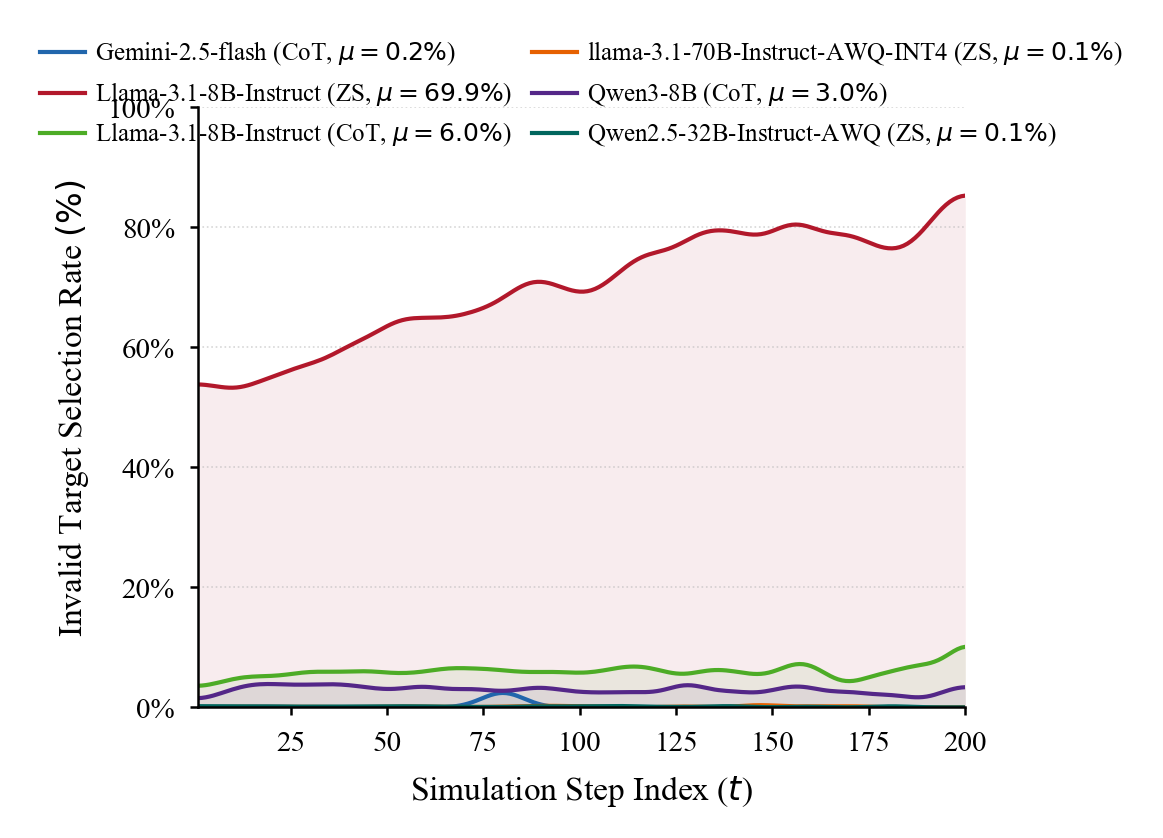

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib import rcParams
import numpy as np
from scipy.ndimage import gaussian_filter1d
from pathlib import Path
import matplotlib.lines as mlines

# ── Springer Single-Column Style ─────────────────────────────────────────────
rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6.5, # Slightly smaller for 6 items
    "axes.linewidth": 0.6,
    "lines.linewidth": 1.0,
    "figure.dpi": 300,
    "savefig.bbox": "tight",
})

PROJECT_ROOT = Path.cwd().parent
CONFIGS = [
    {
        "label":   "Gemini-2.5-flash",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot"
                   / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":   "Llama-3.1-8B-Instruct | ZeroShot",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":   "Llama-3.1-8B-Instruct | CoT",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT" / "CoT"
                   / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":   "llama-3.1-70B-Instruct-AWQ-INT4 | ZeroShot",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":   "Qwen3-8B| CoT",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "qwen3-8B_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":   "Qwen2.5-32B-Instruct-AWQ | ZeroShot",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "Qwen2.5-32B-Instruct-AWQ_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
]

# Professional color palette from your sample
COLORS       = ["#2166AC", "#D01C8B", "#4DAC26", "#E66101", "#008080", "#542788"]
MAX_STEPS    = 200
SMOOTH_SIGMA = 5


# Expanded Color Palette (Colorblind friendly)
COLORS = ["#2166AC", "#B2182B", "#4DAC26", "#E66101", "#542788", "#01665E"]
MAX_STEPS = 200
SMOOTH_SIGMA = 5

# ... (Keep your load_invalid_rate function as is) ...

def run_plot():
    # Springer single column is ~3.3 inches wide
    fig, ax = plt.subplots(figsize=(3.3, 2.6)) 
    steps = np.arange(1, MAX_STEPS + 1)

    for i, cfg in enumerate(CONFIGS):
        color = COLORS[i % len(COLORS)]
        rate = load_invalid_rate(cfg["log_base"])

        valid_mask = ~np.isnan(rate)
        if valid_mask.sum() > 1:
            rate_filled = np.interp(steps, steps[valid_mask], rate[valid_mask])
            smoothed = gaussian_filter1d(rate_filled, sigma=SMOOTH_SIGMA)
            overall_invalid = np.nanmean(rate)
            
            # Simplified label for the legend
            clean_label = cfg["label"].split('|')[0].strip() # Shortens name if too long
            technique = "ZS" if "ZeroShot" in cfg["label"] else "CoT"
            
            ax.plot(steps, smoothed, color=color, 
                    label=f"{clean_label} ({technique}, $\mu={overall_invalid:.1f}\%$)")
            ax.fill_between(steps, smoothed, alpha=0.08, color=color, linewidth=0)

    # ── Formatting ────────────────────────────────────────────────────────────
    ax.set_xlabel(r"Simulation Step Index ($t$)", fontsize=8)
    ax.set_ylabel(r"Invalid Target Selection Rate $(\%)$", fontsize=8)

    ax.set_xlim(1, MAX_STEPS)
    ax.set_ylim(0, 100)

    ax.yaxis.set_major_formatter(mticker.PercentFormatter())
    ax.grid(axis='y', linestyle=':', linewidth=0.4, alpha=0.5)
    
    # Spine cleanup
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis='both', length=2, width=0.6)

    # ── Compact Legend ────────────────────────────────────────────────────────
    # We move it slightly above to prevent overlapping the 80% area
    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, 1.15), # Moves it above the axis
        ncol=2,                    # Two columns makes it much shorter
        columnspacing=0.8,         # Tighten space between columns
        handletextpad=0.4,         # Tighten space between line and text
        frameon=False,             # Remove box to save space
        fontsize=6
    )

    plt.savefig("figure_invalid_targeting.pdf", dpi=300)
    plt.show()

run_plot()

TypeError: Invalid comparison between dtype=str and int

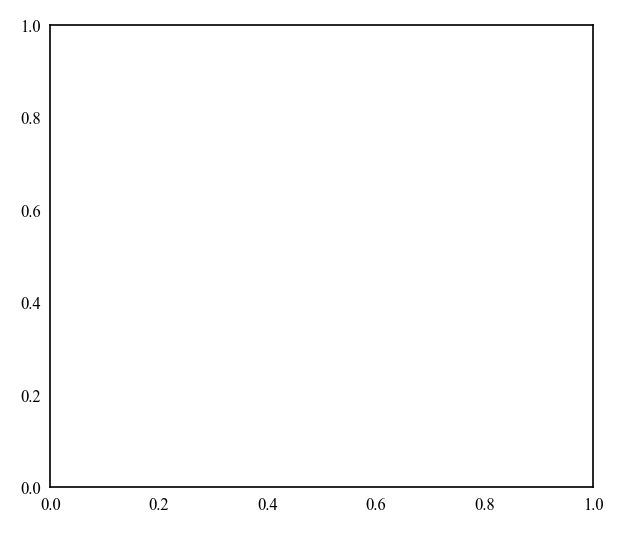

In [23]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.lines as mlines
from matplotlib import rcParams
import numpy as np
from scipy.ndimage import gaussian_filter1d

# ── Springer Single-Column Typography ────────────────────────────────────────
# rcParams.update({
#     "font.family":      "serif",
#     "font.serif":       ["Times New Roman"],
#     "font.size":        8,
#     "axes.labelsize":   8,
#     "xtick.labelsize":  7,
#     "ytick.labelsize":  7,
#     "legend.fontsize":  6.5,
#     "axes.linewidth":   0.6,
#     "lines.linewidth":  1.1,
#     "figure.dpi":       200,
#     "savefig.bbox":     "tight",
#     "pdf.fonttype":     42,   # embeds fonts — required by most journals
#     "ps.fonttype":      42,
# })


# ── Phase 1: Academic Styling ────────────────────────────────────────────────
rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 9,
    "axes.linewidth": 0.6,
    "lines.linewidth": 0.8,
    "figure.dpi": 200,
    "xtick.labelsize": 6,   # ← add this
    "ytick.labelsize": 6,   # ← add this
    "axes.labelsize": 7,    # ← controls xlabel/ylabel size
})

# ── Setup ────────────────────────────────────────────────────────────────────
PROJECT_ROOT = Path.cwd().parent 

CONFIGS = [
    {"label": "Gemini-2.5-flash | ZeroShot | Internal Reasoning", "log_base": PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot" / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"},
    {"label": "Llama-3.1-8B-Instruct | ZeroShot", "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot" / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"},
    {"label": "Llama-3.1-8B-Instruct | CoT", "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT" / "CoT" / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"},
    {"label": "Llama-3.1-70B-Instruct | ZeroShot", "log_base": PROJECT_ROOT / "SimulationLogs" / "llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot" / "ZeroShot" /"stateful" /"vision-4" /"AgentsLogging" /"simulation_log"},
    {"label": "Qwen3-8B | ZeroShot | Internal Reasoning", "log_base": PROJECT_ROOT /"SimulationLogs" /"Qwen3-8B_ZeroShot" /"ZeroShot" /"stateful" /"vision-4" /"AgentsLogging" /"simulation_log"},
    {"label": "Qwen2.5-32B-Instruct  | ZeroShot", "log_base": PROJECT_ROOT /"SimulationLogs" /"Qwen2.5-32B-Instruct-AWQ_ZeroShot" /"ZeroShot" /"stateful" /"vision-4" /"AgentsLogging" /"simulation_log"},
]
TARGET_AGENTS = ["Citizens", "Pillars", "Activists", "Police"]

# Professional "Light" Palette (Muted Pastels)
# These are distinct but soft, appearing professional in print.
LIGHT_COLORS = ["#A6CEE3", "#B2DF8A", "#FB9A99", "#FDBF6F"] 



PROJECT_ROOT = Path.cwd().parent

CONFIGS = [
    {
        "label":     "Gemini-2.5-Flash",
        "short":     "Gemini-2.5-Flash",
        "technique": "ZS",
        "log_base":  PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot"
                     / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":     "Llama-3.1-8B | ZeroShot",
        "short":     "Llama-3.1-8B",
        "technique": "ZS",
        "log_base":  PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot"
                     / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":     "Llama-3.1-8B | CoT",
        "short":     "Llama-3.1-8B",
        "technique": "CoT",
        "log_base":  PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT" / "CoT"
                     / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":     "Llama-3.1-70B | ZeroShot",
        "short":     "Llama-3.1-70B",
        "technique": "ZS",
        "log_base":  PROJECT_ROOT / "SimulationLogs" / "llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot" / "ZeroShot"
                     / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":     "Qwen3-8B | CoT",
        "short":     "Qwen3-8B",
        "technique": "CoT",
        "log_base":  PROJECT_ROOT / "SimulationLogs" / "qwen3-8B_ZeroShot" / "ZeroShot"
                     / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":     "Qwen2.5-32B | ZeroShot",
        "short":     "Qwen2.5-32B",
        "technique": "ZS",
        "log_base":  PROJECT_ROOT / "SimulationLogs" / "Qwen2.5-32B-Instruct-AWQ_ZeroShot" / "ZeroShot"
                     / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
]

# Colorblind-safe, print-safe palette
COLORS = ["#2166AC", "#B2182B", "#4DAC26", "#E66101", "#542788", "#01665E"]

# Solid = ZeroShot, Dashed = CoT — survives greyscale printing
LINESTYLES = {"ZS": "-", "CoT": "--"}

MAX_STEPS    = 200
SMOOTH_SIGMA = 5


def run_plot():
    # Extra height for the below-axis legend
    fig, ax = plt.subplots(figsize=(3.5, 3.0))
    steps = np.arange(1, MAX_STEPS + 1)

    for i, cfg in enumerate(CONFIGS):
        color = COLORS[i % len(COLORS)]
        technique = cfg["technique"]
        ls = LINESTYLES[technique]
        rate = load_invalid_rate(cfg["log_base"])

        valid_mask = ~np.isnan(rate)
        if valid_mask.sum() < 2:
            continue

        rate_filled = np.interp(steps, steps[valid_mask], rate[valid_mask])
        smoothed    = gaussian_filter1d(rate_filled, sigma=SMOOTH_SIGMA)
        mu          = np.nanmean(rate)

        ax.plot(
            steps, smoothed,
            color=color, linestyle=ls, linewidth=1.1,
            label=f"{cfg['short']} ({technique}, $\\mu$={mu:.1f}\\%)",
        )

        # Only shade low-rate lines — avoids the pink flood dominating
        if mu < 15:
            ax.fill_between(steps, smoothed, alpha=0.10, color=color, linewidth=0)

    # ── Axes ─────────────────────────────────────────────────────────────────
    ax.set_xlabel(r"Simulation Step Index ($t$)", fontsize=8)
    ax.set_ylabel(r"Invalid Target Selection Rate (\%)", fontsize=8)
    ax.set_xlim(1, MAX_STEPS)
    ax.set_ylim(0, 100)

    ax.yaxis.set_major_formatter(mticker.PercentFormatter())
    ax.yaxis.set_major_locator(mticker.MultipleLocator(20))
    ax.xaxis.set_major_locator(mticker.MultipleLocator(50))

    ax.grid(axis="y", linestyle=":", linewidth=0.4, alpha=0.6, color="0.6")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", length=2, width=0.6)

    # ── Legend — below the plot, no overlap ──────────────────────────────────
    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        ncol=2,
        columnspacing=0.8,
        handletextpad=0.4,
        handlelength=2.0,        # long enough to show dashes clearly
        frameon=True,
        framealpha=0.9,
        edgecolor="0.8",
        fontsize=5,
    )

    # ── Linestyle key — one line, below legend ────────────────────────────────
    # fig.text(
    #     0.5, -0.1,
    #     r"$-$ Zero-Shot $\quad$ $--$ Chain-of-Thought",
    #     ha="center", va="center", fontsize=6, color="0.4",
    #     transform=ax.transAxes,
    # )

    plt.savefig("figure_invalid_targeting.pdf", dpi=300, bbox_inches="tight")
    plt.savefig("figure_invalid_targeting.png", dpi=300, bbox_inches="tight")  # preview copy
    plt.show()

run_plot()


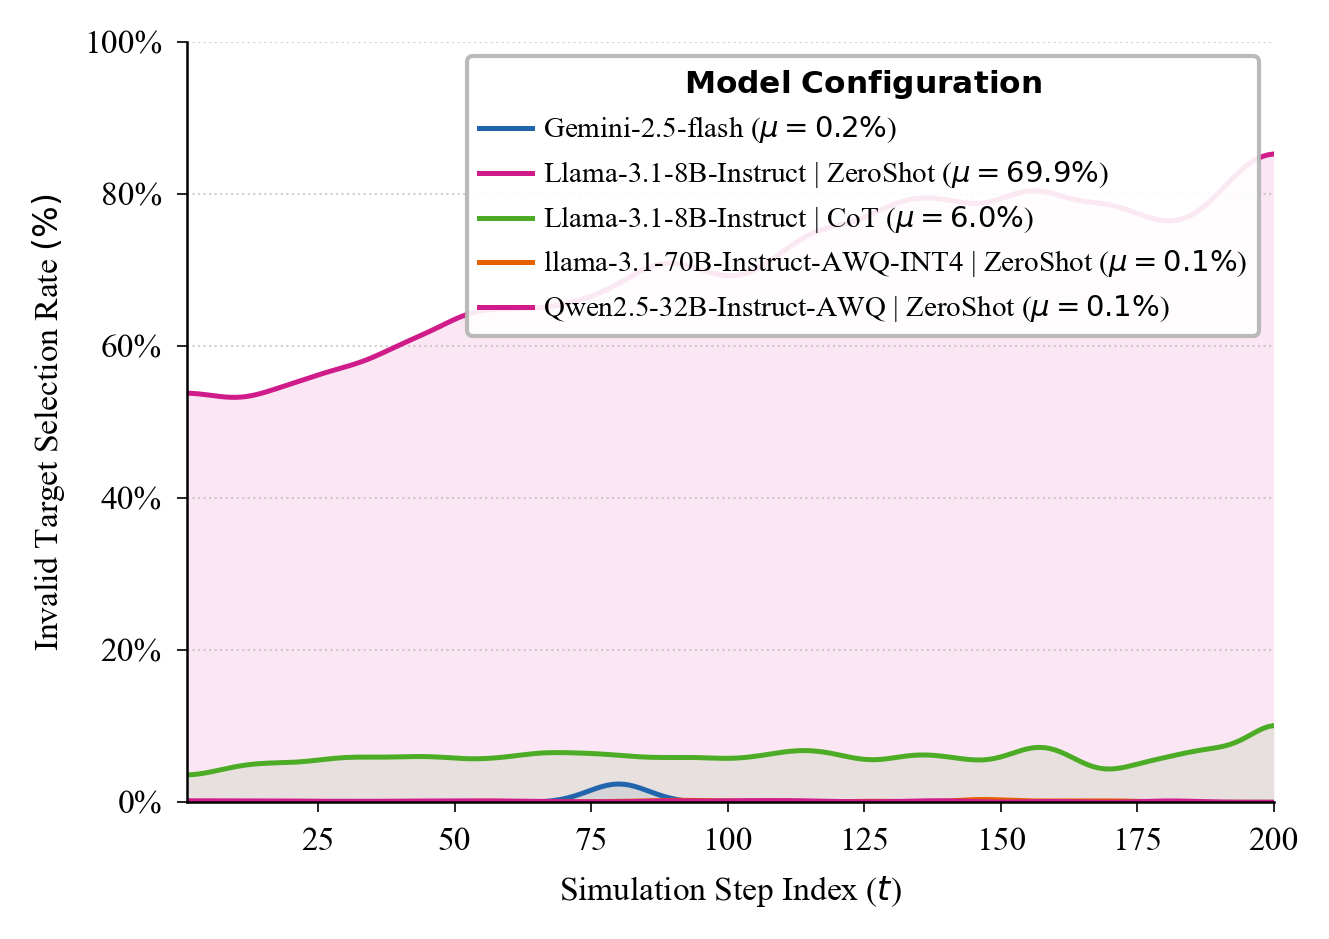

Saved: figure_invalid_targeting.pdf / .png


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib import rcParams
import glob
import numpy as np
from pathlib import Path
from scipy.ndimage import gaussian_filter1d

# ── Publication style settings (Consistent with your Targeting Strategy sample) ──
rcParams.update({
    "font.family":         "serif",
    "font.serif":          ["Times New Roman", "DejaVu Serif"],
    "font.size":           9,
    "axes.titlesize":      9,
    "axes.labelsize":      9,
    "xtick.labelsize":     8,
    "ytick.labelsize":     8,
    "legend.fontsize":     7.5,
    "axes.linewidth":      0.8,
    "grid.linewidth":      0.5,
    "lines.linewidth":     1.2,
    "figure.dpi":          300,
    "savefig.dpi":         300,
    "savefig.bbox":        "tight",
    "text.usetex":         False,
})

PROJECT_ROOT = Path.cwd().parent
CONFIGS = [
    {
        "label":   "Gemini-2.5-flash",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot"
                   / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":   "Llama-3.1-8B-Instruct | ZeroShot",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":   "Llama-3.1-8B-Instruct | CoT",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT" / "CoT"
                   / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":   "llama-3.1-70B-Instruct-AWQ-INT4 | ZeroShot",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":   "Qwen3-8B| CoT",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "qwen3-8B_ZeroShot_0-85" / "ZeroShot"
                   / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":   "Qwen2.5-32B-Instruct-AWQ | ZeroShot",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "Qwen2.5-32B-Instruct-AWQ_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
]


# Professional color palette from your sample
COLORS       = ["#2166AC", "#D01C8B", "#4DAC26", "#E66101"]
MAX_STEPS    = 200
SMOOTH_SIGMA = 5

# ── Loader: invalid % per step ────────────────────────────────────────────────
def load_invalid_rate(log_base: Path) -> np.ndarray:
    pattern = str(log_base / "structured" / "activists_logs" / "activists_logs_v*.csv")
    files   = sorted(glob.glob(pattern))

    total_counts   = np.zeros(MAX_STEPS, dtype=float)
    invalid_counts = np.zeros(MAX_STEPS, dtype=float)

    for path_str in files:
        df = pd.read_csv(path_str)
        if df.empty or "Step" not in df.columns or "target_validity" not in df.columns:
            continue
        df["Step"] = pd.to_numeric(df["Step"], errors='coerce')
        df = df[df["Step"] <= MAX_STEPS].copy()
        df["target_validity"] = df["target_validity"].astype(str).str.strip().str.upper()
        df = df[df["target_validity"].isin(["VALID", "INVALID"])]

        step_groups = df.groupby("Step")
        for step, grp in step_groups:
            idx = int(step) - 1
            total_counts[idx]   += len(grp)
            invalid_counts[idx] += (grp["target_validity"] == "INVALID").sum()

    with np.errstate(invalid='ignore', divide='ignore'):
        rate = np.where(total_counts > 0, invalid_counts / total_counts * 100, np.nan)
    return rate

# ── Plotting ──────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(4.5, 3.2)) # Single column width
# fig, ax = plt.subplots(figsize=(3.3, 2.8))
steps   = np.arange(1, MAX_STEPS + 1)

for i, cfg in enumerate(CONFIGS):
    color = COLORS[i % len(COLORS)]
    rate  = load_invalid_rate(cfg["log_base"])

    # Interpolate NaNs before smoothing to prevent gaps in the line
    valid_mask = ~np.isnan(rate)
    if valid_mask.sum() > 1:
        # Fill NaNs with 0 or interpolated values for a continuous line
        rate_filled = np.interp(steps, steps[valid_mask], rate[valid_mask])
        smoothed = gaussian_filter1d(rate_filled, sigma=SMOOTH_SIGMA)
        
        overall_invalid = np.nanmean(rate)
        
        ax.plot(steps, smoothed, color=color, 
                label=f"{cfg['label']} ($\mu={overall_invalid:.1f}\%$)")
        ax.fill_between(steps, smoothed, alpha=0.1, color=color, linewidth=0)

# ── Refined Formatting ────────────────────────────────────────────────────────
# Scientific Title
# ax.set_title("Targeting Fidelity Across Model Scales", 
#              fontsize=9, fontweight="bold", loc="left", pad=8)
# ax.set_title("Temporal Dynamics of Erroneous Agent Targeting", 
#              fontsize=9, fontweight="bold", loc="left", pad=8)

ax.set_xlabel(r"Simulation Step Index ($t$)", fontsize=8)
ax.set_ylabel(r"Invalid Target Selection Rate $(\%)$", fontsize=8)

ax.set_xlim(1, MAX_STEPS)
ax.set_ylim(0, 100)

# Formatting ticks and grid
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(axis='y', linestyle=':', linewidth=0.5, alpha=0.6)
ax.tick_params(axis='both', length=2.5)

# Spine cleanup (IEEE/ACM Standard)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(0.6)
ax.spines["bottom"].set_linewidth(0.6)

# Legend inside the box
ax.legend(
    title=r"$\bf{Model\ Configuration}$",
    title_fontsize=7.5,
    loc="upper right",
    fontsize=7,
    frameon=True,
    framealpha=0.9,
    edgecolor="0.7"
)


plt.tight_layout()
plt.savefig("figure_invalid_targeting.pdf", format="pdf")
plt.savefig("figure_invalid_targeting.png", format="png")
plt.show()

print("Saved: figure_invalid_targeting.pdf / .png")

TypeError: Invalid comparison between dtype=str and int

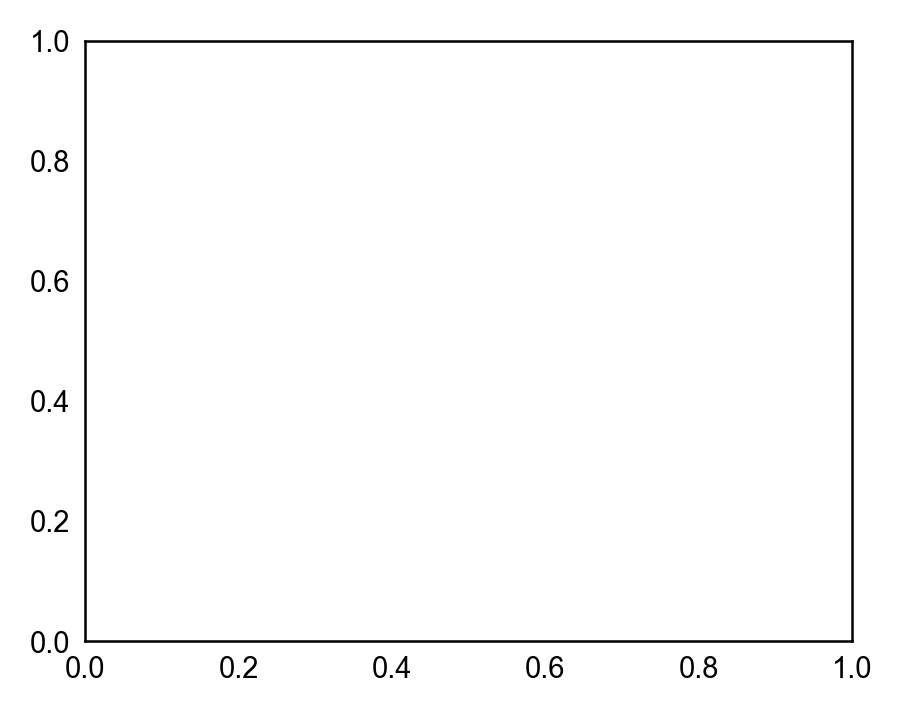

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib as mpl
import glob
import numpy as np
from pathlib import Path
from scipy.ndimage import gaussian_filter1d

# ── Clean Publication Style (Nature-like) ─────────────────────────────────────
def set_nature_style():
    mpl.rcParams.update({
        "figure.figsize": (3.3, 2.6),
        "figure.dpi": 300,
        "savefig.dpi": 600,
        "savefig.bbox": "tight",

        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "font.size": 8,

        "axes.linewidth": 0.6,
        "axes.labelsize": 8,
        "axes.titlesize": 9,

        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "xtick.direction": "out",
        "ytick.direction": "out",

        "legend.fontsize": 6,

        "lines.linewidth": 1.8,

        "axes.facecolor": "white",
        "figure.facecolor": "white",
    })

set_nature_style()

# ── Config ───────────────────────────────────────────────────────────────────
PROJECT_ROOT = Path.cwd().parent

COLORS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]  # clean palette
MAX_STEPS = 200
SMOOTH_SIGMA = 1   # reduced smoothing (more honest)

# Example CONFIGS (keep yours)
# CONFIGS = [...]

# ── Loader ───────────────────────────────────────────────────────────────────
def load_invalid_rate(log_base: Path) -> np.ndarray:
    pattern = str(log_base / "structured" / "activists_logs" / "activists_logs_v*.csv")
    files = sorted(glob.glob(pattern))

    total_counts = np.zeros(MAX_STEPS)
    invalid_counts = np.zeros(MAX_STEPS)

    for path_str in files:
        df = pd.read_csv(path_str)

        if df.empty or "Step" not in df or "target_validity" not in df:
            continue

        df = df[df["Step"] <= MAX_STEPS].copy()
        df["target_validity"] = df["target_validity"].astype(str).str.upper()

        df = df[df["target_validity"].isin(["VALID", "INVALID"])]

        for step, grp in df.groupby("Step"):
            idx = int(step) - 1
            total_counts[idx] += len(grp)
            invalid_counts[idx] += (grp["target_validity"] == "INVALID").sum()

    with np.errstate(divide='ignore', invalid='ignore'):
        rate = np.where(total_counts > 0, invalid_counts / total_counts * 100, np.nan)

    return rate

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots()

# Force clean background (important)
ax.set_facecolor("white")
fig.patch.set_facecolor("white")

steps = np.arange(1, MAX_STEPS + 1)

for i, cfg in enumerate(CONFIGS):
    color = COLORS[i % len(COLORS)]
    rate = load_invalid_rate(cfg["log_base"])

    valid = ~np.isnan(rate)
    if valid.sum() < 2:
        continue

    rate_interp = np.interp(steps, steps[valid], rate[valid])
    smoothed = gaussian_filter1d(rate_interp, sigma=SMOOTH_SIGMA)

    # Short labels (clean)
    short_label = cfg["label"].replace("ZeroShot", "ZS").replace("Instruct", "").replace("|", "")

    ax.plot(steps, smoothed, color=color, label=short_label)

    # VERY subtle uncertainty shading (optional)
    # ax.fill_between(steps, smoothed, color=color, alpha=0.05)

# ── Formatting ────────────────────────────────────────────────────────────────
ax.set_xlim(1, MAX_STEPS)
ax.set_ylim(0, 100)

ax.set_xlabel("Simulation step")
ax.set_ylabel("Invalid target rate")

ax.yaxis.set_major_formatter(mticker.PercentFormatter())

# Subtle grid (y only)
ax.grid(axis='y', linestyle='--', linewidth=0.4, alpha=0.2)
ax.grid(axis='x', visible=False)

# Clean spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Centered, minimal title
ax.set_title("Temporal dynamics of targeting errors")

# Legend OUTSIDE (cleanest)
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    handlelength=1.2
)

plt.tight_layout()

# ── Save ─────────────────────────────────────────────────────────────────────
plt.savefig("figure_clean.pdf")   # vector (for paper)
plt.savefig("figure_clean.png")   # preview
plt.show()

print("Saved: figure_clean.pdf / .png")

In [ ]:
!pip install seaborn -q

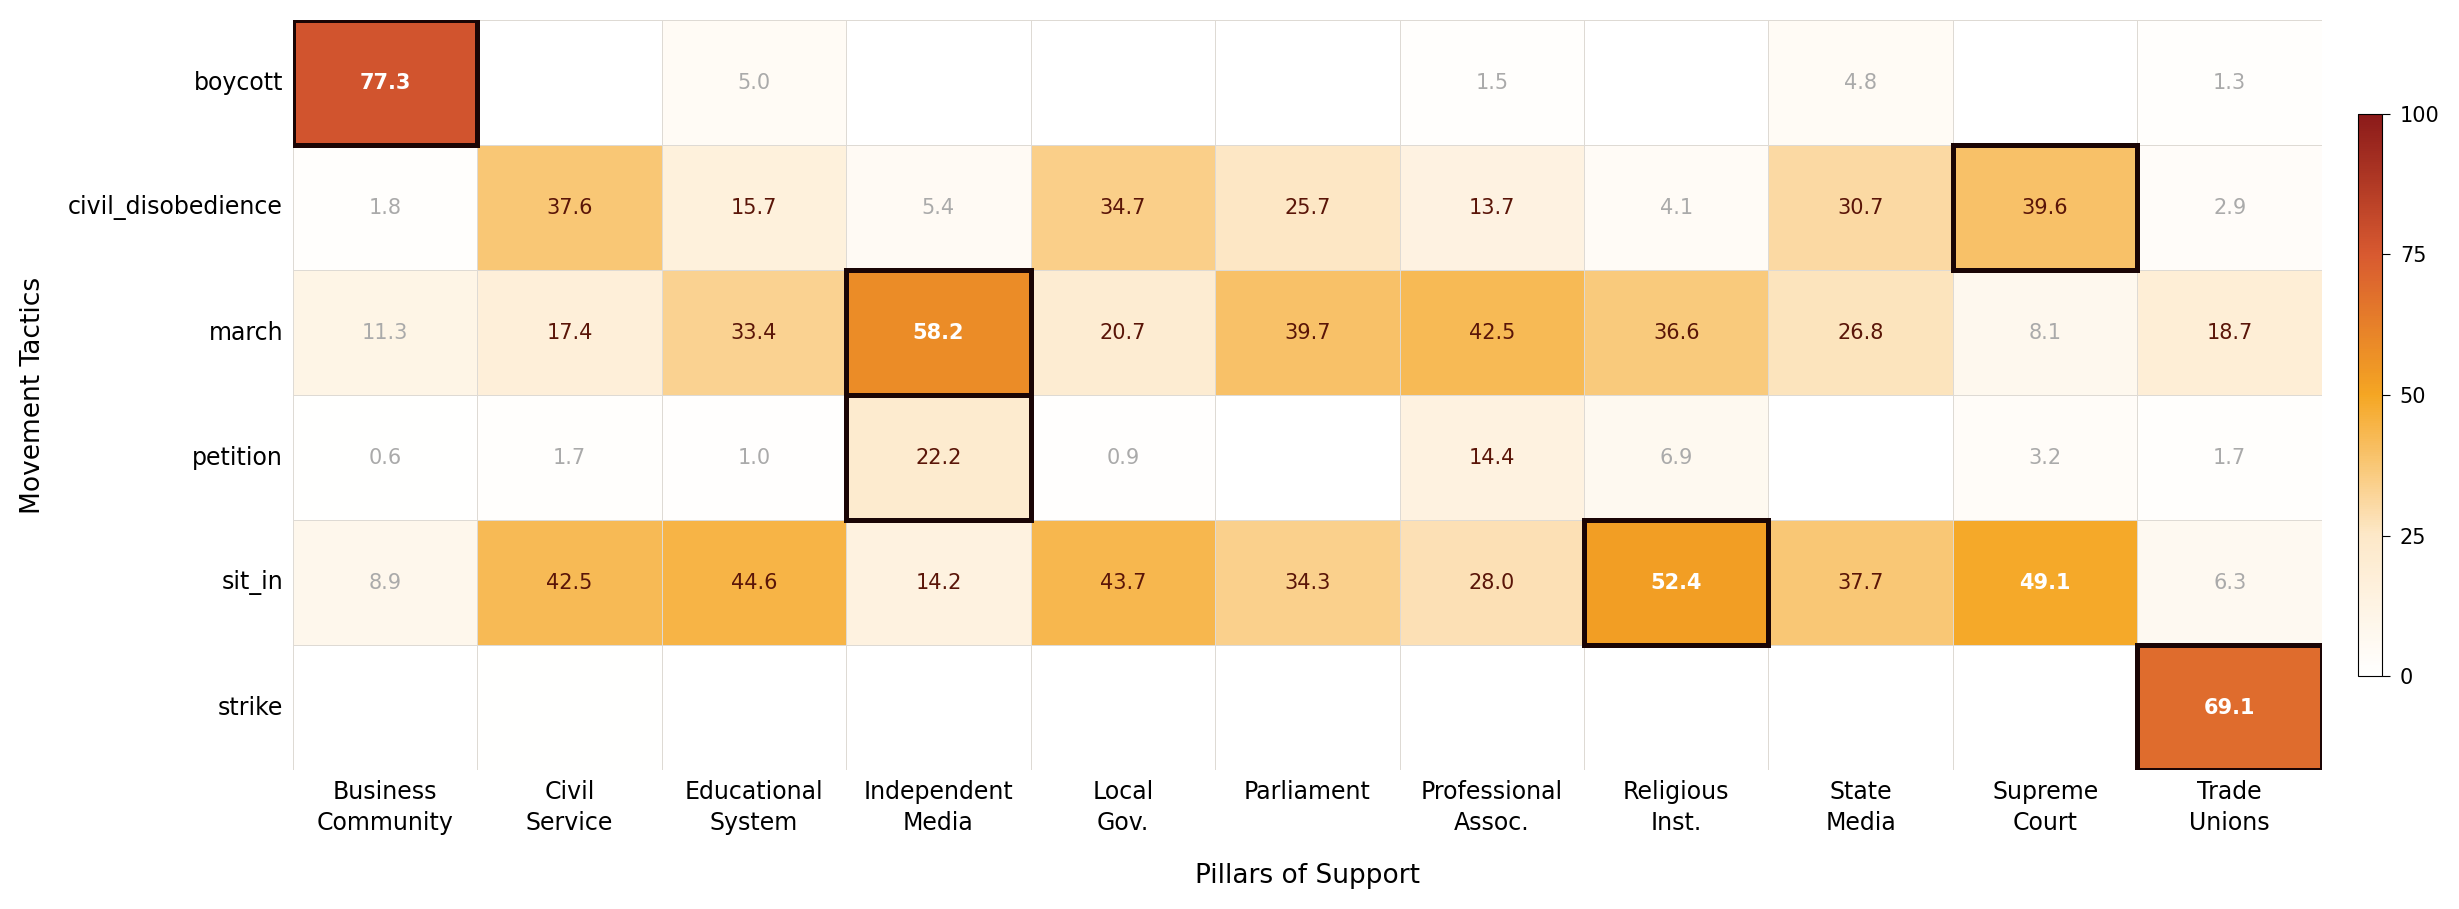

  Gemini-2.5-flash  ->  fig_cta_heatmap_Gemini-2-5-flash.pdf  and  fig_cta_heatmap_Gemini-2-5-flash.png


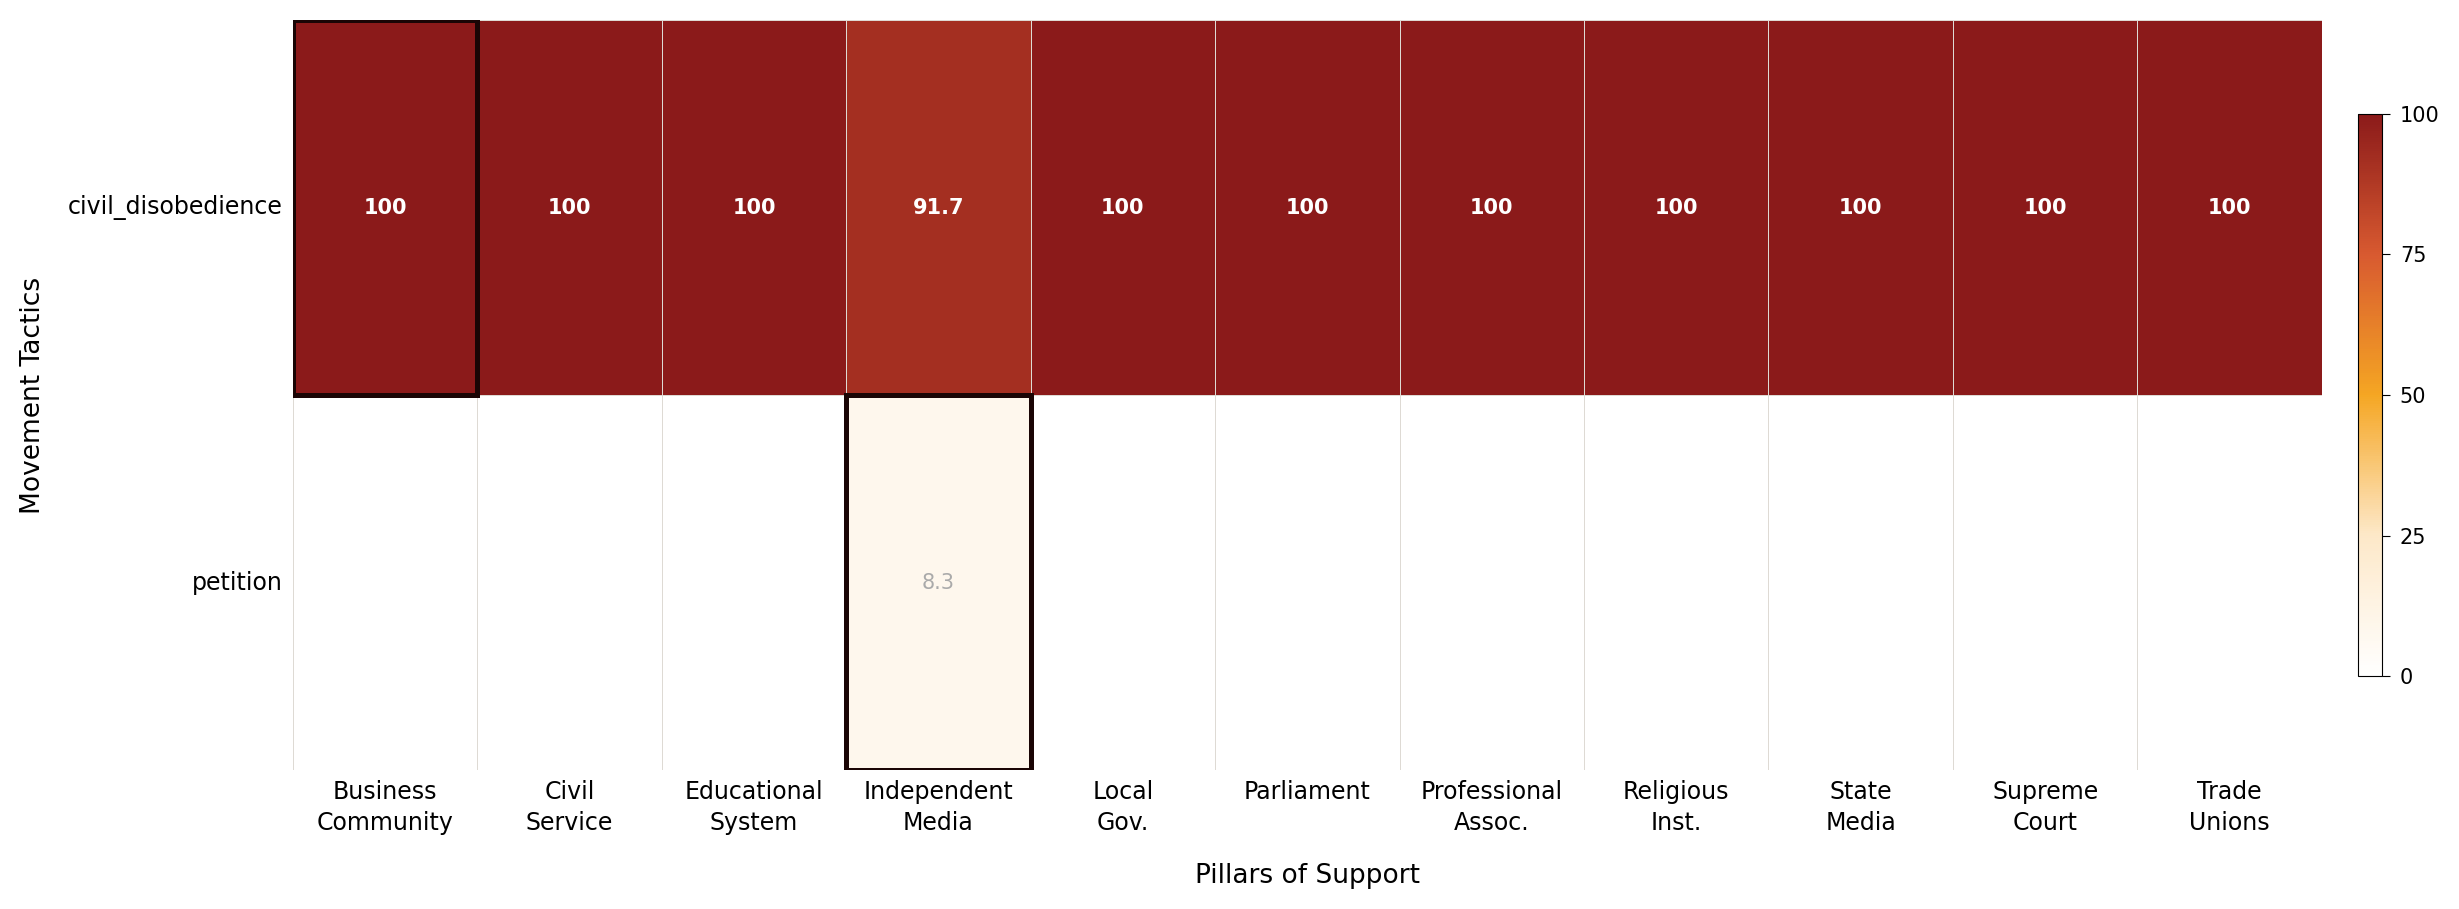

  Llama-3.1-8B-Instruct_ZeroShot  ->  fig_cta_heatmap_Llama-3-1-8B-Instruct_ZeroShot.pdf  and  fig_cta_heatmap_Llama-3-1-8B-Instruct_ZeroShot.png


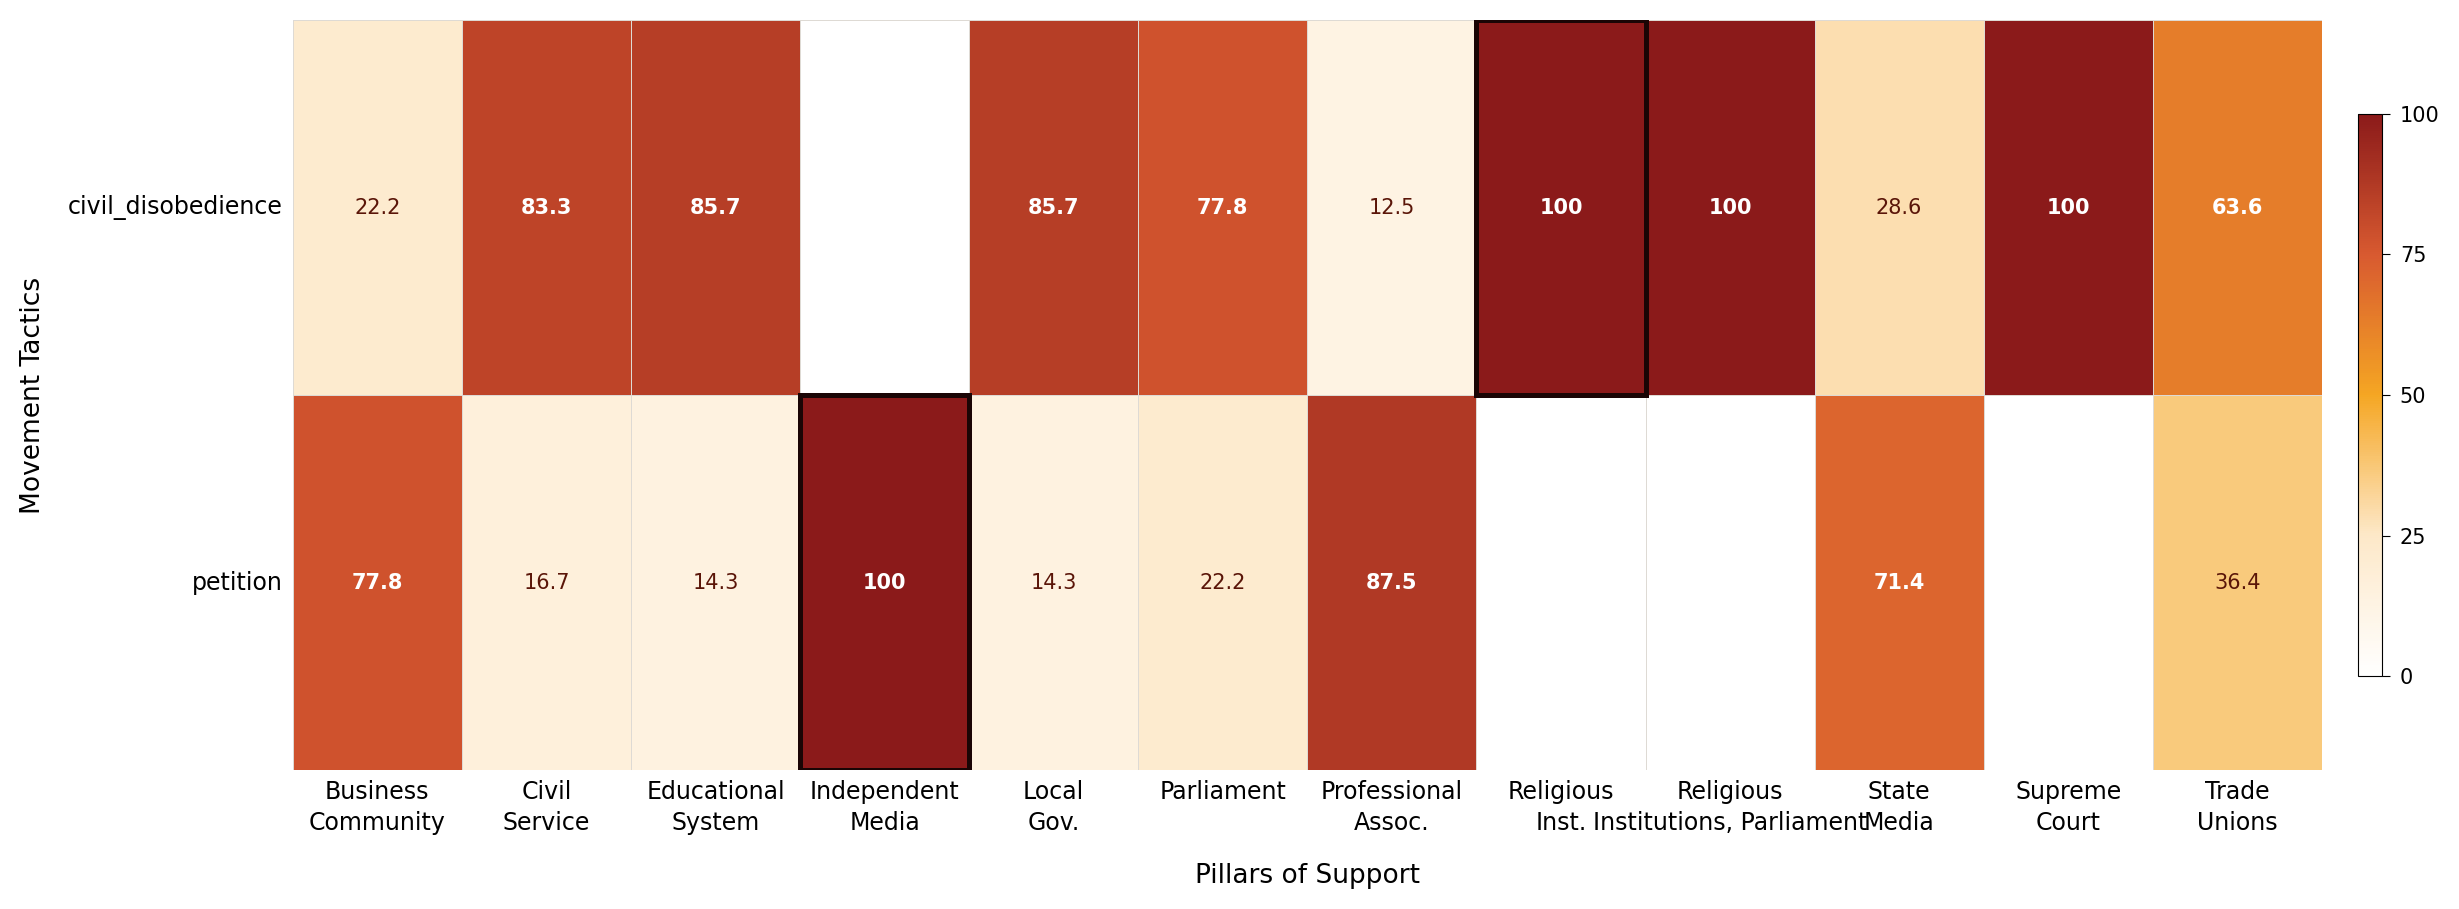

  Llama-3.1-8B-Instruct_CoT  ->  fig_cta_heatmap_Llama-3-1-8B-Instruct_CoT.pdf  and  fig_cta_heatmap_Llama-3-1-8B-Instruct_CoT.png


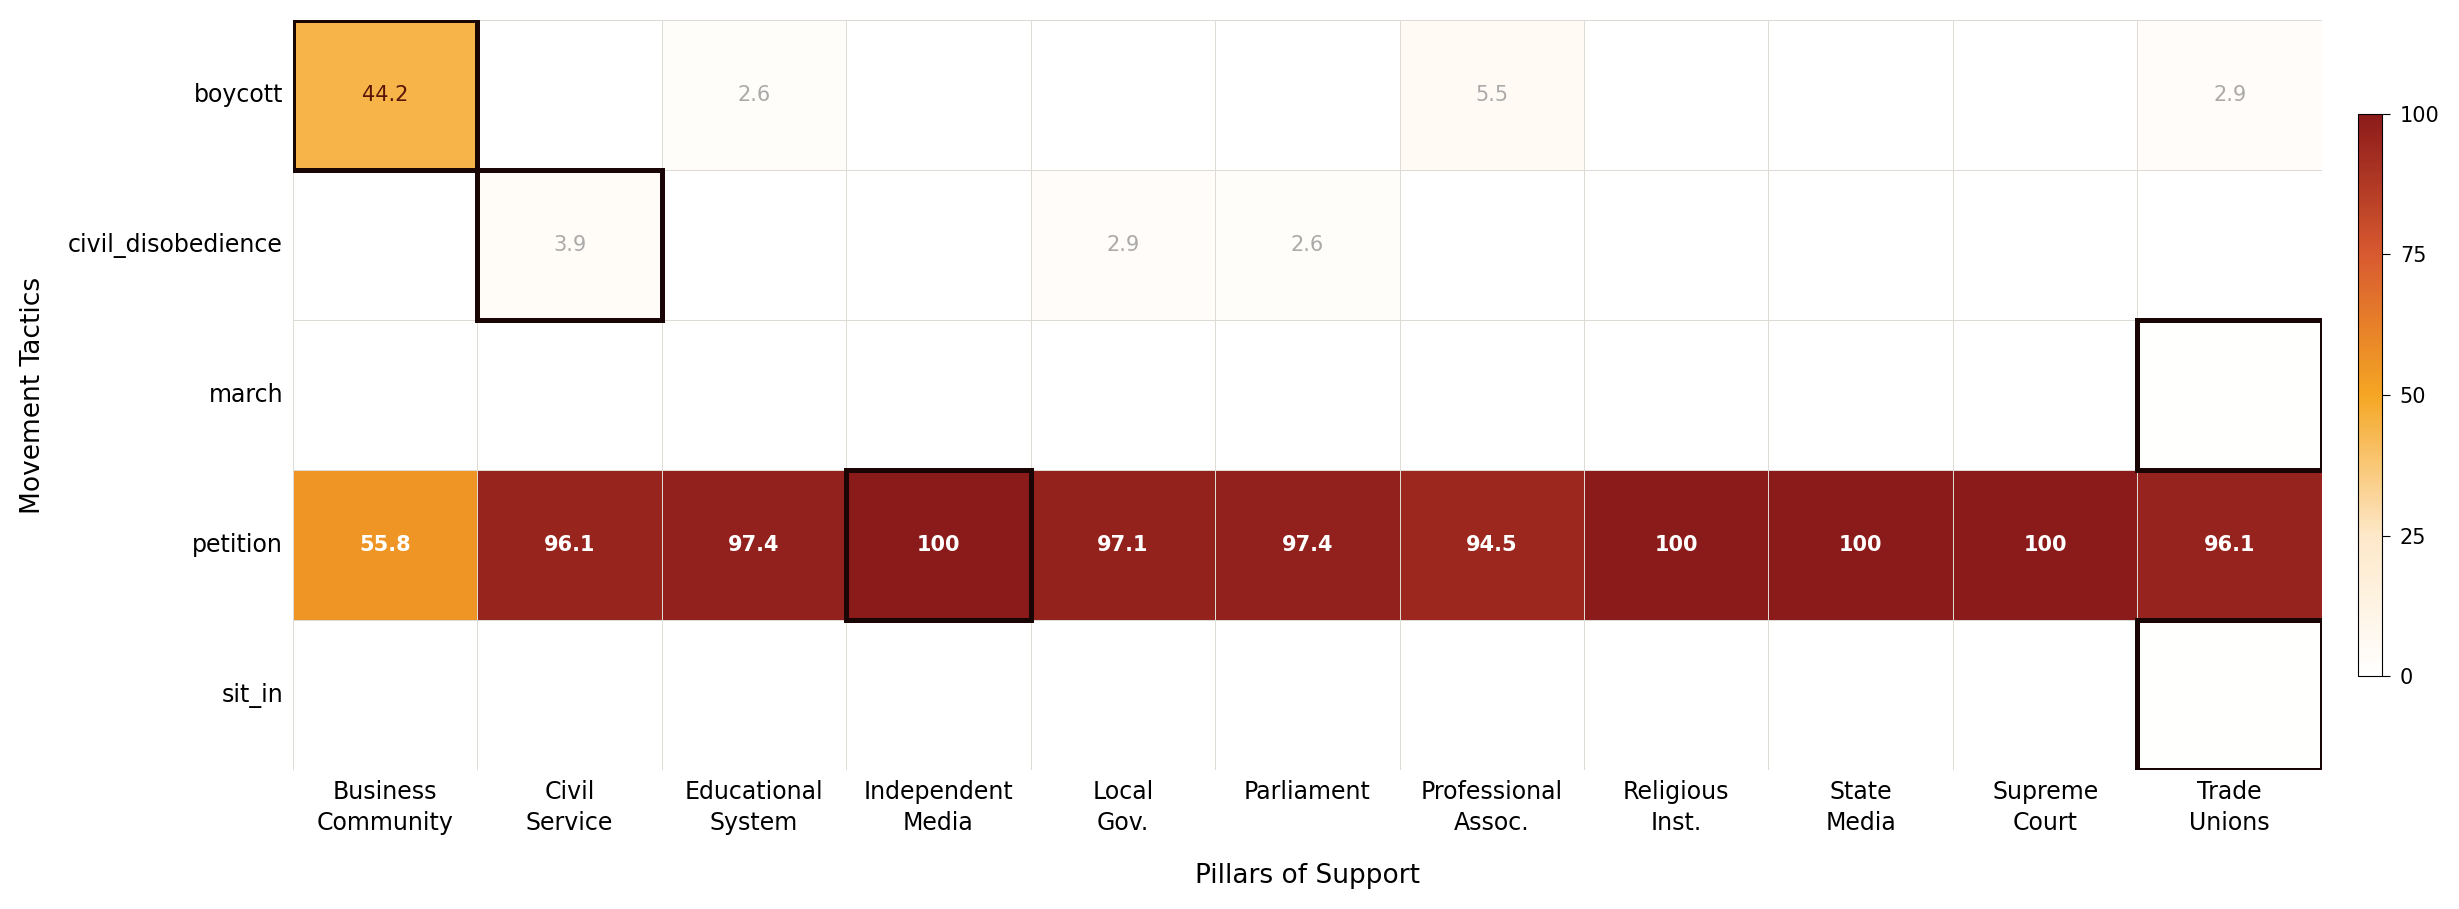

  llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot  ->  fig_cta_heatmap_llama-3-1-70B-Instruct-AWQ-INT4_ZeroShot.pdf  and  fig_cta_heatmap_llama-3-1-70B-Instruct-AWQ-INT4_ZeroShot.png


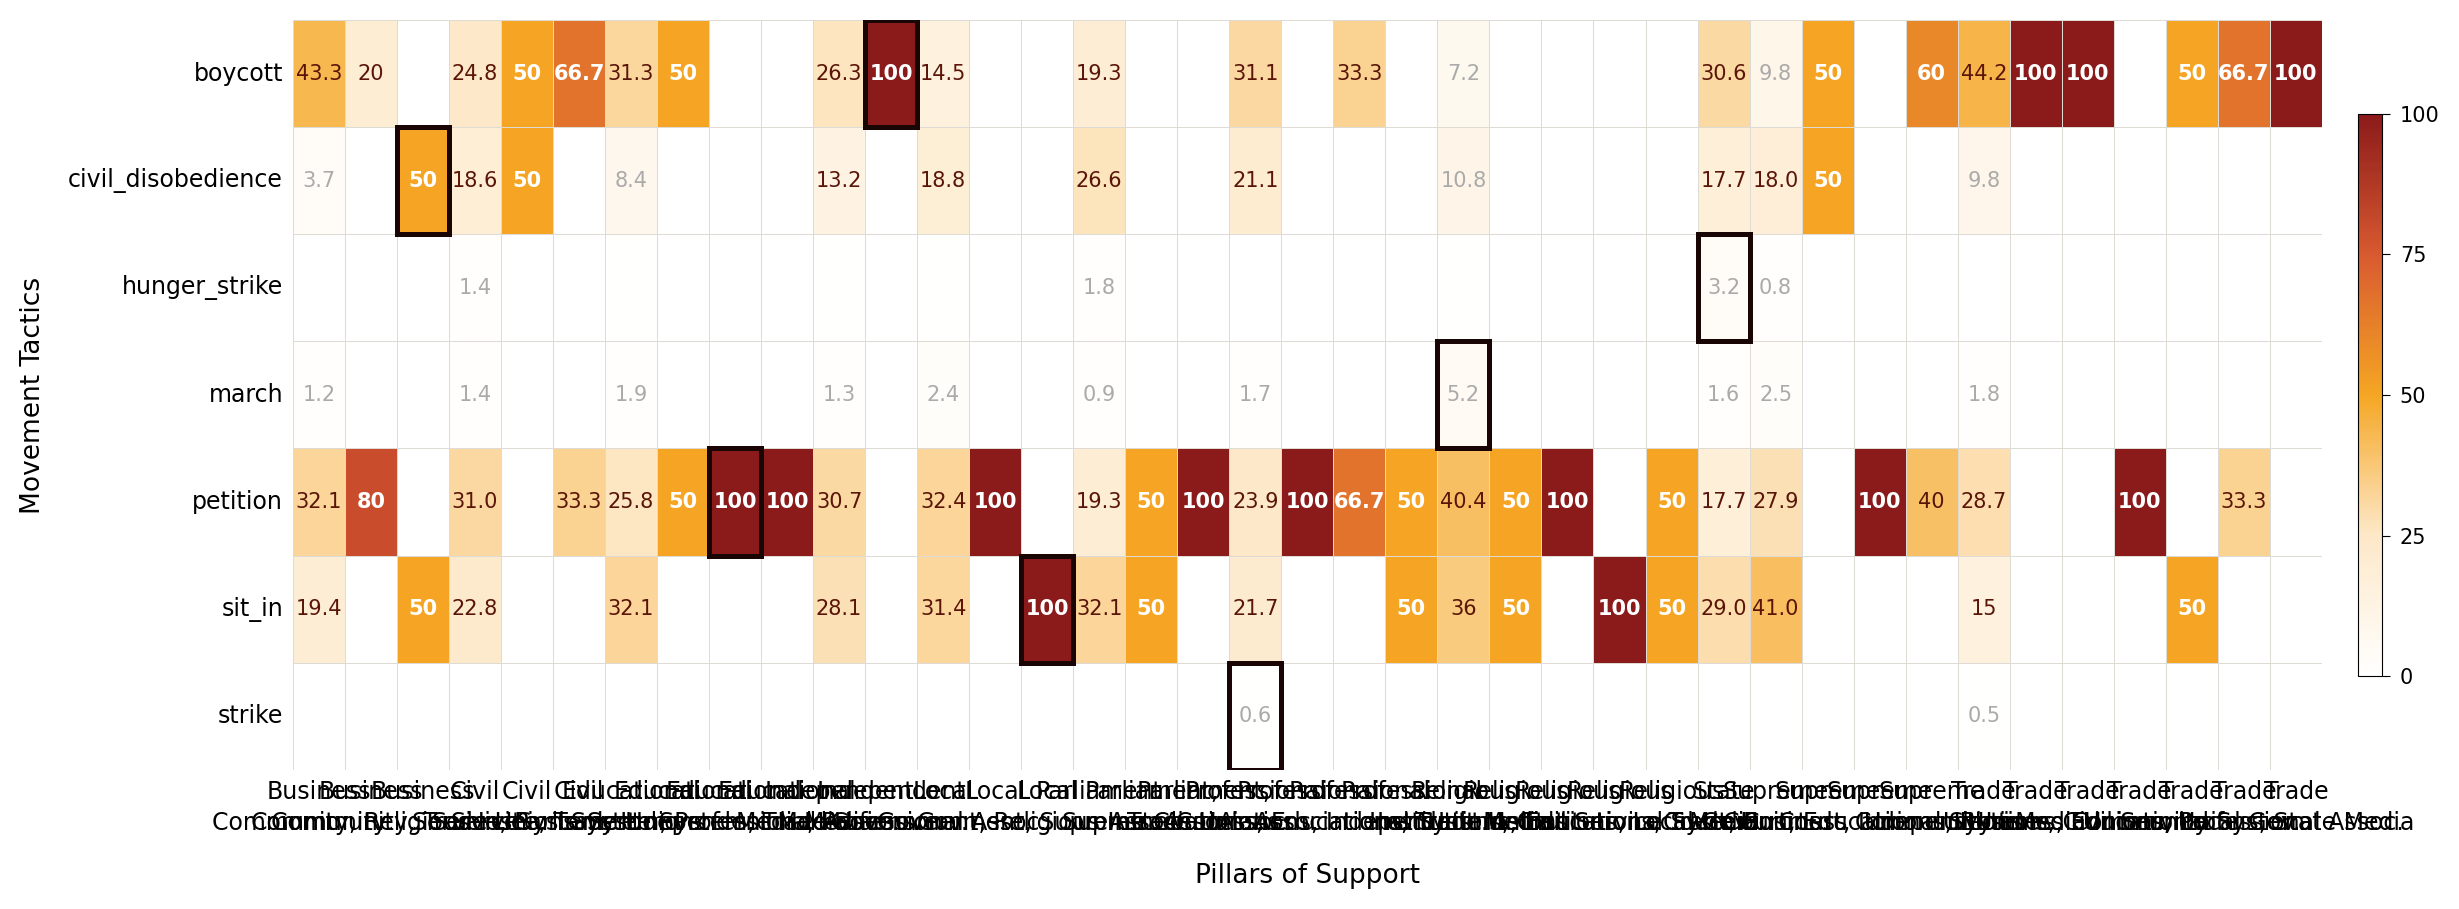

  Qwen3-8B_ZeroShot  ->  fig_cta_heatmap_Qwen3-8B_ZeroShot.pdf  and  fig_cta_heatmap_Qwen3-8B_ZeroShot.png


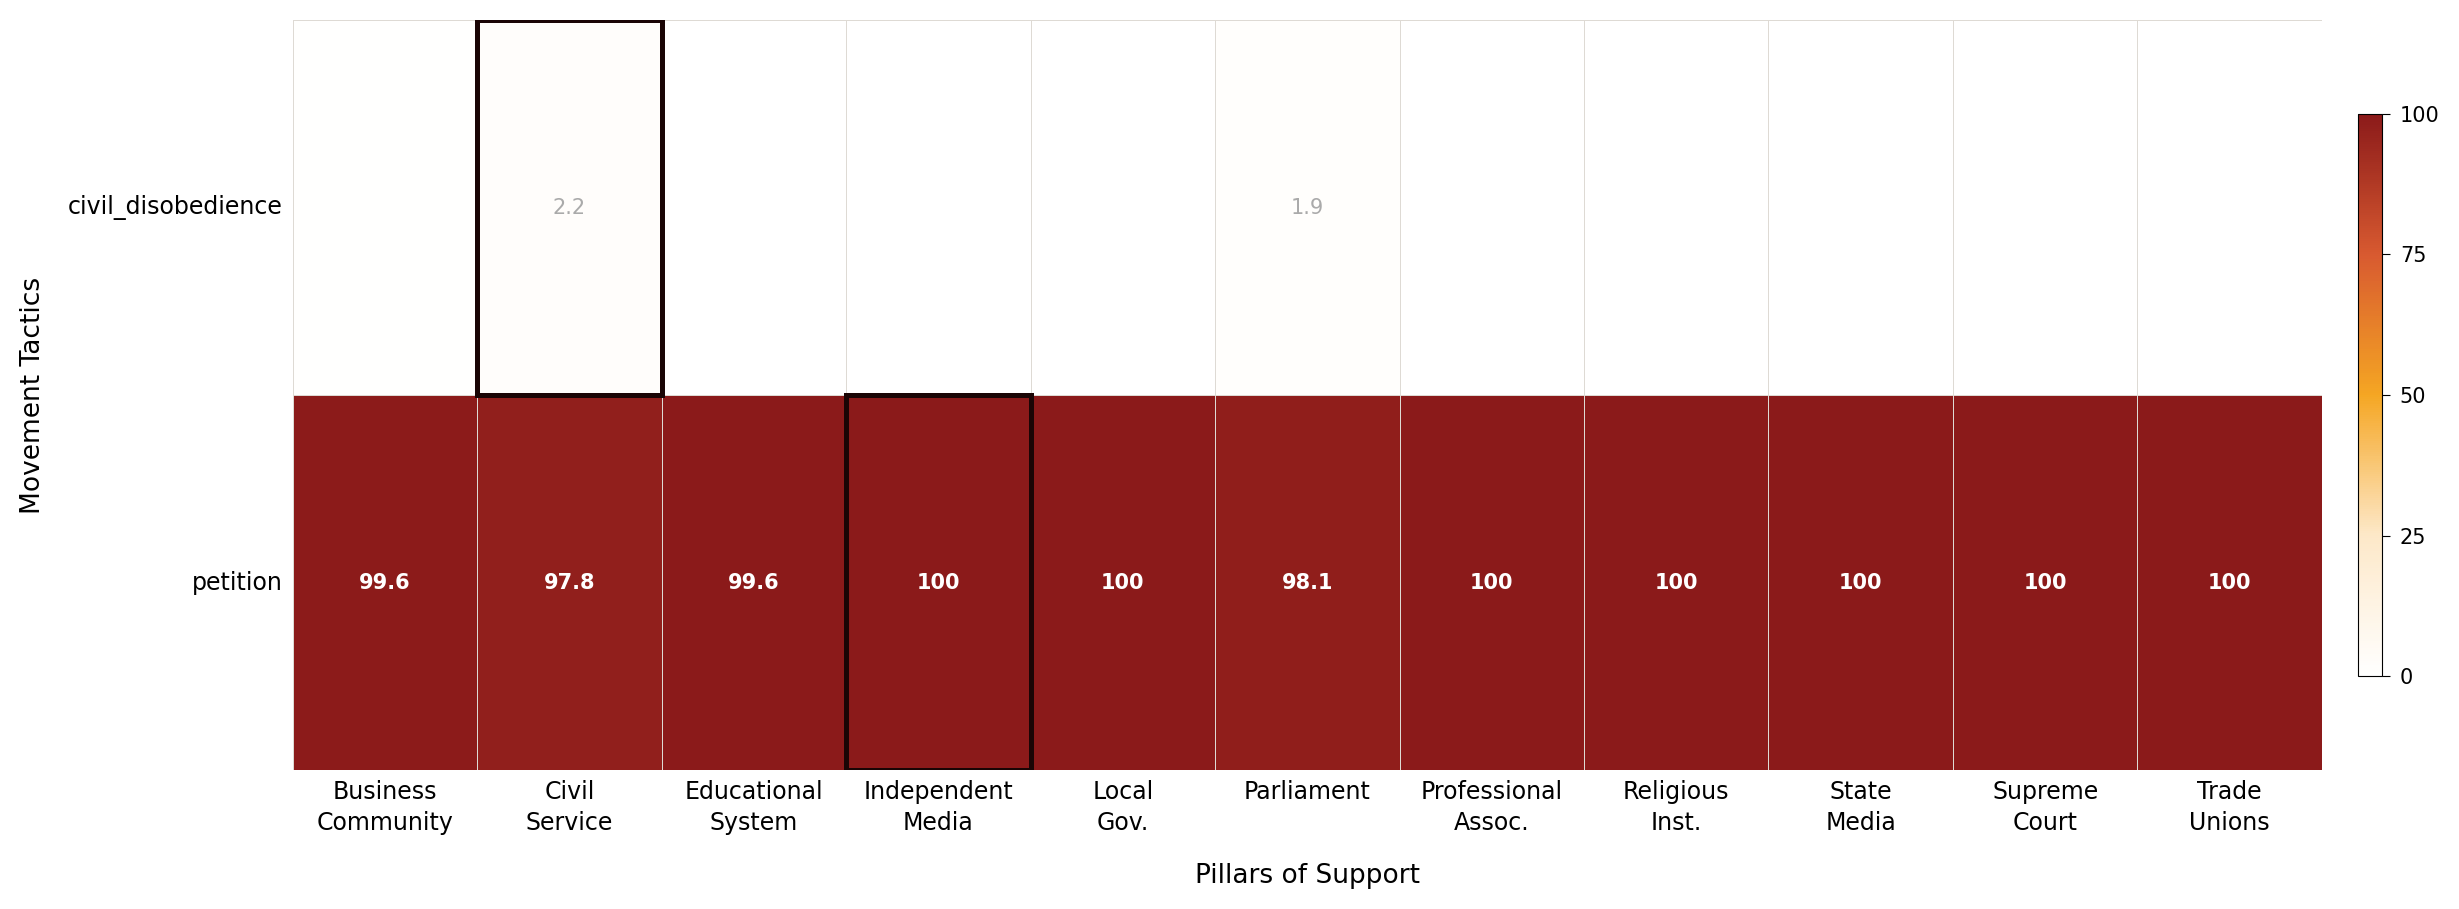

  Qwen2.5-32B-Instruct-AWQ_ZeroShot  ->  fig_cta_heatmap_Qwen2-5-32B-Instruct-AWQ_ZeroShot.pdf  and  fig_cta_heatmap_Qwen2-5-32B-Instruct-AWQ_ZeroShot.png


In [24]:
"""
fig_cta_heatmap.py
==================
Publication-quality Call-to-Action × Target Pillar Institution heatmap.
No title, no caption, no focus-index panel.
X-axis labels are horizontal, word-wrapped to two lines.

Requirements:
    pip install matplotlib seaborn numpy pandas

Outputs:
    fig_cta_heatmap_<model>.pdf   ← submit to journal (vector, fonts embedded)
    fig_cta_heatmap_<model>.png   ← 300 DPI for Word / quick preview
"""

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

# =============================================================================
# CONFIGURATION
# =============================================================================

PROJECT_ROOT = Path.cwd().parent
CONFIGS = [
    {
        "label":   "Gemini-2.5-flash",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot"
                   / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":   "Llama-3.1-8B-Instruct_ZeroShot",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":   "Llama-3.1-8B-Instruct_CoT",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT" / "CoT"
                   / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":   "llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":   "Qwen3-8B_ZeroShot",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "qwen3-8B_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":   "Qwen2.5-32B-Instruct-AWQ_ZeroShot",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "Qwen2.5-32B-Instruct-AWQ_ZeroShot" / "ZeroShot"
                   / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
]

TARGET_AGENTS = ["citizens", "pillars", "activists", "police"]

# Font — swap to "Times New Roman" for IEEE/Springer
FONT_FAMILY     = "DejaVu Sans"
FONT_SIZE_ANNOT = 7.5
FONT_SIZE_TICK  = 8.5
FONT_SIZE_LABEL = 9.5

FIG_WIDTH  = 15.0    # inches — double-column; use 3.5 for single-column
FIG_HEIGHT = 5.0
DPI        = 300

# =============================================================================
# HELPERS
# =============================================================================

# Abbreviation map for long words that would overflow a narrow column
_ABBREV = {
    "Associations": "Assoc.",
    "Institutions": "Inst.",
    "Government":   "Gov.",
}


def wrap_label(s: str) -> str:
    """
    Word-wrap a target institution name to two horizontal lines.
    Replaces underscores, applies common abbreviations, then splits
    so that line 1 holds the first word and line 2 holds the rest.

    Examples
    --------
    "Business Community"         -> "Business\\nCommunity"
    "Professional Associations"  -> "Professional\\nAssoc."
    "Parliament"                 -> "Parliament"
    "Local Government"           -> "Local\\nGov."
    """
    s = s.replace("_", " ").strip()
    words = [_ABBREV.get(w, w) for w in s.split()]
    if len(words) == 1:
        return words[0]
    return f"{words[0]}\n{' '.join(words[1:])}"


def clean_annot(val: float) -> str:
    """Format cell value: blank for near-zero, integer if whole, 1 dp otherwise."""
    if val < 0.5:
        return ""
    return str(int(round(val))) if val == int(val) else f"{val:.1f}"


def annot_color(val: float) -> str:
    """Text color for a given cell value."""
    if val >= 45:
        return "white"
    if val >= 12:
        return "#5A1508"
    return "#AAAAAA"


# =============================================================================
# COLORMAP  white → light amber → orange → dark coral-red
# =============================================================================

CMAP = LinearSegmentedColormap.from_list(
    "nv_heat",
    ["#FFFFFF", "#FDE8C8", "#F5A623", "#D85A30", "#8B1A1A"],
    N=256,
)

# =============================================================================
# MATPLOTLIB GLOBAL SETTINGS
# =============================================================================

matplotlib.rcParams.update({
    "font.family":        FONT_FAMILY,
    "font.size":          FONT_SIZE_ANNOT,
    "axes.linewidth":     0.6,
    "xtick.major.width":  0.4,
    "ytick.major.width":  0.4,
    "xtick.major.size":   0,
    "ytick.major.size":   0,
    "pdf.fonttype":       42,   # embed fonts — required by most journals
    "ps.fonttype":        42,
})

# =============================================================================
# MAIN — one figure per active config
# =============================================================================

for cfg in CONFIGS:

    # ── Load & filter ─────────────────────────────────────────────────────────
    csv_files = sorted(cfg["log_base"].glob("**/*.csv"))
    if not csv_files:
        print(f"[WARN] No CSV files found in {cfg['log_base']}")
        continue

    df = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)

    df = df[
        (df["event"] == "movement_decision") &
        (df["target_agent"].isin(TARGET_AGENTS))
    ]
    df = df[df["target_agent"] == "pillars"]

    # ── Crosstab: cta (rows) × target pillar institution (columns) ────────────
    ct = (
        pd.crosstab(df["citizen_cta"], df["target_pillar_inst"], normalize="columns")
        * 100
    )

    # ── Prepare arrays ────────────────────────────────────────────────────────
    data    = ct.values
    actions = [str(a) for a in ct.index]
    targets = [wrap_label(str(t)) for t in ct.columns]

    annot_arr = np.vectorize(clean_annot)(data)

    # ── Figure ────────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))
    # fig, axes = plt.subplots(len(CONFIGS), 1, figsize=(FIG_WIDTH, FIG_HEIGHT * len(CONFIGS)))

    # bottom=0.22 gives the two-line x-labels enough room without a title eating
    # space at the top.  Increase bottom if labels still clip.
    fig.subplots_adjust(left=0.12, right=0.93, top=0.97, bottom=0.22)

    sns.heatmap(
        data,
        ax=ax,
        cmap=CMAP,
        vmin=0,
        vmax=100,
        annot=annot_arr,
        fmt="",
        annot_kws={"size": FONT_SIZE_ANNOT},
        linewidths=0.35,
        linecolor="#DEDAD4",
        cbar=True,
        cbar_kws={
            "shrink":   0.75,
            "aspect":   24,
            "pad":      0.015,
            "ticks":    [0, 25, 50, 75, 100],
        },
        xticklabels=targets,
        yticklabels=actions,
    )

    # ── Colorbar ──────────────────────────────────────────────────────────────
    cbar = ax.collections[0].colorbar
    # cbar.set_label("% of simulation runs", size=FONT_SIZE_TICK, labelpad=6)
    cbar.ax.tick_params(labelsize=FONT_SIZE_TICK - 1, width=0.4, length=3)
    cbar.outline.set_linewidth(0.4)

    # ── Annotation text colors ────────────────────────────────────────────────
    for text_obj in ax.texts:
        raw = text_obj.get_text()
        if not raw:
            continue
        try:
            v = float(raw)
        except ValueError:
            continue
        text_obj.set_color(annot_color(v))
        if v >= 45:
            text_obj.set_fontweight("bold")

    # ── Bold border on dominant cell per row ──────────────────────────────────
    # for j in range(data.shape[1]):          # loop over columns
    #     i_max = int(np.argmax(data[:, j]))  # max in column

    #     rect = matplotlib.patches.Rectangle(
    #         (j, i_max), 1, 1,
    #         fill=False,
    #         edgecolor="#1A0505",
    #         linewidth=1.8,
    #         zorder=5,
    #     )
    #     ax.add_patch(rect)
    for i, row in enumerate(data):
        j_max = int(np.argmax(row))
        rect = matplotlib.patches.Rectangle(
            (j_max, i), 1, 1,
            fill=False,
            edgecolor="#1A0505",
            linewidth=1.8,
            zorder=5,
        )
        ax.add_patch(rect)

    # ── X-axis: horizontal, two-line labels ───────────────────────────────────
    ax.set_xticklabels(
        ax.get_xticklabels(),
        fontsize=FONT_SIZE_TICK,
        rotation=0,        # flat — no tilt
        ha="center",
        va="top",
        linespacing=1.4,   # space between the two wrapped lines
    )

    # ── Y-axis ────────────────────────────────────────────────────────────────
    ax.set_yticklabels(
        ax.get_yticklabels(),
        fontsize=FONT_SIZE_TICK,
        rotation=0,
        va="center",
    )

    # ── Axis labels ───────────────────────────────────────────────────────────
    ax.set_xlabel("Pillars of Support", fontsize=FONT_SIZE_LABEL, labelpad=10)
    ax.set_ylabel("Movement Tactics", fontsize=FONT_SIZE_LABEL, labelpad=8)

    # ── Subtle row separator lines ────────────────────────────────────────────
    for y in range(1, len(actions)):
        ax.axhline(y, color="#DEDAD4", linewidth=0.35, zorder=2)

    # ── Save ──────────────────────────────────────────────────────────────────
    slug     = cfg["label"].replace(" ", "_").replace(".", "-")
    pdf_path = f"fig_cta_heatmap_{slug}.pdf"
    png_path = f"fig_cta_heatmap_{slug}.png"

    plt.savefig(pdf_path, dpi=DPI, bbox_inches="tight")
    plt.savefig(png_path, dpi=DPI, bbox_inches="tight")
    plt.show()
    print(f"  {cfg['label']}  ->  {pdf_path}  and  {png_path}")


In [ ]:
"""
fig_cta_heatmap_all_models.py
==============================
One row per model — all models in a single manuscript figure.
Shared column order, shared colorbar, single x-axis label at bottom.
"""

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

# =============================================================================
# CONFIGURATION  (unchanged from your original)
# =============================================================================

PROJECT_ROOT = Path.cwd().parent
CONFIGS = [
    {
        "label":    "Gemini-2.5-Flash (ZS)",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot"
                    / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":    "Llama-3.1-8B (ZS)",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot"
                    / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":    "Llama-3.1-8B (CoT)",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT" / "CoT"
                    / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":    "Llama-3.1-70B (ZS)",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot" / "ZeroShot"
                    / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":    "Qwen3-8B (CoT)",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "qwen3-8B_ZeroShot" / "ZeroShot"
                    / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":    "Qwen2.5-32B (ZS)",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "Qwen2.5-32B-Instruct-AWQ_ZeroShot" / "ZeroShot"
                    / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
]

FONT_FAMILY     = "Times New Roman"
FONT_SIZE_ANNOT = 6.5
FONT_SIZE_TICK  = 7.5
FONT_SIZE_LABEL = 8.5
FONT_SIZE_ROW   = 7.5   # model label on the left

DPI = 300

matplotlib.rcParams.update({
    "font.family":    FONT_FAMILY,
    "font.size":      FONT_SIZE_ANNOT,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.4,
    "ytick.major.width": 0.4,
    "xtick.major.size":  0,
    "ytick.major.size":  0,
    "pdf.fonttype":   42,
    "ps.fonttype":    42,
})

CMAP = LinearSegmentedColormap.from_list(
    "nv_heat",
    ["#FFFFFF", "#FDE8C8", "#F5A623", "#D85A30", "#8B1A1A"],
    N=256,
)

_ABBREV = {
    "Associations": "Assoc.",
    "Institutions": "Inst.",
    "Government":   "Gov.",
}

def wrap_label(s: str) -> str:
    s = s.replace("_", " ").strip()
    words = [_ABBREV.get(w, w) for w in s.split()]
    return words[0] if len(words) == 1 else f"{words[0]}\n{' '.join(words[1:])}"

def clean_annot(val: float) -> str:
    if val < 0.5:
        return ""
    return str(int(round(val))) if val == int(val) else f"{val:.1f}"

def annot_color(val: float) -> str:
    if val >= 45:   return "white"
    if val >= 12:   return "#5A1508"
    return "#AAAAAA"

# =============================================================================
# STEP 1 — load all data, build shared row/column order
# =============================================================================

all_data:   dict[str, pd.DataFrame] = {}   # label -> crosstab
all_rows:   set[str] = set()
all_cols:   set[str] = set()

for cfg in CONFIGS:
    csv_files = sorted(cfg["log_base"].glob("**/*.csv"))
    if not csv_files:
        print(f"[WARN] No CSV files in {cfg['log_base']}")
        continue

    df = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)
    df = df[
        (df["event"] == "movement_decision") &
        (df["target_agent"] == "pillars")
    ]
    if df.empty:
        print(f"[WARN] No pillar-targeting events for {cfg['label']}")
        continue

    ct = (
        pd.crosstab(df["citizen_cta"], df["target_pillar_inst"], normalize="columns")
        * 100
    )
    all_data[cfg["label"]] = ct
    all_rows.update(ct.index.tolist())
    all_cols.update(ct.columns.tolist())

# Shared, stable ordering across all subplots
SHARED_ROWS = sorted(all_rows)
SHARED_COLS = sorted(all_cols)

active_configs = [c for c in CONFIGS if c["label"] in all_data]
n = len(active_configs)

if n == 0:
    raise RuntimeError("No data found for any config.")

# =============================================================================
# STEP 2 — figure layout
# =============================================================================

ROW_HEIGHT  = 1.6   # inches per model row — adjust if y-labels clip
FIG_WIDTH   = 14.0  # inches — double-column manuscript width

fig, axes = plt.subplots(
    n, 1,
    figsize=(FIG_WIDTH, ROW_HEIGHT * n + 0.8),   # +0.8 for x-label at bottom
    gridspec_kw={"hspace": 0.08},                # tight vertical gap
)

if n == 1:
    axes = [axes]

# Shared colorbar axis — carved from the right
fig.subplots_adjust(left=0.13, right=0.91, top=0.98, bottom=0.12)
cbar_ax = fig.add_axes([0.925, 0.12, 0.012, 0.86])  # [left, bottom, w, h]

# =============================================================================
# STEP 3 — draw each row
# =============================================================================

im = None   # will hold the heatmap mappable for the shared colorbar

for idx, (cfg, ax) in enumerate(zip(active_configs, axes)):
    ct  = all_data[cfg["label"]]
    is_last = (idx == n - 1)

    # Reindex to shared order — missing cells become 0
    ct_aligned = ct.reindex(index=SHARED_ROWS, columns=SHARED_COLS, fill_value=0.0)
    data = ct_aligned.values

    annot_arr = np.vectorize(clean_annot)(data)

    im = sns.heatmap(
        data,
        ax=ax,
        cmap=CMAP,
        vmin=0, vmax=100,
        annot=annot_arr,
        fmt="",
        annot_kws={"size": FONT_SIZE_ANNOT},
        linewidths=0.30,
        linecolor="#DEDAD4",
        cbar=False,                    # one shared colorbar added after the loop
        xticklabels=is_last,           # only bottom row gets x-labels
        yticklabels=SHARED_ROWS,
    )

    # ── annotation text color + bold dominant ─────────────────────────────────
    for text_obj in ax.texts:
        raw = text_obj.get_text()
        if not raw:
            continue
        try:
            v = float(raw)
        except ValueError:
            continue
        text_obj.set_color(annot_color(v))
        if v >= 45:
            text_obj.set_fontweight("bold")

    # ── dominant cell border per row ─────────────────────────────────────────
    for i, row in enumerate(data):
        j_max = int(np.argmax(row))
        ax.add_patch(mpatches.Rectangle(
            (j_max, i), 1, 1,
            fill=False, edgecolor="#1A0505", linewidth=1.6, zorder=5,
        ))

    # ── y-axis: CTA labels ───────────────────────────────────────────────────
    ax.set_yticklabels(
        ax.get_yticklabels(),
        fontsize=FONT_SIZE_TICK,
        rotation=0, va="center",
    )
    ax.set_ylabel("")

    # ── model label — left margin text ───────────────────────────────────────
    ax.text(
        -0.10, 0.5, cfg["label"],
        transform=ax.transAxes,
        fontsize=FONT_SIZE_ROW, fontweight="bold",
        va="center", ha="right", rotation=0,
    )

    # ── x-axis: only the bottom subplot ──────────────────────────────────────
    if is_last:
        wrapped = [wrap_label(str(c)) for c in SHARED_COLS]
        ax.set_xticklabels(
            wrapped,
            fontsize=FONT_SIZE_TICK,
            rotation=0, ha="center", va="top", linespacing=1.4,
        )
        ax.set_xlabel("Pillars of Support", fontsize=FONT_SIZE_LABEL, labelpad=10)
    else:
        ax.set_xticklabels([])
        ax.set_xlabel("")
        ax.tick_params(axis="x", length=0)

# =============================================================================
# STEP 4 — shared colorbar
# =============================================================================

sm = plt.cm.ScalarMappable(cmap=CMAP, norm=plt.Normalize(vmin=0, vmax=100))
sm.set_array([])
cb = fig.colorbar(sm, cax=cbar_ax, ticks=[0, 25, 50, 75, 100])
cb.ax.tick_params(labelsize=FONT_SIZE_TICK - 1, width=0.4, length=3)
cb.outline.set_linewidth(0.4)
cb.set_label("% within pillar column", size=FONT_SIZE_TICK, labelpad=6)

# Shared y-axis label across all rows
fig.text(
    0.03, 0.55, "Movement Tactics",
    va="center", ha="center",
    rotation=90, fontsize=FONT_SIZE_LABEL,
)

# =============================================================================
# STEP 5 — save
# =============================================================================

plt.savefig("fig_cta_heatmap_all_models.pdf", dpi=DPI, bbox_inches="tight")
plt.savefig("fig_cta_heatmap_all_models.png", dpi=DPI, bbox_inches="tight")
plt.show()
print("Saved: fig_cta_heatmap_all_models.pdf / .png")

In [ ]:
for cfg in CONFIGS:
    csv_files = sorted(cfg["log_base"].glob("**/*.csv"))

    if not csv_files:
        continue

    for f in csv_files:
        df = pd.read_csv(f)
        df = df[
            (df["event"] == "movement_decision") &
            (df["target_agent"] == "pillars")
        ]
        # Multi-label entries contain a comma
        multi = df[df["target_pillar_inst"].astype(str).str.contains(",", na=False)]

        if not multi.empty:
            print(f"Processing {f}...")
            print(f"\n{f.name}  ({len(multi)} multi-label rows)")
            print(multi["target_pillar_inst"].value_counts().to_string())

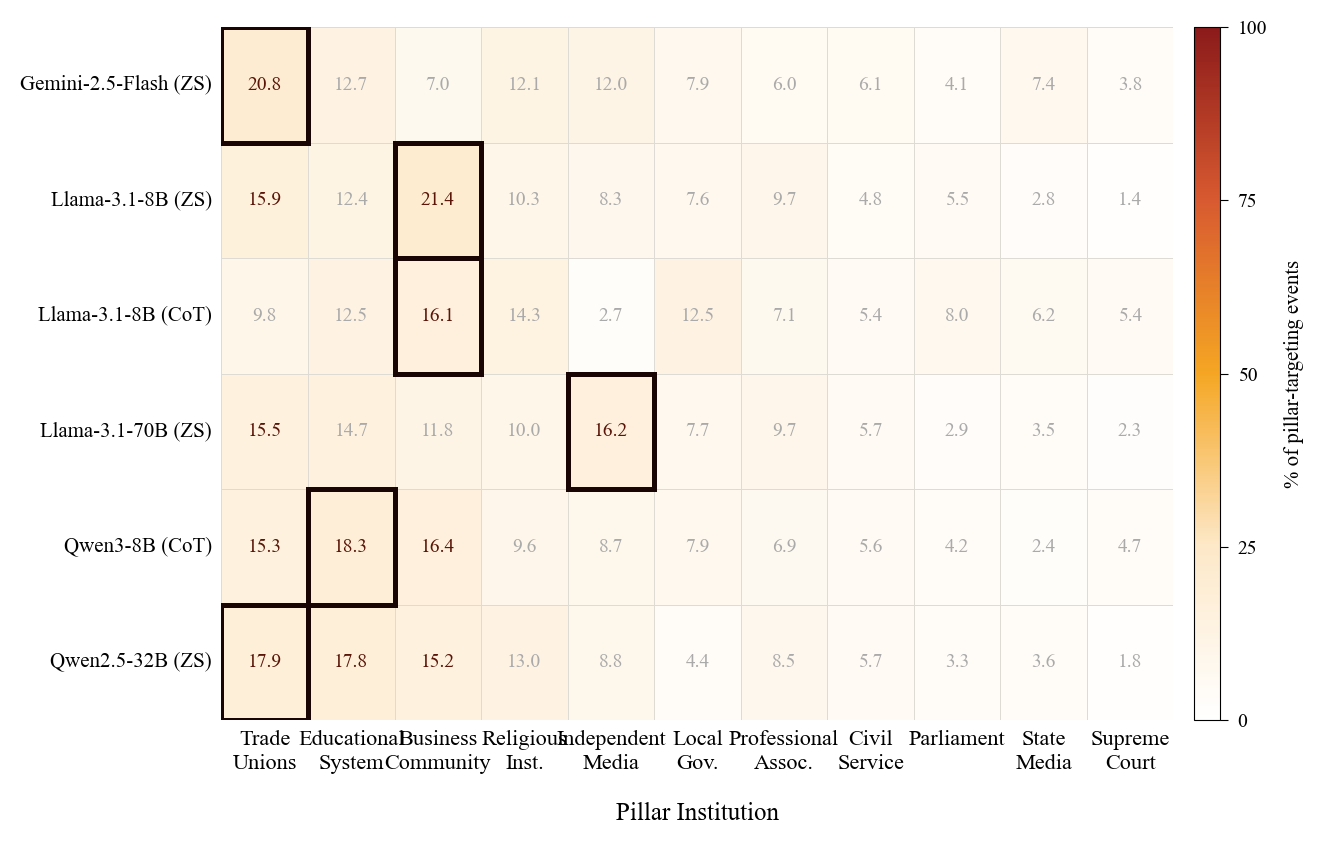

Saved: fig_pillar_distribution.pdf / .png


In [ ]:
"""
fig_pillar_distribution.py
===========================
Heatmap: rows = models, cols = pillar institutions
Values  = % of that model's pillar-targeting events directed at each institution
Multi-label entries (e.g. "Business Community, Religious Institutions") are dropped.
"""

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

# =============================================================================
# CONFIGURATION
# =============================================================================

PROJECT_ROOT = Path.cwd().parent

CONFIGS = [
    {
        "label":    "Gemini-2.5-Flash (ZS)",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot"
                    / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":    "Llama-3.1-8B (ZS)",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot"
                    / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":    "Llama-3.1-8B (CoT)",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT" / "CoT"
                    / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":    "Llama-3.1-70B (ZS)",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot" / "ZeroShot"
                    / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":    "Qwen3-8B (CoT)",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "qwen3-8B_ZeroShot" / "ZeroShot"
                    / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
    {
        "label":    "Qwen2.5-32B (ZS)",
        "log_base": PROJECT_ROOT / "SimulationLogs" / "Qwen2.5-32B-Instruct-AWQ_ZeroShot" / "ZeroShot"
                    / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log",
    },
]

# Canonical single-institution names — anything not in this set is dropped
CANONICAL_PILLARS = {
    "Trade Unions", "Educational System", "Religious Institutions",
    "Independent Media", "Local Government", "State Media",
    "Business Community", "Civil Service", "Professional Associations",
    "Parliament", "Supreme Court",
}

FONT_FAMILY     = "Times New Roman"
FONT_SIZE_ANNOT = 7.0
FONT_SIZE_TICK  = 8.0
FONT_SIZE_LABEL = 9.0
FONT_SIZE_MODEL = 7.5
DPI             = 300

matplotlib.rcParams.update({
    "font.family":       FONT_FAMILY,
    "font.size":         FONT_SIZE_ANNOT,
    "axes.linewidth":    0.6,
    "xtick.major.width": 0.4,
    "ytick.major.width": 0.4,
    "xtick.major.size":  0,
    "ytick.major.size":  0,
    "pdf.fonttype":      42,
    "ps.fonttype":       42,
})

# white → amber → orange → deep red
CMAP = LinearSegmentedColormap.from_list(
    "pillar_heat",
    ["#FFFFFF", "#FDE8C8", "#F5A623", "#D85A30", "#8B1A1A"],
    N=256,
)

# =============================================================================
# HELPERS
# =============================================================================

_WRAP = {
    "Educational System":       "Educational\nSystem",
    "Religious Institutions":   "Religious\nInst.",
    "Independent Media":        "Independent\nMedia",
    "Local Government":         "Local\nGov.",
    "Business Community":       "Business\nCommunity",
    "Civil Service":            "Civil\nService",
    "Professional Associations":"Professional\nAssoc.",
    "Trade Unions":             "Trade\nUnions",
    "State Media":              "State\nMedia",
    "Supreme Court":            "Supreme\nCourt",
    "Parliament":               "Parliament",
}

def clean_annot(val: float) -> str:
    if val < 0.5:
        return ""
    return f"{val:.1f}"

def annot_color(val: float) -> str:
    if val >= 45:  return "white"
    if val >= 15:  return "#5A1508"
    return "#AAAAAA"

# =============================================================================
# STEP 1 — Load & build matrix  (models × pillars)
# =============================================================================

rows = []   # one dict per model

for cfg in CONFIGS:
    csv_files = sorted(cfg["log_base"].glob("**/*.csv"))
    if not csv_files:
        print(f"[WARN] no CSVs: {cfg['log_base']}")
        continue

    df = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)
    df = df[
        (df["event"] == "movement_decision") &
        (df["target_agent"] == "pillars")
    ].copy()

    # Drop multi-label entries
    df = df[df["target_pillar_inst"].isin(CANONICAL_PILLARS)]

    if df.empty:
        print(f"[WARN] no clean pillar events: {cfg['label']}")
        continue

    counts = df["target_pillar_inst"].value_counts(normalize=True) * 100
    row = {"model": cfg["label"]}
    for pillar in CANONICAL_PILLARS:
        row[pillar] = counts.get(pillar, 0.0)
    rows.append(row)

matrix = pd.DataFrame(rows).set_index("model")

# Column order: sorted by mean across models (most targeted → left)
col_order = matrix.mean(axis=0).sort_values(ascending=False).index.tolist()
matrix    = matrix[col_order]

# Row order: preserve CONFIGS order
row_order = [r["model"] for r in rows]
matrix    = matrix.reindex(row_order)

data       = matrix.values
model_labels = matrix.index.tolist()
pillar_labels = [_WRAP.get(c, c) for c in col_order]

annot_arr  = np.vectorize(clean_annot)(data)

# =============================================================================
# STEP 2 — Figure
# =============================================================================

n_models  = len(model_labels)
n_pillars = len(col_order)

FIG_WIDTH  = 7.0               # single Springer double-column width
ROW_HEIGHT = 0.55              # compact — enough for annotation text
FIG_HEIGHT = ROW_HEIGHT * n_models + 1.2   # +1.2 for x-labels + colorbar room

fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))
fig.subplots_adjust(left=0.22, right=0.90, top=0.97, bottom=0.20)

cbar_ax = fig.add_axes([0.915, 0.20, 0.018, 0.77])

# =============================================================================
# STEP 3 — Heatmap
# =============================================================================

sns.heatmap(
    data,
    ax=ax,
    cmap=CMAP,
    vmin=0, vmax=100,
    annot=annot_arr,
    fmt="",
    annot_kws={"size": FONT_SIZE_ANNOT},
    linewidths=0.30,
    linecolor="#DEDAD4",
    cbar=False,
    xticklabels=pillar_labels,
    yticklabels=model_labels,
)

# ── annotation colors ──────────────────────────────────────────────────────
for text_obj in ax.texts:
    raw = text_obj.get_text()
    try:
        v = float(raw)
    except ValueError:
        continue
    text_obj.set_color(annot_color(v))
    if v >= 45:
        text_obj.set_fontweight("bold")

# ── dominant cell border per row ───────────────────────────────────────────
for i, row_vals in enumerate(data):
    j_max = int(np.argmax(row_vals))
    ax.add_patch(mpatches.Rectangle(
        (j_max, i), 1, 1,
        fill=False, edgecolor="#1A0505", linewidth=1.8, zorder=5,
    ))

# ── axes formatting ────────────────────────────────────────────────────────
ax.set_xticklabels(
    ax.get_xticklabels(),
    fontsize=FONT_SIZE_TICK, rotation=0,
    ha="center", va="top", linespacing=1.3,
)
ax.set_yticklabels(
    ax.get_yticklabels(),
    fontsize=FONT_SIZE_MODEL, rotation=0, va="center",
)
ax.set_xlabel("Pillar Institution", fontsize=FONT_SIZE_LABEL, labelpad=10)
ax.set_ylabel("")

# =============================================================================
# STEP 4 — Shared colorbar
# =============================================================================

sm = plt.cm.ScalarMappable(cmap=CMAP, norm=plt.Normalize(vmin=0, vmax=100))
sm.set_array([])
cb = fig.colorbar(sm, cax=cbar_ax, ticks=[0, 25, 50, 75, 100])
cb.ax.tick_params(labelsize=FONT_SIZE_TICK - 1, width=0.4, length=3)
cb.outline.set_linewidth(0.4)
cb.set_label("% of pillar-targeting events", size=FONT_SIZE_TICK - 0.5, labelpad=6)

# =============================================================================
# STEP 5 — Save
# =============================================================================

plt.savefig("fig_pillar_distribution.pdf", dpi=DPI, bbox_inches="tight")
plt.savefig("fig_pillar_distribution.png", dpi=DPI, bbox_inches="tight")
plt.show()
print("Saved: fig_pillar_distribution.pdf / .png")

In [ ]:
# #!/usr/bin/env python3
# """
# fig_cta_heatmap_robust.py
# =========================
# Publication-quality Call-to-Action × Target Pillar Institution heatmap.
# All models displayed as subplots (one row per model).
# Robust version with comprehensive error handling, logging, and configurability.

# Features:
#     - Load data from multiple model directories
#     - Create publication-ready heatmaps with consistent styling
#     - Display all models as subplots in a single figure
#     - Configurable output formats (PDF, PNG, SVG)
#     - Comprehensive error handling and logging
#     - Flexible data filtering and normalization
#     - Model comparison visualization

# Requirements:
#     pip install matplotlib seaborn numpy pandas

# Usage:
#     python fig_cta_heatmap_robust.py [--output-dir OUTPUT_DIR] [--dpi DPI] [--format FORMAT]

# Outputs:
#     fig_cta_heatmap_all_models.pdf   ← submit to journal (vector, fonts embedded)
#     fig_cta_heatmap_all_models.png   ← 300 DPI for Word / quick preview
# """

# import logging
# import sys
# from pathlib import Path
# from typing import Dict, List, Tuple, Optional
# import argparse

# import numpy as np
# import pandas as pd
# import matplotlib
# import matplotlib.pyplot as plt
# from matplotlib.colors import LinearSegmentedColormap
# from matplotlib.patches import Rectangle
# import seaborn as sns

# # =============================================================================
# # LOGGING SETUP
# # =============================================================================

# def setup_logging(level: int = logging.INFO) -> logging.Logger:
#     """Configure logging with timestamps and level indicators."""
#     logger = logging.getLogger(__name__)
#     logger.setLevel(level)
    
#     if not logger.handlers:
#         handler = logging.StreamHandler(sys.stdout)
#         handler.setLevel(level)
#         formatter = logging.Formatter(
#             '%(asctime)s - %(levelname)s - %(message)s',
#             datefmt='%Y-%m-%d %H:%M:%S'
#         )
#         handler.setFormatter(formatter)
#         logger.addHandler(handler)
    
#     return logger

# logger = setup_logging(logging.INFO)

# # =============================================================================
# # CONFIGURATION
# # =============================================================================

# class Config:
#     """Central configuration object for heatmap generation."""
    
#     # Project paths
#     PROJECT_ROOT: Path = Path.cwd().parent
    
#     # Model configurations
#     MODELS: List[Dict[str, str]] = [
#         {
#             "label":   "Gemini-2.5-flash",
#             "log_base": "SimulationLogs/gemini-2.5-flash/ZeroShot/stateful/vision-4/AgentsLogging/simulation_log/structured/activists_logs",
#         },
#         {
#             "label":   "Llama-3.1-8B-Instruct",
#             "log_base": "SimulationLogs/llama3.1-8B-Instruct_ZeroShot/ZeroShot/stateful/vision-4/AgentsLogging/simulation_log/structured/activists_logs",
#         },
#         {
#             "label":   "Llama-3.1-8B-Instruct (CoT)",
#             "log_base": "SimulationLogs/llama3.1-8B-Instruct_CoT/CoT/stateful/vision-4/AgentsLogging/simulation_log/structured/activists_logs",
#         },
#         {
#             "label":   "Llama-3.1-70B-Instruct-AWQ",
#             "log_base": "SimulationLogs/llama-3.1-70B-Instruct-AWQ-INT4_ZeroShot/ZeroShot/stateful/vision-4/AgentsLogging/simulation_log/structured/activists_logs",
#         },
#         {
#             "label":   "Qwen2.5-32B-Instruct-AWQ",
#             "log_base": "SimulationLogs/Qwen2.5-32B-Instruct-AWQ_ZeroShot/ZeroShot/stateful/vision-4/AgentsLogging/simulation_log/structured/activists_logs",
#         },
#     ]
#     "Llama-3.1-8B-Instruct",  "Llama-3.1-70B-Instruct-AWQ", "Qwen3-8B", "Qwen2.5-32B-Instruct-AWQ",
#     # Filtering
#     TARGET_AGENTS: List[str] = ["citizens", "pillars", "activists", "police"]
#     FILTER_TARGET_AGENT: str = "pillars"
#     EVENT_TYPE: str = "movement_decision"
    
#     # Typography
#     FONT_FAMILY: str = "DejaVu Sans"  # "Times New Roman" for IEEE/Springer
#     FONT_SIZE_ANNOT: float = 7.5
#     FONT_SIZE_TICK: float = 8.5
#     FONT_SIZE_LABEL: float = 9.5
#     FONT_SIZE_MODEL: float = 9.5
    
#     # Figure layout
#     FIG_WIDTH: float = 15.0  # inches; use 3.5 for single-column
#     FIG_HEIGHT: float = 5.0  # inches per subplot
#     DPI: int = 300
    
#     # Spacing (inches)
#     MARGIN_LEFT: float = 0.12
#     MARGIN_RIGHT: float = 0.93
#     MARGIN_TOP: float = 0.97
#     MARGIN_BOTTOM: float = 0.15
#     HSPACE: float = 0.35
    
#     # Heatmap styling
#     CMAP_COLORS: List[str] = ["#FFFFFF", "#FDE8C8", "#F5A623", "#D85A30", "#8B1A1A"]
#     CMAP_N: int = 256
#     LINEWIDTH: float = 0.35
#     LINECOLOR: str = "#DEDAD4"
#     BORDER_COLOR: str = "#1A0505"
#     BORDER_WIDTH: float = 1.8
    
#     # Colorbar
#     CBAR_SHRINK: float = 0.75
#     CBAR_ASPECT: int = 24
#     CBAR_PAD: float = 0.015
#     CBAR_TICKS: List[int] = [0, 25, 50, 75, 100]
    
#     # Abbreviations
#     ABBREVIATIONS: Dict[str, str] = {
#         "Associations": "Assoc.",
#         "Institutions": "Inst.",
#         "Government": "Gov.",
#     }
    
#     # Output
#     OUTPUT_FORMATS: List[str] = ["pdf", "png"]
#     OUTPUT_NAME: str = "fig_cta_heatmap_all_models"


# # =============================================================================
# # MATPLOTLIB CONFIGURATION
# # =============================================================================

# def configure_matplotlib() -> None:
#     """Configure matplotlib globally for publication-quality output."""
#     matplotlib.rcParams.update({
#         "font.family": Config.FONT_FAMILY,
#         "font.size": Config.FONT_SIZE_ANNOT,
#         "axes.linewidth": 0.6,
#         "xtick.major.width": 0.4,
#         "ytick.major.width": 0.4,
#         "xtick.major.size": 0,
#         "ytick.major.size": 0,
#         "pdf.fonttype": 42,  # embed fonts — required by most journals
#         "ps.fonttype": 42,
#         "figure.dpi": Config.DPI,
#     })
#     logger.debug("Matplotlib configuration applied")


# # =============================================================================
# # HELPER FUNCTIONS
# # =============================================================================

# def wrap_label(s: str) -> str:
#     """
#     Word-wrap a target institution name to two horizontal lines.
    
#     Replaces underscores, applies common abbreviations, then splits so that
#     line 1 holds the first word and line 2 holds the rest.
    
#     Parameters
#     ----------
#     s : str
#         The label to wrap (e.g., "Professional Associations")
    
#     Returns
#     -------
#     str
#         Wrapped label with newline (e.g., "Professional\nAssoc.")
    
#     Examples
#     --------
#     >>> wrap_label("Business Community")
#     'Business\\nCommunity'
#     >>> wrap_label("Professional Associations")
#     'Professional\\nAssoc.'
#     >>> wrap_label("Parliament")
#     'Parliament'
#     """
#     s = s.replace("_", " ").strip()
#     words = [Config.ABBREVIATIONS.get(w, w) for w in s.split()]
#     if len(words) == 1:
#         return words[0]
#     return f"{words[0]}\n{' '.join(words[1:])}"


# def clean_annot(val: float) -> str:
#     """
#     Format cell value for annotation.
    
#     Returns blank for near-zero, integer if whole, 1 dp otherwise.
    
#     Parameters
#     ----------
#     val : float
#         Cell value to format
    
#     Returns
#     -------
#     str
#         Formatted string for display
#     """
#     if val < 0.5:
#         return ""
#     if val == int(val):
#         return str(int(round(val)))
#     return f"{val:.1f}"


# def annot_color(val: float) -> str:
#     """
#     Determine text color for a given cell value (contrast-aware).
    
#     Parameters
#     ----------
#     val : float
#         Cell value to determine color for
    
#     Returns
#     -------
#     str
#         Hex color code
#     """
#     if val >= 45:
#         return "white"
#     if val >= 12:
#         return "#5A1508"
#     return "#AAAAAA"


# def load_and_filter_data(log_base: Path) -> Optional[pd.DataFrame]:
#     """
#     Load and filter CSV data from a model directory.
    
#     Parameters
#     ----------
#     log_base : Path
#         Base directory containing CSV files
    
#     Returns
#     -------
#     pd.DataFrame or None
#         Filtered dataframe, or None if no data found
#     """
#     try:
#         csv_files = sorted(log_base.glob("*.csv"))
#         if not csv_files:
#             logger.warning(f"No CSV files found in {log_base}")
#             return None
        
#         logger.info(f"Loading {len(csv_files)} CSV files from {log_base.name}")
#         df = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)
#         logger.debug(f"Loaded {len(df)} total records")
        
#         # Filter by event and target agent
#         df = df[
#             (df["event"] == Config.EVENT_TYPE) &
#             (df["target_agent"].isin(Config.TARGET_AGENTS))
#         ]
#         logger.debug(f"After event filter: {len(df)} records")
        
#         df = df[df["target_agent"] == Config.FILTER_TARGET_AGENT]
#         logger.debug(f"After target agent filter: {len(df)} records")
        
#         if len(df) == 0:
#             logger.warning(f"No data remaining after filtering for {log_base}")
#             return None
        
#         return df
    
#     except Exception as e:
#         logger.error(f"Error loading data from {log_base}: {e}")
#         return None


# def create_crosstab(df: pd.DataFrame) -> Optional[pd.DataFrame]:
#     """
#     Create crosstab of CTA × Target Pillar Institution.
    
#     Parameters
#     ----------
#     df : pd.DataFrame
#         Filtered dataframe
    
#     Returns
#     -------
#     pd.DataFrame or None
#         Normalized crosstab, or None if creation fails
#     """
#     try:
#         ct = pd.crosstab(
#             df["citizen_cta"],
#             df["target_pillar_inst"],
#             normalize="columns"
#         ) * 100
        
#         if ct.empty:
#             logger.warning("Crosstab is empty")
#             return None
        
#         logger.debug(f"Crosstab shape: {ct.shape}")
#         return ct
    
#     except Exception as e:
#         logger.error(f"Error creating crosstab: {e}")
#         return None


# def validate_model_paths() -> List[Dict[str, str]]:
#     """
#     Validate that all model directories exist.
    
#     Returns
#     -------
#     List[Dict[str, str]]
#         List of valid model configurations
#     """
#     valid_models = []
#     for model in Config.MODELS:
#         full_path = Config.PROJECT_ROOT / model["log_base"]
#         if full_path.exists():
#             valid_models.append(model)
#             logger.debug(f"✓ {model['label']}: {full_path}")
#         else:
#             logger.warning(f"✗ {model['label']}: Path not found - {full_path}")
    
#     if not valid_models:
#         logger.error("No valid model paths found!")
#         sys.exit(1)
    
#     return valid_models


# # =============================================================================
# # FIGURE CREATION
# # =============================================================================

# def create_colormap() -> LinearSegmentedColormap:
#     """
#     Create custom colormap for heatmap.
    
#     Returns
#     -------
#     LinearSegmentedColormap
#         Custom colormap from white → amber → orange → coral-red
#     """
#     return LinearSegmentedColormap.from_list(
#         "nv_heat",
#         Config.CMAP_COLORS,
#         N=Config.CMAP_N,
#     )


# def draw_heatmap(
#     data: np.ndarray,
#     ax: matplotlib.axes.Axes,
#     actions: List[str],
#     targets: List[str],
#     annot_arr: np.ndarray,
#     cmap: LinearSegmentedColormap,
# ) -> None:
#     """
#     Draw heatmap on given axes.
    
#     Parameters
#     ----------
#     data : np.ndarray
#         Data matrix to display
#     ax : matplotlib.axes.Axes
#         Axes to draw on
#     actions : List[str]
#         Y-axis labels (CTAs)
#     targets : List[str]
#         X-axis labels (institutions)
#     annot_arr : np.ndarray
#         Formatted annotations
#     cmap : LinearSegmentedColormap
#         Color map to use
#     """
#     sns.heatmap(
#         data,
#         ax=ax,
#         cmap=cmap,
#         vmin=0,
#         vmax=100,
#         annot=annot_arr,
#         fmt="",
#         annot_kws={"size": Config.FONT_SIZE_ANNOT},
#         linewidths=Config.LINEWIDTH,
#         linecolor=Config.LINECOLOR,
#         cbar=True,
#         cbar_kws={
#             "shrink": Config.CBAR_SHRINK,
#             "aspect": Config.CBAR_ASPECT,
#             "pad": Config.CBAR_PAD,
#             "ticks": Config.CBAR_TICKS,
#         },
#         xticklabels=targets,
#         yticklabels=actions,
#     )


# def style_heatmap(
#     ax: matplotlib.axes.Axes,
#     data: np.ndarray,
#     actions: List[str],
# ) -> None:
#     """
#     Apply styling to heatmap (colors, borders, labels).
    
#     Parameters
#     ----------
#     ax : matplotlib.axes.Axes
#         Axes to style
#     data : np.ndarray
#         Data matrix
#     actions : List[str]
#         Y-axis labels for separator lines
#     """
#     # Colorbar styling
#     cbar = ax.collections[0].colorbar
#     cbar.ax.tick_params(
#         labelsize=Config.FONT_SIZE_TICK - 1,
#         width=0.4,
#         length=3
#     )
#     cbar.outline.set_linewidth(0.4)
    
#     # Annotation text colors (contrast-aware)
#     for text_obj in ax.texts:
#         raw = text_obj.get_text()
#         if not raw:
#             continue
#         try:
#             v = float(raw)
#         except ValueError:
#             continue
#         text_obj.set_color(annot_color(v))
#         if v >= 45:
#             text_obj.set_fontweight("bold")
    
#     # Bold border on dominant cell per row
#     for i, row in enumerate(data):
#         j_max = int(np.argmax(row))
#         rect = Rectangle(
#             (j_max, i), 1, 1,
#             fill=False,
#             edgecolor=Config.BORDER_COLOR,
#             linewidth=Config.BORDER_WIDTH,
#             zorder=5,
#         )
#         ax.add_patch(rect)
    
#     # Axis labels
#     ax.set_xlabel(
#         "Institutions",
#         fontsize=Config.FONT_SIZE_LABEL,
#         labelpad=10
#     )
#     ax.set_ylabel(
#         "Call to Action",
#         fontsize=Config.FONT_SIZE_LABEL,
#         labelpad=8
#     )
    
#     # Tick labels
#     ax.set_xticklabels(
#         ax.get_xticklabels(),
#         fontsize=Config.FONT_SIZE_TICK,
#         rotation=0,
#         ha="center",
#         va="top",
#         linespacing=1.4,
#     )
#     ax.set_yticklabels(
#         ax.get_yticklabels(),
#         fontsize=Config.FONT_SIZE_TICK,
#         rotation=0,
#         va="center",
#     )
    
#     # Subtle row separator lines
#     for y in range(1, len(actions)):
#         ax.axhline(y, color=Config.LINECOLOR, linewidth=Config.LINEWIDTH, zorder=2)


# def add_model_label(ax: matplotlib.axes.Axes, model_name: str) -> None:
#     """
#     Add model name label to subplot.
    
#     Parameters
#     ----------
#     ax : matplotlib.axes.Axes
#         Axes to add label to
#     model_name : str
#         Name of the model
#     """
#     ax.text(
#         -0.5, 1.05,
#         model_name,
#         transform=ax.transAxes,
#         fontsize=Config.FONT_SIZE_MODEL,
#         fontweight="bold",
#         va="bottom",
#         ha="right",
#     )


# # =============================================================================
# # MAIN FUNCTION
# # =============================================================================

# def generate_heatmaps(
#     output_dir: Optional[Path] = None,
#     output_formats: Optional[List[str]] = None,
#     dpi: Optional[int] = None,
# ) -> bool:
#     """
#     Generate publication-quality heatmaps for all models.
    
#     Parameters
#     ----------
#     output_dir : Path, optional
#         Output directory (default: current directory)
#     output_formats : List[str], optional
#         Output formats (default: ["pdf", "png"])
#     dpi : int, optional
#         DPI for output (default: Config.DPI)
    
#     Returns
#     -------
#     bool
#         True if successful, False otherwise
#     """
#     # Set defaults
#     if output_dir is None:
#         output_dir = Path.cwd()
#     if output_formats is None:
#         output_formats = Config.OUTPUT_FORMATS
#     if dpi is None:
#         dpi = Config.DPI
    
#     # Create output directory if needed
#     output_dir = Path(output_dir)
#     output_dir.mkdir(parents=True, exist_ok=True)
#     logger.info(f"Output directory: {output_dir}")
    
#     # Validate model paths
#     logger.info("Validating model paths...")
#     valid_models = validate_model_paths()
#     logger.info(f"Found {len(valid_models)} valid models")
    
#     if not valid_models:
#         logger.error("No valid models to process")
#         return False
    
#     # Create colormap
#     cmap = create_colormap()
#     logger.debug("Colormap created")
    
#     # Create figure with subplots
#     logger.info(f"Creating figure with {len(valid_models)} subplots...")
#     fig, axes = plt.subplots(
#         len(valid_models), 1,
#         figsize=(Config.FIG_WIDTH, Config.FIG_HEIGHT * len(valid_models))
#     )
    
#     # Ensure axes is always an array
#     if len(valid_models) == 1:
#         axes = [axes]
    
#     # Process each model
#     successful_plots = 0
#     for model, ax in zip(valid_models, axes):
#         logger.info(f"Processing: {model['label']}")
        
#         # Load data
#         full_path = Config.PROJECT_ROOT / model["log_base"]
#         df = load_and_filter_data(full_path)
#         if df is None:
#             logger.warning(f"Skipping {model['label']} due to data loading failure")
#             continue
        
#         # Create crosstab
#         ct = create_crosstab(df)
#         if ct is None:
#             logger.warning(f"Skipping {model['label']} due to crosstab creation failure")
#             continue
        
#         # Prepare data
#         data = ct.values
#         actions = [str(a) for a in ct.index]
#         targets = [wrap_label(str(t)) for t in ct.columns]
#         annot_arr = np.vectorize(clean_annot)(data)
        
#         logger.debug(f"Data shape: {data.shape}, Actions: {len(actions)}, Targets: {len(targets)}")
        
#         try:
#             # Draw heatmap
#             draw_heatmap(data, ax, actions, targets, annot_arr, cmap)
            
#             # Style heatmap
#             style_heatmap(ax, data, actions)
            
#             # Add model label
#             add_model_label(ax, model["label"])
            
#             successful_plots += 1
#             logger.info(f"✓ Successfully plotted {model['label']}")
        
#         except Exception as e:
#             logger.error(f"Error plotting {model['label']}: {e}")
#             continue
    
#     if successful_plots == 0:
#         logger.error("No plots were successfully created")
#         plt.close(fig)
#         return False
    
#     logger.info(f"Successfully created {successful_plots}/{len(valid_models)} plots")
    
#     # Adjust figure spacing
#     logger.debug("Adjusting figure spacing...")
#     fig.subplots_adjust(
#         left=Config.MARGIN_LEFT,
#         right=Config.MARGIN_RIGHT,
#         top=Config.MARGIN_TOP,
#         bottom=Config.MARGIN_BOTTOM,
#         hspace=Config.HSPACE,
#     )
    
#     # Save outputs
#     logger.info(f"Saving outputs in formats: {', '.join(output_formats)}")
#     for fmt in output_formats:
#         fmt_lower = fmt.lower()
#         output_path = output_dir / f"{Config.OUTPUT_NAME}.{fmt_lower}"
        
#         try:
#             plt.savefig(str(output_path), dpi=dpi, bbox_inches="tight")
#             logger.info(f"✓ Saved: {output_path}")
#         except Exception as e:
#             logger.error(f"Error saving {fmt_lower}: {e}")
    
#     # Display
#     try:
#         plt.show()
#     except Exception as e:
#         logger.warning(f"Could not display figure: {e}")
    
#     plt.close(fig)
#     logger.info("Figure generation complete")
    
#     return True


# # =============================================================================
# # ARGUMENT PARSING
# # =============================================================================

# def parse_arguments() -> argparse.Namespace:
#     """Parse command-line arguments."""
#     parser = argparse.ArgumentParser(
#         description="Generate publication-quality CTA × Institution heatmaps",
#         formatter_class=argparse.RawDescriptionHelpFormatter,
#         epilog="""
# Examples:
#   python fig_cta_heatmap_robust.py
#   python fig_cta_heatmap_robust.py --output-dir ./results
#   python fig_cta_heatmap_robust.py --dpi 150 --format pdf png svg
#         """
#     )
    
#     parser.add_argument(
#         "--output-dir",
#         type=Path,
#         default=Path.cwd(),
#         help="Output directory (default: current directory)"
#     )
    
#     parser.add_argument(
#         "--dpi",
#         type=int,
#         default=Config.DPI,
#         help=f"DPI for output files (default: {Config.DPI})"
#     )
    
#     parser.add_argument(
#         "--format",
#         nargs="+",
#         choices=["pdf", "png", "svg"],
#         default=Config.OUTPUT_FORMATS,
#         help="Output formats (default: pdf png)"
#     )
    
#     parser.add_argument(
#         "--font",
#         default=Config.FONT_FAMILY,
#         help=f"Font family (default: {Config.FONT_FAMILY})"
#     )
    
#     parser.add_argument(
#         "--width",
#         type=float,
#         default=Config.FIG_WIDTH,
#         help=f"Figure width in inches (default: {Config.FIG_WIDTH})"
#     )
    
#     parser.add_argument(
#         "--height",
#         type=float,
#         default=Config.FIG_HEIGHT,
#         help=f"Height per subplot in inches (default: {Config.FIG_HEIGHT})"
#     )
    
#     parser.add_argument(
#         "--verbose",
#         action="store_true",
#         help="Enable verbose logging"
#     )
    
#     return parser.parse_args()


# # =============================================================================
# # ENTRY POINT
# # =============================================================================

# def main() -> int:
#     """
#     Main entry point.
    
#     Returns
#     -------
#     int
#         Exit code (0 for success, 1 for failure)
#     """
#     # args = parse_arguments()
    
#     # Configure logging
#     # if args.verbose:
#     #     setup_logging(logging.DEBUG)
    
#     logger.info("=" * 70)
#     logger.info("CTA × Institution Heatmap Generator")
#     logger.info("=" * 70)
    
#     # Update config from arguments
#     # Config.FONT_FAMILY = args.font
#     # Config.FIG_WIDTH = args.width
#     # Config.FIG_HEIGHT = args.height
    
#     # Configure matplotlib
#     configure_matplotlib()
    
#     # Generate heatmaps
#     success = generate_heatmaps(
#         # output_dir=args.output_dir,
#         # output_formats=args.format,
#         # dpi=args.dpi,
#     )
    
#     logger.info("=" * 70)
    
#     return 0 if success else 1


# if __name__ == "__main__":
#     main()
# #     # sys.exit(main())

In [ ]:
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
# from pathlib import Path

# fig, axes = plt.subplots(2, 2, figsize=(16, 12))
# axes = axes.flatten()

# PROJECT_ROOT = Path.cwd().parent

# CONFIGS = [
#     {
#         "label":   "Gemini-2.5-flash",
#         "log_base": PROJECT_ROOT / "SimulationLogs" / "gemini-2.5-flash" / "ZeroShot"
#                    / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log" / "structured" / "activists_logs",
#     },
#     # {
#     #     "label":   "Llama-3.1-8B-Instruct",
#     #     "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_ZeroShot" / "ZeroShot"
#     #                / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"  / "structured" / "activists_logs",
#     # },
#     # {
#     #     "label":   "Llama-3.1-8B-Instruct (CoT)",
#     #     "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-8B-Instruct_CoT" / "CoT"
#     #                / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"  / "structured" / "activists_logs",
#     # },
#     # {
#     #     "label":   "llama3.1-70B-Instruct-AWQ_CoT",
#     #     "log_base": PROJECT_ROOT / "SimulationLogs" / "llama3.1-70B-Instruct-AWQ_CoT" / "CoT"
#     #                / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"  / "structured" / "activists_logs",
#     # },
#     # {
#     #     "label":   "Qwen2.5-32B-Instruct-AWQ",
#     #     "log_base": PROJECT_ROOT / "SimulationLogs" / "Qwen2.5-32B-Instruct-AWQ_ZeroShot" / "ZeroShot"
#     #                / "stateful" / "vision-4" / "AgentsLogging" / "simulation_log"  / "structured" / "activists_logs",
#     # },
# ]


# PROVIDER = "llama3.1-70B-Instruct-AWQ_CoT"

# TARGET_AGENTS = ["citizens", "pillars", "activists", "police"]


# for ax, cfg in zip(axes, CONFIGS):
#     # Load & filter
#     dfs = [pd.read_csv(f) for f in sorted(cfg["log_base"].glob("*.csv"))]
#     df = pd.concat(dfs, ignore_index=True)
#     df = df[(df["event"] == "movement_decision") & (df["target_agent"].isin(TARGET_AGENTS))]
#     df = df[df["target_agent"] == "pillars"]

#     # Crosstab: cta vs target_agent, normalized per target column
#     ct = pd.crosstab(df["citizen_cta"], df["target_pillar_inst"], normalize="columns") * 100
#     print(ct)
#     sns.heatmap(
#         ct, ax=ax,
#         annot=True, fmt=".1f", cmap="YlOrRd",
#         linewidths=0.5, cbar_kws={"label": "% within target"},
#         vmin=0, vmax=100,
#     )
#     ax.set_title(cfg["label"], fontsize=13, fontweight="bold")
#     ax.set_xlabel("Target Agent")
#     ax.set_ylabel("Call to Action")
#     ax.tick_params(axis="x", rotation=30)
#     ax.tick_params(axis="y", rotation=0)

# plt.suptitle("Call To Action Distribution by Target Agent (per model)", fontsize=15, fontweight="bold", y=1.02)
# plt.tight_layout()
# plt.savefig("cta_by_target_heatmap.png", dpi=150, bbox_inches="tight")
# plt.show()

In [ ]:
!pip install plotly

In [ ]:
import pandas as pd
import seaborn as sns
import seaborn.objects as so
import matplotlib.pyplot as plt
from pathlib import Path
import matplotlib as mpl

# ── Scientific Styling Settings (IEEE/ACM style) ─────────────────────────────
# Set a font that is readable and standard
mpl.rcParams.update({
    "font.family": "sans-serif", # Use a clean sans-serif like Arial/Helvetica
    "font.sans-serif": ["Arial", "Helvetica", "Deja Vu Sans"],
    "font.size": 8.5,
    "axes.labelsize": 9,
    "axes.titlesize": 9.5,
    "axes.linewidth": 0.6,
    "grid.linewidth": 0.4,
    "figure.dpi": 300,
})

PROJECT_ROOT = Path.cwd().parent
# (Assuming your CONFIGS and TARGET_AGENTS definitions are the same as provided)

# ... (Keep your original CONFIGS and TARGET_AGENTS definitions here) ...

def load_aggregated_data(configs):
    """Loads all logs and returns a single 'tidy' (long-form) DataFrame."""
    all_data = []
    
    for cfg in configs:
        label = cfg["label"]
        log_base = cfg["log_base"]
        
        # Load all CSVs for this config
        dfs = [pd.read_csv(f) for f in sorted(log_base.glob("*.csv"))]
        if not dfs: continue
            
        df = pd.concat(dfs, ignore_index=True)
        
        # Filter for relevant events and agents
        df = df[(df["event"] == "movement_decision") & 
                (df["target_agent"].isin(TARGET_AGENTS))]
        
        if df.empty: continue
            
        # Clean up CTA labels: capitalize & replace underscores
        df["citizen_cta"] = df["citizen_cta"].str.capitalize().str.replace('_', ' ')
        df["target_agent"] = df["target_agent"].str.capitalize()
        
        df["Model"] = label
        all_data.append(df[["Model", "target_agent", "citizen_cta"]])
        
    final_df = pd.concat(all_data, ignore_index=True)
    return final_df

# ── 1. Data Prep ─────────────────────────────────────────────────────────────
long_df = load_aggregated_data(CONFIGS)

# Group and calculate normalized percentages within each (Model, Target Agent)
agg_data = (long_df
            .groupby(["Model", "target_agent", "citizen_cta"])
            .size()
            .reset_index(name="count"))

# Crucially normalize percentages WITHIN the Model/Agent group, so bars sum to 100%
agg_data["Percentage"] = (agg_data
                          .groupby(["Model", "target_agent"])["count"]
                          .transform(lambda x: (x / x.sum()) * 100))

# Convert Target Agents to Categorical to control y-axis order (bottom-to-top)
# We reverse them so they match the standard top-to-bottom reading order in heatmaps
agg_data["target_agent"] = pd.Categorical(
    agg_data["target_agent"], categories=[t.capitalize() for t in reversed(TARGET_AGENTS)], ordered=True
)

# ── 2. Visualization ─────────────────────────────────────────────────────────
# Use a distinct, qualitative color palette for CTA richness
# Prism is colorblind-safe and good for distinct categories
cta_palette = sns.color_palette("prism", agg_data["citizen_cta"].nunique())

fig = plt.figure(figsize=(9, 4.5))

(
    so.Plot(agg_data, x="Percentage", y="target_agent", color="citizen_cta")
    .facet(col="Model", wrap=3) # Lay models out in 2 rows
    .add(so.Bar(), so.Stack())
    .scale(color=so.Nominal(order=sorted(agg_data["citizen_cta"].unique()), values=cta_palette))
    .theme({"axes.grid": False, "axes.spines.left": True, "axes.spines.bottom": True})
    .label(
        x="Targeting Composition (%)",
        y="Target Agent",
        color="Call to Action",
        title="" # Titles handled by theme
    )
    .on(fig)
    .plot()
)

# Shared Title for the overall figure
fig.suptitle(
    "Comparative Activist Tactics: Compositional Profile Across Models", 
    y=0.98, fontsize=11, fontweight="bold"
)

# Ensure consistent styling and labels
for ax in fig.axes:
    ax.tick_params(axis="both", labelsize=8)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.xaxis.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig("cta_compositional_profile.png", dpi=150)
plt.show()

print("Figure saved: cta_compositional_profile.png")

In [ ]:
"""
pillar_targeting_analysis.py
=============================
From movement_decision events, finds which pillars ActivistAgents
target most frequently (excludes citizen-only rows where pillar = N/A).

Usage:
    python pillar_targeting_analysis.py --csv path/to/your/log.csv

Or point CSV_PATH at your file directly below.
"""

from __future__ import annotations
import argparse
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

# ── Inline path override (optional – ignored if --csv flag is used) ──────────
CSV_PATH = "your_log.csv"   # ← change this if not using --csv
OUTPUT   = Path("pillar_targeting_output")
OUTPUT.mkdir(exist_ok=True)

# ─────────────────────────────────────────────────────────────────────────────

def load(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()
    return df


def extract_pillar_targets(df: pd.DataFrame) -> pd.DataFrame:
    """
    Keep only movement_decision rows that target a real pillar.
    Uses both target_pillar_inst and target_pillar_institution columns
    (whichever is present / populated).
    """
    mask_event = df["event"] == "movement_decision"
    sub = df[mask_event].copy()

    # Resolve the pillar name from either column, preferring non-null / non-N/A
    def resolve_pillar(row):
        for col in ("target_pillar_institution", "target_pillar_inst"):
            if col in row.index:
                v = str(row[col]).strip()
                if v and v.lower() not in ("n/a", "nan", "none", ""):
                    return v
        return None

    sub["pillar"] = sub.apply(resolve_pillar, axis=1)
    pillar_rows = sub[sub["pillar"].notna()].copy()
    return pillar_rows


def compute_counts(pillar_rows: pd.DataFrame) -> pd.Series:
    counts = (
        pillar_rows["pillar"]
        .value_counts()
        .sort_values(ascending=False)
    )
    return counts


def plot(counts: pd.Series, total_decisions: int, total_pillar: int):
    if counts.empty:
        print("No pillar-targeting events found. Check column names / data.")
        return

    n      = len(counts)
    pct    = (counts / total_pillar * 100).round(1)

    # ── colour gradient: most-targeted = darkest red ─────────────────────────
    cmap   = plt.cm.RdYlGn_r
    colors = [cmap(0.15 + 0.7 * (n - i) / max(n - 1, 1)) for i in range(n)]

    fig, ax = plt.subplots(figsize=(13, max(4, n * 0.62 + 1.5)),
                           facecolor="#0d1117")
    ax.set_facecolor("#161b22")
    for spine in ax.spines.values():
        spine.set_color("#30363d")
    ax.tick_params(colors="#c9d1d9")

    y = np.arange(n)
    bars = ax.barh(y, counts.values, color=colors, edgecolor="#0d1117",
                   linewidth=0.5, height=0.62, zorder=3)

    # Labels: count + percentage
    for bar, cnt, p, col in zip(bars, counts.values, pct.values, colors):
        ax.text(bar.get_width() + max(counts.values) * 0.01,
                bar.get_y() + bar.get_height() / 2,
                f"{cnt:,}  ({p:.1f}%)",
                va="center", ha="left",
                fontsize=10, color="#e6edf3", fontweight="bold")

    ax.set_yticks(y)
    ax.set_yticklabels(counts.index, fontsize=11, color="#c9d1d9")
    ax.invert_yaxis()

    ax.set_xlabel("Number of targeting events", color="#8b949e", fontsize=11)
    ax.xaxis.label.set_color("#8b949e")
    ax.tick_params(axis="x", colors="#8b949e")
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
    ax.grid(axis="x", color="#30363d", linewidth=0.6, linestyle="--", zorder=0)
    ax.set_axisbelow(True)
    ax.set_xlim(0, max(counts.values) * 1.22)

    subtitle = (f"Out of {total_decisions:,} movement_decision events  ·  "
                f"{total_pillar:,} targeted a pillar ({total_pillar/total_decisions*100:.1f}%)")
    ax.set_title(
        "Which Pillars Do Activists Target Most?\n"
        f"({subtitle})",
        color="white", fontsize=13, fontweight="bold", pad=14, loc="left",
    )

    plt.tight_layout(pad=1.5)
    out_png = OUTPUT / "pillar_targeting_frequency.png"
    plt.savefig(out_png, dpi=160, bbox_inches="tight", facecolor="#0d1117")
    plt.show()
    print(f"\n✓  Plot saved → {out_png}")

    # ── also save CSV summary ─────────────────────────────────────────────────
    summary = counts.reset_index()
    summary.columns = ["pillar", "count"]
    summary["pct_of_pillar_events"] = pct.values
    out_csv = OUTPUT / "pillar_targeting_summary.csv"
    summary.to_csv(out_csv, index=False)
    print(f"✓  CSV  saved → {out_csv}")
    print("\nTop targets:\n", summary.to_string(index=False))


# ─────────────────────────────────────────────────────────────────────────────

def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--csv", default=CSV_PATH,
                        help="Path to the simulation log CSV")
    args = parser.parse_args()

    print(f"Reading: {args.csv}")
    df = load(args.csv)
    print(f"  Total rows: {len(df):,}")

    pillar_rows      = extract_pillar_targets(df)
    total_decisions  = (df["event"] == "movement_decision").sum()
    total_pillar     = len(pillar_rows)

    print(f"  movement_decision events : {total_decisions:,}")
    print(f"  → pillar-targeting only  : {total_pillar:,}")

    counts = compute_counts(pillar_rows)
    plot(counts, total_decisions, total_pillar)


if __name__ == "__main__":
    main()

In [ ]:
"""
table_llm_performance.py
Per-model summary of LLM call latency (elapsed, seconds) and
response token consumption across all simulation runs.

Statistics reported
-------------------
n          : total movement_decision calls across all runs
mean       : arithmetic mean
std        : standard deviation
median     : 50th percentile (preferred for skewed timing data)
q25 / q75  : interquartile range bounds
min / max  : extremes

Both elapsed and response_tokens are extracted from
event == "movement_decision" rows only.
"""

import glob
import numpy as np
import pandas as pd
from pathlib import Path
from paper_style import CONFIGS

# ── Loader ─────────────────────────────────────────────────────────────────

def load_metrics(log_base: Path) -> pd.DataFrame:
    """
    Load elapsed and response_tokens for all movement_decision events
    across all run CSVs under log_base.
    """
    pattern = str(
        log_base / "structured" / "activists_logs" / "activists_logs_v*.csv"
    )
    files = sorted(glob.glob(pattern))

    frames = []
    for path_str in files:
        try:
            df = pd.read_csv(path_str)
        except Exception:
            continue

        if df.empty or "event" not in df.columns:
            continue

        df = df[(df["event"] == "movement_decision") & (df["elapsed"] > 0)].copy()
        if df.empty:
            continue

        for col in ("elapsed", "response_tokens"):
            if col in df.columns:
                df[col] = pd.to_numeric(df[col], errors="coerce")

        frames.append(df[["elapsed", "response_tokens"]])

    if not frames:
        return pd.DataFrame(columns=["elapsed", "response_tokens"])

    return pd.concat(frames, ignore_index=True)


# ── Summary stats ──────────────────────────────────────────────────────────

def summarise(series: pd.Series) -> dict:
    s = series.dropna()
    if s.empty:
        return {k: np.nan for k in ["n", "mean", "std", "median",
                                     "q25", "q75", "min", "max"]}
    return {
        "n":      int(len(s)),
        "mean":   s.mean(),
        "std":    s.std(),
        "median": s.median(),
        "q25":    s.quantile(0.25),
        "q75":    s.quantile(0.75),
        "min":    s.min(),
        "max":    s.max(),
    }


# ── Build table ────────────────────────────────────────────────────────────

rows = []
for cfg in CONFIGS:
    print(f"Loading: {cfg['label']} ...")
    df = load_metrics(cfg["log_base"])

    elapsed_stats = summarise(df["elapsed"])
    token_stats   = summarise(df["response_tokens"])

    rows.append({
        "Model":            cfg["short"],
        "Technique":        cfg["technique"],

        # ── Latency (seconds per call) ───────────────────────────────────
        "n_calls":          elapsed_stats["n"],
        "lat_mean":         elapsed_stats["mean"],
        "lat_std":          elapsed_stats["std"],
        "lat_median":       elapsed_stats["median"],
        "lat_q25":          elapsed_stats["q25"],
        "lat_q75":          elapsed_stats["q75"],
        "lat_min":          elapsed_stats["min"],
        "lat_max":          elapsed_stats["max"],

        # ── Response tokens ──────────────────────────────────────────────
        "tok_mean":         token_stats["mean"],
        "tok_std":          token_stats["std"],
        "tok_median":       token_stats["median"],
        "tok_q25":          token_stats["q25"],
        "tok_q75":          token_stats["q75"],
        "tok_min":          token_stats["min"],
        "tok_max":          token_stats["max"],
    })

results = pd.DataFrame(rows)

# ── Display ────────────────────────────────────────────────────────────────

pd.set_option("display.float_format", "{:.2f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

print("\n" + "="*80)
print("LLM CALL LATENCY  (seconds per movement_decision call)")
print("="*80)
lat_cols = ["Model", "Technique", "n_calls",
            "lat_mean", "lat_std", "lat_median",
            "lat_q25", "lat_q75", "lat_min", "lat_max"]
print(results[lat_cols].to_string(index=False))

print("\n" + "="*80)
print("RESPONSE TOKEN CONSUMPTION  (tokens per movement_decision call)")
print("="*80)
tok_cols = ["Model", "Technique",
            "tok_mean", "tok_std", "tok_median",
            "tok_q25", "tok_q75", "tok_min", "tok_max"]
print(results[tok_cols].to_string(index=False))


# ── Export raw CSV ─────────────────────────────────────────────────────────

results.to_csv("llm_performance_raw.csv", index=False, float_format="%.4f")
print("\nRaw data saved: llm_performance_raw.csv")


# ── Publication table (LaTeX) ──────────────────────────────────────────────

def fmt(v, decimals=2):
    if pd.isna(v):
        return "—"
    return f"{v:.{decimals}f}"

def iqr_str(q25, q75):
    if pd.isna(q25) or pd.isna(q75):
        return "—"
    return f"[{q25:.2f}, {q75:.2f}]"

lines = []
lines.append(r"\begin{table}[ht]")
lines.append(r"\centering")
lines.append(r"\caption{Per-call LLM latency (seconds) and response token consumption")
lines.append(r"         across all \texttt{movement\_decision} events.")
lines.append(r"         IQR denotes the interquartile range [Q1, Q3].}")
lines.append(r"\label{tab:llm_performance}")
lines.append(r"\resizebox{\columnwidth}{!}{%")
lines.append(r"\begin{tabular}{llr rrrr rrrr}")
lines.append(r"\toprule")
lines.append(r"\multirow{2}{*}{Model} & \multirow{2}{*}{Prompting} & \multirow{2}{*}{$n$} &")
lines.append(r"\multicolumn{4}{c}{Latency (s / call)} &")
lines.append(r"\multicolumn{4}{c}{Response tokens} \\")
lines.append(r"\cmidrule(lr){4-7} \cmidrule(lr){8-11}")
lines.append(r"& & & Mean & Median & IQR & Max &"
             r" Mean & Median & IQR & Max \\")
lines.append(r"\midrule")

for _, row in results.iterrows():
    technique_label = {
        "ZS":  r"\textsc{zs}",
        "CoT": r"\textsc{cot}",
    }.get(row["Technique"], row["Technique"])

    line = (
        f"{row['Model']} & {technique_label} & {int(row['n_calls']):,} & "
        f"{fmt(row['lat_mean'])} & {fmt(row['lat_median'])} & "
        f"{iqr_str(row['lat_q25'], row['lat_q75'])} & {fmt(row['lat_max'])} & "
        f"{fmt(row['tok_mean'], 0)} & {fmt(row['tok_median'], 0)} & "
        f"{iqr_str(row['tok_q25'], row['tok_q75']).replace('.00', '')} & "
        f"{fmt(row['tok_max'], 0)} \\\\"
    )
    lines.append(line)

lines.append(r"\bottomrule")
lines.append(r"\end{tabular}%")
lines.append(r"}")
lines.append(r"\end{table}")

latex_str = "\n".join(lines)
with open("table_llm_performance.tex", "w") as f:
    f.write(latex_str)

print("\nLaTeX table saved: table_llm_performance.tex")
print("\nLaTeX preview:\n")
print(latex_str)


Loading: Gemini-2.5-Flash | ZeroShot ...
Loading: Llama-3.1-8B | ZeroShot ...
Loading: Llama-3.1-8B | CoT ...
Loading: Llama-3.1-70B | ZeroShot ...
Loading: Qwen3-8B | ZeroShot - Internal Reasoning ...
Loading: Qwen2.5-32B | ZeroShot ...

LLM CALL LATENCY  (seconds per movement_decision call)
           Model Technique  n_calls  lat_mean  lat_std  lat_median  lat_q25  lat_q75  lat_min  lat_max
Gemini-2.5-Flash        ZS    40282      9.52     2.16        9.24     8.04    10.70     3.50    68.75
    Llama-3.1-8B        ZS    54076      1.16     0.08        1.18     1.13     1.22     0.76     2.47
    Llama-3.1-8B       CoT    48621     14.56     2.81       14.06    13.65    14.43    11.02    52.45
   Llama-3.1-70B        ZS    47347     36.34     1.74       36.81    36.66    36.93    28.67    43.33
        Qwen3-8B     ZS-IR    40825     24.25    19.64       18.83    12.15    26.57     1.20   746.37
     Qwen2.5-32B        ZS    50870     17.37     0.36       17.44    17.26    17.54    

In [ ]:
"""
table_llm_performance.py
9 columns · 8 ampersands per row · spec: l l r r r r r r r
"""

import glob
import numpy as np
import pandas as pd
from pathlib import Path
from paper_style import CONFIGS


def load_metrics(log_base: Path) -> pd.DataFrame:
    pattern = str(
        log_base / "structured" / "activists_logs" / "activists_logs_v*.csv"
    )
    files = sorted(glob.glob(pattern))
    frames = []
    for path_str in files:
        try:
            df = pd.read_csv(path_str)
        except Exception:
            continue
        if df.empty or "event" not in df.columns:
            continue
        df = df[(df["event"] == "movement_decision") & (df["elapsed"] > 0)].copy()
        if df.empty:
            continue
        for col in ("elapsed", "response_tokens"):
            if col in df.columns:
                df[col] = pd.to_numeric(df[col], errors="coerce")
        frames.append(df[["elapsed", "response_tokens"]])
    if not frames:
        return pd.DataFrame(columns=["elapsed", "response_tokens"])
    return pd.concat(frames, ignore_index=True)


def stats(series):
    s = series.dropna()
    if s.empty:
        return np.nan, np.nan, np.nan
    return s.min(), s.mean(), s.max()


def f(v, d=2):
    return r"\textemdash" if pd.isna(v) else f"{v:.{d}f}"


# ── Collect ──────────────────────────────────────────────────────────────────
rows = []
for cfg in CONFIGS:
    print(f"Loading: {cfg['label']} ...")
    df     = load_metrics(cfg["log_base"])
    lmin, lmean, lmax = stats(df["elapsed"])
    tmin, tmean, tmax = stats(df["response_tokens"])
    rows.append({
        "model":     cfg["short"],
        "technique": cfg["technique"],
        # "technique": {"ZS": "ZeroShot", "CoT": "CoT"}[cfg["technique"]],
        "n":         int(df["elapsed"].dropna().count()),
        "lmin": lmin, "lmean": lmean, "lmax": lmax,
        "tmin": tmin, "tmean": tmean, "tmax": tmax,
    })
results = pd.DataFrame(rows)


# ── LaTeX ────────────────────────────────────────────────────────────────────
# Verify: 9 columns → spec has 9 letters → 8 & per row

SPEC   = "l l r r r r r r r"          # 9 entries
HEADER = (
    r"    \textbf{Model} & \textbf{Technique} & "
    r"\textbf{Lat.\ Min} & \textbf{Lat.\ Mean} & \textbf{Lat.\ Max} & "
    r"\textbf{Tok.\ Min} & \textbf{Tok.\ Mean} & \textbf{Tok.\ Max} \\"
)
# count: Model(1) Technique(2) n(3) LMin(4) LMean(5) LMax(6) TMin(7) TMean(8) TMax(9) ✓

data_lines = []
for _, r in results.iterrows():
    # 9 values, 8 ampersands ✓
    line = (
        f"    {r['model']} & {r['technique']} & "
        f"{f(r['lmin'])}s & {f(r['lmean'])}s & {f(r['lmax'])}s & "
        f"{f(r['tmin'], 0)} & {f(r['tmean'], 0)} & {f(r['tmax'], 0)} \\\\"
    )
    data_lines.append(line)

tex = "\n".join([
    r"\begin{table}[ht]",
    r"  \centering",
    r"  \renewcommand{\arraystretch}{1.25}",
    r"  \setlength{\tabcolsep}{6pt}",
    f"  \\begin{{tabular}}{{{SPEC}}}",
    r"    \toprule",
    HEADER,
    r"    \midrule",
    "\n".join(data_lines),
    r"    \bottomrule",
    r"  \end{tabular}",
    r"  \caption{Per-call LLM latency (s) and response token consumption "
    r"across all \texttt{movement\_decision} events. "
    r"Lat.\ = latency per inference call; Tok.\ = response tokens generated.}",
    r"  \label{tab:llm_performance}",
    r"\end{table}",
])

with open("table_llm_performance.tex", "w") as fh:
    fh.write(tex)

print("\nSaved: table_llm_performance.tex\n")
print(tex)

Loading: Gemini-2.5-Flash | ZeroShot ...
Loading: Llama-3.1-8B | ZeroShot ...
Loading: Llama-3.1-8B | CoT ...
Loading: Llama-3.1-70B | ZeroShot ...
Loading: Qwen3-8B | ZeroShot - Internal Reasoning ...
Loading: Qwen2.5-32B | ZeroShot ...

Saved: table_llm_performance.tex

\begin{table}[ht]
  \centering
  \renewcommand{\arraystretch}{1.25}
  \setlength{\tabcolsep}{6pt}
  \begin{tabular}{l l r r r r r r r}
    \toprule
    \textbf{Model} & \textbf{Technique} & \textbf{Lat.\ Min} & \textbf{Lat.\ Mean} & \textbf{Lat.\ Max} & \textbf{Tok.\ Min} & \textbf{Tok.\ Mean} & \textbf{Tok.\ Max} \\
    \midrule
    Gemini-2.5-Flash & ZS & 3.50s & 9.52s & 68.75s & 56 & 80 & 91 \\
    Llama-3.1-8B & ZS & 0.76s & 1.16s & 2.47s & 63 & 67 & 73 \\
    Llama-3.1-8B & CoT & 11.02s & 14.56s & 52.45s & 493 & 550 & 1024 \\
    Llama-3.1-70B & ZS & 28.67s & 36.34s & 43.33s & 52 & 63 & 71 \\
    Qwen3-8B & ZS-IR & 1.20s & 24.25s & 746.37s & 101 & 718 & 1024 \\
    Qwen2.5-32B & ZS & 15.14s & 17.37s & 20.06s & 63

In [ ]:

% ---------------------------------------------------------------

\begin{table}[ht]
  \centering
  \renewcommand{\arraystretch}{1.3}
  \setlength{\tabcolsep}{6pt}
  \begin{tabular}{l r r r r l r l}
    \toprule
    \multirow{2}{*}{\textbf{Model}}
      & \multirow{2}{*}{\textbf{\textit{N}}}
      & \multirow{2}{*}{\textbf{Wins}}
      & \multirow{2}{*}{\textbf{Win\,\%}}
      & \multicolumn{2}{c}{\textbf{$\hat{P}_{\min}$}}
      & \multicolumn{2}{c}{\textbf{$\hat{P}_{\max}$}} \\
    \cmidrule(lr){5-6} \cmidrule(lr){7-8}
      & & & & \textbf{\%} & \textbf{95\,\% CI}
              & \textbf{\%} & \textbf{95\,\% CI} \\
    \midrule
    Historical (NAVCO)
      & --- & --- & ---
      & 50.0 & {[41.3,\;58.7]}
      & 81.8 & {[76.0,\;86.4]} \\
    \midrule
    Gemini-2.5-Flash $|$ ZeroShot | Internal Reasoning
      & 100 & 76 & 76.0\%
      & 39.7 & {[30.8,\;49.4]}
      & 99.7 & {[99.6,\;99.8]} \\
    Llama-3.1-8B-Instruct $|$ ZeroShot
      & 100 & 42 & 42.0\%
      & 15.0 & {[10.7,\;20.7]}
      & 98.0 & {[97.1,\;98.6]} \\
    Llama-3.1-8B-Instruct $|$ CoT
      & 100 & 52 & 52.0\%
      & 23.5 & {[17.2,\;31.3]}
      & 98.3 & {[97.5,\;98.8]} \\
    Llama-3.1-70B-Instruct-AWQ $|$ ZeroShot
      & 100 & 52 & 52.0\%
      & 14.1 & {[10.0,\;19.5]}
      & 99.5 & {[99.3,\;99.7]} \\

    Qwen3-8B | ZeroShot $|$ Internal Reasoning     
      & 85 & 54 & 63.5\%
      & 19.8 &  {[13.9, 27.4]}
      & 99.8 & {[99.7, 99.9]}\\
    Qwen2.5-32B-Instruct-AWQ $|$ ZeroShot
      & 100 & 56 & 56.0\%
      & 16.0 & {[11.4,\;22.0]}
      & 99.6 & {[99.4,\;99.7]} \\
    \bottomrule
  \end{tabular}
  \caption{%
    Summary of logistic success-curve fits across LLM configurations
    and the NAVCO historical baseline.
    \textit{N}: number of simulation runs.
    \textit{Wins}: runs in which the resistance succeeded (victory\,=\,2).
    \textit{Win\,\%}: empirical win rate.
    $\hat{P}_{\min}$ and $\hat{P}_{\max}$: lowest and highest fitted
    probability of success across the participation range
    $\log_{10}(\%)\in[-1,\,1.5]$, with 95\,\% confidence intervals
    derived from the delta method.
  }
  \label{tab:success_summary}
\end{table}

